# Trabajo práctico 2: Detección de spam con aprendizaje supervisado y no supervisado

> Cuaderno principal con toda la implementación: utilidades, funciones de los puntos 1 a 3, experimentos y análisis. Las pruebas externas cargan estas mismas definiciones; no hay archivos de implementación separados por punto.

**Equipo:** Alejandro Quesada, Manfred Azofeifa, Jose Adrián Herrera

**Estado (26/10/2026):** utilidades y apartados 1.1 a 1.5 implementados, con logística básica con sesgo. MPNet genera 768 características; 1.4 y 1.5 se ejecutaron en 30 particiones por método con validación interna por corrida. F1 medio: sin PCA 0.9641; con 384 componentes, 0.9637; con 192, 0.9596; con 2, 0.7845. El 1.3 es una demostración aislada. El equipo fijó `OPTIMAL_PCA_DIMENSIONS = 384` para la regresión. Punto 2 completo: el detector de histogramas usa 2 componentes (`ANOMALY_PCA_DIMENSIONS`), el mejor de los casos de 1.5 en validación interna; en 30 corridas obtiene tasa de aciertos 0.9195 y F1 0.7043. Punto 3.1 implementado con `Qwen/Qwen2.5-3B-Instruct`: falta ejecutar en GPU sus celdas de modelo y redactar el análisis; 3.2 y 3.3 (extra) siguen pendientes. Ver `TODO.md` y la lista final del cuaderno.

**Auditoría de 1 y 2:** ejecución desde un kernel nuevo y resultados exportados; pruebas actuales 56/0/0 (48/1/0 antes del punto 3.1). El notebook se versiona sin salidas de desarrollo. Se corrigió la derivada de `forward` en logit cero. La referencia D=384 y las alternativas de calibración se documentan al final del punto 2; las constantes del equipo se conservan. Validar con el docente la variante D=2 frente a la lectura literal del 2.1.

## Objetivo y protocolo

**Objetivo.** Detectar mensajes spam del dataset SMSSpamCollection (UCI) con tres enfoques: (1) regresión logística en PyTorch sobre las características de un codificador, con y sin reducción de dimensionalidad por PCA; (2) detección de anomalías con densidades por histograma y un umbral de verosimilitud; y (3) modelos grandes de lenguaje.

**Protocolo común.**

- Etiquetas: `ham = 0` y `spam = 1`. Spam es la clase positiva del F1-score y la anomalía del punto 2.
- Métricas: tasa de aciertos y F1-score (`classification_metrics`).
- Puntos 1.4, 1.5 y 2.2: 30 particiones estratificadas de 70 % entrenamiento y 30 % prueba; la corrida $k$ usa la semilla `SEED + k - 1`.
- Punto 3.1: 30 muestras estratificadas del 30 % del dataset, con las mismas semillas.
- Cada figura mostrada con `show_figure` se guarda en `results/figures/` y cada tabla mostrada con `display_table` se guarda en `results/tables/`.
- Codificador (1.4): `sentence-transformers/all-mpnet-base-v2`, vectores de 768 dimensiones; revisión fija del modelo.
- Hiperparámetros de la regresión logística (1.4): calibrados por F1 en una validación del 20 % sacada solo del entrenamiento de cada corrida.
- PCA (1.5): componentes con la SVD de los datos centrados, ajustadas en cada corrida solo con el entrenamiento; la tasa de aprendizaje y las épocas se calibran para cada cantidad de componentes dentro del entrenamiento de cada corrida.
- Dimensión óptima de la regresión (1.5): `OPTIMAL_PCA_DIMENSIONS = 384`, mitad de las características originales y F1 medio próximo al del caso sin PCA (decisión del equipo, 24/10/2026).
- Detector de anomalías (2.1, decisión del equipo, 24/10/2026): `ANOMALY_PCA_DIMENSIONS = 2`, el mejor de los casos de 1.5 (384, 192 y 2) en una validación interna de los 30 entrenamientos; densidades solo con ham del entrenamiento; umbral en el cuantil 5 % de los puntajes de un 20 % de ham reservado.
- Modelos de lenguaje (3.1, elección de la persona, 26/10/2026): `Qwen/Qwen2.5-3B-Instruct`, prompt sin ejemplos en inglés (`DEFAULT_PROMPT`) con la plantilla de chat del modelo, decodificación voraz y hasta 8 tokens; las respuestas sin `spam` ni `ham` cuentan como ham. Las celdas que cargan el modelo exigen una GPU CUDA (Colab u otra máquina con NVIDIA).
- TODO: registrar aquí los modelos de 3.2 y el ajuste de 3.3 cuando el equipo los decida.

## Organización del cuaderno

| Sección | Contenido | Pruebas (`tests/`) |
|---|---|---|
| Infraestructura compartida | datos, particiones, métricas, corridas, figuras y tablas | `test_utils.py` |
| 1. Regresión logística | definiciones y experimentos de 1.1 a 1.5 | `test_punto1.py` |
| 2. Detección de anomalías | definiciones y experimentos de 2.1 y 2.2 | `test_punto2.py` |
| 3. Modelos de lenguaje | definiciones y experimentos de 3.1 y 3.2; 3.3 pendiente | `test_punto3.py` |

Este cuaderno contiene toda la implementación del proyecto. Las celdas que empiezan por `# Definiciones:` contienen funciones, clases, imports y constantes sin ejecutar experimentos; las celdas siguientes las utilizan. Las pruebas de `tests/` cargan esas definiciones del cuaderno, sin descargar datos o modelos ni ejecutar las 30 corridas.

## Infraestructura, configuración y reproducibilidad

Las siguientes celdas definen las utilidades del cuaderno y luego fijan las semillas, el protocolo y las decisiones compartidas del equipo. Las funciones numéricas reciben sus datos e hiperparámetros como argumentos. La configuración de rutas y exportaciones se ejecuta separada de las definiciones.

In [5]:
# Definiciones: datos y reproducibilidad

import csv
import hashlib
import inspect
import io
import random
import re
import unicodedata
import urllib.request
import zipfile
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

DATASET_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
DATASET_FILENAME = "SMSSpamCollection"
LABELS = {"ham": 0, "spam": 1}
RUN_COLUMNS = ("corrida", "semilla")

_figures_directory = None
_tables_directory = None


# ---------------------------------------------------------------------------
# Reproducibilidad
# ---------------------------------------------------------------------------


def set_global_seed(seed):
    """!
    @brief Fija las semillas de `random`, NumPy y PyTorch.
    @param seed Semilla entera compartida.
    @return None.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


# ---------------------------------------------------------------------------
# Datos: carga del dataset, particiones y muestreos
# ---------------------------------------------------------------------------


def download_sms_spam(directory):
    """!
    @brief Descarga el dataset desde el repositorio UCI si todavía no existe localmente.
    @param directory Carpeta donde se guarda el archivo (por ejemplo `data/raw`).
    @return Ruta del archivo `SMSSpamCollection`.
    """
    directory = Path(directory)
    path = directory / DATASET_FILENAME
    if path.exists():
        return path

    directory.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(DATASET_URL, timeout=60) as response:
        content = response.read()
    with zipfile.ZipFile(io.BytesIO(content)) as archive:
        path.write_bytes(archive.read(DATASET_FILENAME))
    return path


def load_sms_spam(path):
    """!
    @brief Lee el archivo SMSSpamCollection (una línea por mensaje: etiqueta, tabulador, texto).
    @param path Ruta del archivo `SMSSpamCollection`.
    @return DataFrame con las columnas `label` (texto), `text` (mensaje sin preprocesar)
            y `target` (0 = ham, 1 = spam).
    """
    messages = pd.read_csv(
        path,
        sep="\t",
        header=None,
        names=["label", "text"],
        quoting=csv.QUOTE_NONE,
        encoding="utf-8",
        encoding_errors="replace",
        dtype=str,
    )
    messages["target"] = messages["label"].map(LABELS)
    if messages["target"].isna().any():
        unknown = sorted(messages.loc[messages["target"].isna(), "label"].unique())
        raise ValueError(f"Etiquetas desconocidas en el dataset: {unknown}")
    messages["target"] = messages["target"].astype("int64")
    return messages


def stratified_split(targets, train_fraction=0.7, seed=None):
    """!
    @brief Particiona índices en entrenamiento y prueba conservando la proporción de clases.
    @param targets Etiquetas (tensor o secuencia) de forma (n,).
    @param train_fraction Fracción de cada clase que va a entrenamiento, en (0, 1).
    @param seed Semilla de la partición; la misma semilla produce la misma partición.
    @return Tupla `(train_indices, test_indices)` de tensores `int64` disjuntos que
            cubren todos los índices.
    """
    if not 0.0 < train_fraction < 1.0:
        raise ValueError("train_fraction debe estar en el intervalo (0, 1).")

    targets = torch.as_tensor(targets)
    generator = torch.Generator()
    if seed is None:
        generator.seed()
    else:
        generator.manual_seed(seed)

    train_parts, test_parts = [], []
    for label in torch.unique(targets):
        class_indices = torch.nonzero(targets == label, as_tuple=True)[0]
        class_indices = class_indices[torch.randperm(len(class_indices), generator=generator)]
        n_train = round(train_fraction * len(class_indices))
        train_parts.append(class_indices[:n_train])
        test_parts.append(class_indices[n_train:])

    # Se mezclan las clases para que los lotes no queden ordenados por etiqueta.
    train_indices = torch.cat(train_parts)
    test_indices = torch.cat(test_parts)
    train_indices = train_indices[torch.randperm(len(train_indices), generator=generator)]
    test_indices = test_indices[torch.randperm(len(test_indices), generator=generator)]
    return train_indices, test_indices


def sample_indices(targets, fraction=0.3, seed=None):
    """!
    @brief Toma una muestra estratificada sin reemplazo (punto 3: muestras del 30 %).
    @param targets Etiquetas (tensor o secuencia) de forma (n,).
    @param fraction Fracción del dataset que se muestrea, en (0, 1).
    @param seed Semilla del muestreo.
    @return Tensor `int64` con los índices muestreados.
    """
    sampled_indices, _ = stratified_split(targets, train_fraction=fraction, seed=seed)
    return sampled_indices


In [6]:
# Definiciones: métricas y repetición de experimentos

# ---------------------------------------------------------------------------
# Métricas: tasa de aciertos y F1-score (clase positiva: spam = 1)
# ---------------------------------------------------------------------------


def _as_label_tensors(y_true, y_pred):
    """!
    @brief Convierte etiquetas reales y predichas en tensores enteros planos.
    @param y_true Etiquetas reales (tensor o secuencia).
    @param y_pred Etiquetas predichas (tensor o secuencia).
    @return Tupla de tensores `int64` de forma (n,).
    """
    y_true = torch.as_tensor(y_true).flatten().to(torch.int64)
    y_pred = torch.as_tensor(y_pred).flatten().to(torch.int64)
    if y_true.shape != y_pred.shape:
        raise ValueError(f"Formas distintas: {tuple(y_true.shape)} y {tuple(y_pred.shape)}.")
    if y_true.numel() == 0:
        raise ValueError("No hay etiquetas para evaluar.")
    return y_true, y_pred


def confusion_counts(y_true, y_pred, positive_label=1):
    """!
    @brief Cuenta verdaderos y falsos positivos y negativos.
    @param y_true Etiquetas reales.
    @param y_pred Etiquetas predichas.
    @param positive_label Etiqueta considerada positiva (spam).
    @return Diccionario con las llaves `tp`, `fp`, `fn` y `tn`.
    """
    y_true, y_pred = _as_label_tensors(y_true, y_pred)
    true_positive = y_true == positive_label
    predicted_positive = y_pred == positive_label
    return {
        "tp": int((true_positive & predicted_positive).sum()),
        "fp": int((~true_positive & predicted_positive).sum()),
        "fn": int((true_positive & ~predicted_positive).sum()),
        "tn": int((~true_positive & ~predicted_positive).sum()),
    }


def accuracy(y_true, y_pred):
    """!
    @brief Calcula la tasa de aciertos.
    @param y_true Etiquetas reales.
    @param y_pred Etiquetas predichas.
    @return Fracción de predicciones correctas, en [0, 1].
    """
    y_true, y_pred = _as_label_tensors(y_true, y_pred)
    return float((y_true == y_pred).to(torch.float64).mean())


def f1_score(y_true, y_pred, positive_label=1):
    """!
    @brief Calcula el F1-score de la clase positiva.
    @param y_true Etiquetas reales.
    @param y_pred Etiquetas predichas.
    @param positive_label Etiqueta considerada positiva (spam).
    @return Media armónica de precisión y exhaustividad; 0 si no hay verdaderos positivos.
    """
    counts = confusion_counts(y_true, y_pred, positive_label)
    denominator = 2 * counts["tp"] + counts["fp"] + counts["fn"]
    return 2 * counts["tp"] / denominator if denominator else 0.0


def classification_metrics(y_true, y_pred):
    """!
    @brief Reúne las métricas que pide el enunciado en un solo diccionario.
    @param y_true Etiquetas reales.
    @param y_pred Etiquetas predichas.
    @return Diccionario con `tasa_aciertos` y `f1`.
    """
    return {"tasa_aciertos": accuracy(y_true, y_pred), "f1": f1_score(y_true, y_pred)}


# ---------------------------------------------------------------------------
# Corridas: repetición de experimentos y resúmenes
# ---------------------------------------------------------------------------


def repeat_experiment(run, n_runs=30, base_seed=0):
    """!
    @brief Ejecuta un experimento varias veces con semillas consecutivas.

    No conoce ningún modelo: recibe una función `run(seed) -> dict` que arma el
    notebook, por lo que sirve igual para los tres puntos.

    @param run Función que recibe una semilla entera y devuelve un diccionario de métricas.
    @param n_runs Cantidad de corridas.
    @param base_seed Semilla de la primera corrida; la corrida k usa `base_seed + k - 1`.
    @return DataFrame con una fila por corrida y las columnas `corrida`, `semilla` y métricas.
    """
    rows = []
    for run_index in range(n_runs):
        seed = base_seed + run_index
        rows.append({"corrida": run_index + 1, "semilla": seed, **dict(run(seed))})
    return pd.DataFrame(rows)


def summarize_runs(runs):
    """!
    @brief Resume las métricas numéricas de varias corridas.
    @param runs DataFrame producido por `repeat_experiment`.
    @return DataFrame con una fila por métrica y las columnas media, desviación, mínimo y máximo.
    """
    metrics = runs.drop(columns=list(RUN_COLUMNS), errors="ignore").select_dtypes("number")
    summary = metrics.agg(["mean", "std", "min", "max"]).T
    summary.columns = ["media", "desviación", "mínimo", "máximo"]
    return summary


def compare_experiments(results):
    """!
    @brief Construye la tabla comparativa entre métodos.
    @param results Diccionario `{nombre del método: DataFrame de repeat_experiment}`.
    @return DataFrame con una fila por método y columnas `<métrica> media` y `<métrica> desviación`.
    """
    rows = {}
    for method, runs in results.items():
        summary = summarize_runs(runs)
        row = {}
        for metric in summary.index:
            row[f"{metric} media"] = summary.loc[metric, "media"]
            row[f"{metric} desviación"] = summary.loc[metric, "desviación"]
        rows[method] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def plot_metric_distributions(results, metric, title=None):
    """!
    @brief Dibuja un diagrama de caja de una métrica para cada método.
    @param results Diccionario `{nombre del método: DataFrame de repeat_experiment}`.
    @param metric Columna que se grafica, por ejemplo `f1` o `tasa_aciertos`.
    @param title Título de la figura; por omisión se deriva de la métrica.
    @return Figura de Matplotlib (sin mostrar).
    """
    figure, axis = plt.subplots(figsize=(max(6, 1.8 * len(results)), 4.5))
    # Los nombres largos ("RL + PCA k = 384") se parten en dos líneas para que no se toquen.
    labels = [name.replace(" + ", chr(10) + "+ ") for name in results]
    _style_axis(axis)
    axis.boxplot(
        [runs[metric] for runs in results.values()], tick_labels=labels,
        medianprops={"color": _INK, "linewidth": 1.5},
        boxprops={"color": _INK_SECONDARY},
        whiskerprops={"color": _INK_MUTED}, capprops={"color": _INK_MUTED},
        flierprops={"markeredgecolor": _INK_SECONDARY},
    )
    _set_titles(
        figure, axis, title or f"Distribución de {metric} en las corridas",
        "Cada caja resume las particiones; la línea central indica la mediana.",
    )
    axis.set_ylabel(metric)
    figure.tight_layout()
    return figure


In [7]:
# Definiciones: exportación de figuras, tablas y ejecución de pruebas

# ---------------------------------------------------------------------------
# Figuras y tablas: exportación para el informe
# ---------------------------------------------------------------------------


def _slugify(text):
    """!
    @brief Convierte un texto en un nombre de archivo estable.
    @param text Texto de origen, por ejemplo un título con LaTeX o tildes.
    @return Nombre en minúsculas, ASCII y separado por guiones.
    """
    text = text.splitlines()[0].replace("–", "-") if text else ""
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "-", re.sub(r"[$_{}\\]", "", text.lower())).strip("-")


def configure_figure_export(directory):
    """!
    @brief Activa el guardado en PNG de cada figura mostrada con `show_figure`.
    @param directory Carpeta de destino; se crea si no existe y se eliminan sus PNG previos.
    @return Ruta absoluta de la carpeta de destino.
    """
    global _figures_directory
    # Se parte del estilo por omisión para que el tema del IDE no llegue a las figuras del informe.
    matplotlib.rcdefaults()
    _figures_directory = Path(directory).resolve()
    _figures_directory.mkdir(parents=True, exist_ok=True)
    for file in _figures_directory.glob("*.png"):
        file.unlink()
    return _figures_directory


def configure_table_export(directory):
    """!
    @brief Activa el guardado en CSV de cada tabla mostrada con `display_table`.
    @param directory Carpeta de destino; se crea si no existe y se eliminan sus CSV previos.
    @return Ruta absoluta de la carpeta de destino.
    """
    global _tables_directory
    _tables_directory = Path(directory).resolve()
    _tables_directory.mkdir(parents=True, exist_ok=True)
    for file in _tables_directory.glob("*.csv"):
        file.unlink()
    return _tables_directory


def _figure_title(figure):
    """!
    @brief Obtiene el título principal de una figura.
    @param figure Figura de Matplotlib.
    @return Título de la figura, del primer eje con título o "figura".
    """
    if figure._suptitle is not None and figure._suptitle.get_text():
        return figure._suptitle.get_text()
    return next((axis.get_title() for axis in figure.axes if axis.get_title()), "figura")


def show_figure(figure, name=None):
    """!
    @brief Guarda la figura (si la exportación está activa) y la muestra.

    Las funciones de graficación devuelven figuras sin mostrarlas; el notebook
    las pasa por esta función para que todas se exporten con el mismo criterio.

    @param figure Figura de Matplotlib ya terminada.
    @param name Nombre opcional del archivo; por omisión se deriva del título.
    @return None.
    """
    if _figures_directory is not None:
        filename = _slugify(name or _figure_title(figure)) or "figura"
        figure.savefig(
            _figures_directory / f"{filename}.png",
            dpi=150,
            bbox_inches="tight",
            facecolor="white",
        )
    plt.show()


def display_table(table, title_text, formats=None, na_rep="—"):
    """!
    @brief Muestra un DataFrame con título y formato consistente, y lo exporta a CSV.
    @param table DataFrame de pandas que se desea mostrar.
    @param title_text Título visible; también define el nombre del CSV exportado.
    @param formats Mapeo opcional de columnas a formatos de pandas Styler.
    @param na_rep Texto usado para representar valores ausentes.
    @return None.
    """
    if not isinstance(table, pd.DataFrame):
        raise TypeError("La tabla debe ser un DataFrame de pandas.")

    if _tables_directory is not None:
        table.to_csv(_tables_directory / f"{_slugify(title_text) or 'tabla'}.csv")

    table_id = hashlib.sha256(title_text.encode("utf-8")).hexdigest()[:12]
    style = table.style.set_uuid(table_id).set_caption(title_text).set_table_styles(
        [
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "top"),
                    ("font-size", "1.1em"),
                    ("font-weight", "bold"),
                    ("text-align", "left"),
                    ("padding-bottom", "0.5em"),
                ],
            }
        ],
        overwrite=False,
    )
    style = style.format(formats, na_rep=na_rep)
    display(style)


# ---------------------------------------------------------------------------
# Pruebas unitarias dentro del notebook
# ---------------------------------------------------------------------------


def run_tests(*modules):
    """!
    @brief Ejecuta las funciones `test_*` de los módulos de prueba indicados.

    Una prueba que lanza `NotImplementedError` se reporta como pendiente: así
    el notebook muestra el avance del equipo mientras hay puntos sin terminar.

    @param modules Módulos de `tests/` ya importados.
    @return DataFrame con módulo, prueba, estado y detalle de cada prueba.
    @throws AssertionError Si alguna prueba implementada falla.
    """
    rows = []
    for module in modules:
        tests = [
            (name, function)
            for name, function in inspect.getmembers(module, inspect.isfunction)
            if name.startswith("test_") and function.__module__ == module.__name__
        ]
        tests.sort(key=lambda item: inspect.getsourcelines(item[1])[1])
        for name, function in tests:
            try:
                function()
                status, detail = "superada", ""
            except NotImplementedError as error:
                status, detail = "pendiente", str(error)
            except Exception as error:
                status, detail = "fallida", f"{type(error).__name__}: {error}"
            rows.append(
                {"módulo": module.__name__, "prueba": name, "estado": status, "detalle": detail}
            )

    results = pd.DataFrame(rows, columns=["módulo", "prueba", "estado", "detalle"])
    display_table(results, "Resultado de las pruebas unitarias")

    counts = results["estado"].value_counts()
    print(
        f"{counts.get('superada', 0)} superadas, {counts.get('pendiente', 0)} pendientes, "
        f"{counts.get('fallida', 0)} fallidas."
    )
    if counts.get("fallida", 0):
        raise AssertionError("Hay pruebas unitarias fallidas; ver la tabla anterior.")
    return results


In [8]:
import sys
from pathlib import Path

import pandas as pd
import torch

# El notebook puede abrirse desde la raíz o desde notebooks/.
REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "TODO.md").is_file() and (path / "notebooks").is_dir()
)
if str(REPO_ROOT / "tests") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "tests"))

# Reproducibilidad
SEED = 2026
set_global_seed(SEED)
torch.set_num_threads(1)  # Reduce el sobrecosto de paralelizar matrices pequeñas.

# Protocolo de evaluación
N_RUNS = 30
TRAIN_FRACTION = 0.7
LLM_SAMPLE_FRACTION = 0.3

# Decisiones del equipo (TODO: completar al implementar cada punto)
ENCODER_NAME = "sentence-transformers/all-mpnet-base-v2"
ENCODER_REVISION = "e8c3b32edf5434bc2275fc9bab85f82640a19130"
EXPECTED_EMBEDDING_DIMENSIONS = 768
PCA_FRACTIONS = {"50 %": 0.5, "25 %": 0.25}  # Punto 1.5, además de 2 dimensiones
# Elección del equipo (1.5): 384 de 768 componentes conservan el 96.16 % de la
# varianza descriptiva y un F1 medio de 0.9637 frente a 0.9641 sin PCA (30 corridas).
# Reduce a la mitad las dimensiones de la regresión con una pérdida media pequeña;
# no se afirma equivalencia estadística.
OPTIMAL_PCA_DIMENSIONS = 384
# Punto 2 (decisión del equipo, 24/10/2026): el detector de histogramas usa 2 componentes,
# el mejor de los casos de 1.5 (384, 192 y 2) en una validación interna de los 30
# entrenamientos (sección 2.1). Con 384, el spam resulta más verosímil que el ham.
ANOMALY_PCA_DIMENSIONS = 2
HISTOGRAM_BINS = 30  # Punto 2.1: intervalos por histograma
ANOMALY_THRESHOLD_QUANTILE = 0.05  # fracción de ham reservado que se acepta marcar como spam
ANOMALY_THRESHOLD_FRACTION = 0.2  # parte de los ham de entrenamiento reservada para el umbral
# Punto 3.1 (decisión del equipo, 26/10/2026): Qwen2.5-3B-Instruct, prompt sin ejemplos en
# inglés y decodificación voraz; las respuestas ambiguas cuentan como ham. 3.2 (extra) agrega
# al menos dos modelos más. Las celdas que cargan modelos exigen GPU CUDA.
LLM_MODELS = ["Qwen/Qwen2.5-3B-Instruct"]
LLM_BATCH_SIZE = 16  # mensajes por lote de generación; bajarlo si falta memoria de GPU
LLM_MAX_NEW_TOKENS = 8  # basta para una palabra; las respuestas largas se interpretan igual
LLM_SMOKE_TEST_SIZE = 12  # mensajes de la prueba rápida antes de clasificar todo
LORA_MODEL = None  # Punto 3.3 (extra): modelo base que se ajusta con LoRA o DoRA

# Punto 1.3: datos sintéticos y entrenamiento de demostración
SYNTHETIC_SAMPLES = 200
SYNTHETIC_LEARNING_RATE = 0.1
SYNTHETIC_EPOCHS = 1000
SYNTHETIC_SNAPSHOTS = (0, 10, 50, 200, SYNTHETIC_EPOCHS)  # épocas que muestra la evolución

# Punto 1.4: cada corrida calibra tasa y épocas dentro de su propio entrenamiento.
LR_CALIBRATION_LEARNING_RATES = (0.1, 0.5, 1, 2, 5, 10, 20, 50)
LR_CALIBRATION_EPOCHS = (250, 500, 1000, 2000, 4000)
LR_VALIDATION_FRACTION = 0.2  # parte del entrenamiento reservada para validar
METRIC_COLUMNS = ["tasa_aciertos", "f1"]

# Rutas: datos descargados y cachés (excluidos de Git) y resultados para el informe
DATA_DIRECTORY = REPO_ROOT / "data" / "raw"
PROCESSED_DIRECTORY = REPO_ROOT / "data" / "processed"
FIGURES_DIRECTORY = configure_figure_export(REPO_ROOT / "results" / "figures")
TABLES_DIRECTORY = configure_table_export(REPO_ROOT / "results" / "tables")

## Convención de documentación interna

Documentar cada función con bloques compatibles con Doxygen. Ejemplo genérico:

```python
def metodo(entrada):
    """!
    @brief Descripción breve.
    @param entrada Descripción del parámetro.
    @return Descripción del resultado.
    """
```

Las funciones de graficación de cada punto devuelven la figura sin mostrarla; este notebook la muestra con `show_figure(...)`, que además la exporta con un nombre derivado de su título.

## Carga del dataset

Se utiliza el archivo UCI versionado en `data/raw/SMSSpamCollection`; la función de descarga solo accede al repositorio UCI si ese archivo falta. Cada línea contiene la etiqueta (`ham` o `spam`) y el mensaje original. El dataset contiene texto y etiquetas: las 768 características se obtienen después con el codificador de 1.4. Los textos sin preprocesar también se usan directamente en el punto 3.

In [9]:
dataset_path = download_sms_spam(DATA_DIRECTORY)
messages = load_sms_spam(dataset_path)
texts = messages["text"].tolist()
targets = torch.tensor(messages["target"].to_numpy())

class_counts = messages["label"].value_counts().rename_axis("clase").to_frame("mensajes")
class_counts["proporción"] = class_counts["mensajes"] / len(messages)
display_table(class_counts, "Distribución de clases del dataset", formats={"proporción": "{:.2%}"})

,mensajes,proporción
clase,,
ham,4827,86.60%
spam,747,13.40%


---
## 1. Aprendizaje supervisado: regresión logística

Implementación: celdas de esta sección · Pruebas: `tests/test_punto1.py` · Informe: `docs/report/sections/01-punto1-regresion-logistica.tex`

### 1.1 y 1.2 Evaluación y entrenamiento

`forward` evalúa $p(y=1\mid x)=\sigma(x^\top w+b)$ y `train_logistic_regression` ajusta $w$ y $b$ minimizando la entropía cruzada binaria. Sus pruebas unitarias (1.1a y 1.2a) están en `tests/test_punto1.py` y se ejecutan en la sección **Pruebas unitarias**.

El modelo parte de un score afín básico, $z = Xw + b$: un peso por característica y un sesgo escalar $b$ que también se entrena. La sigmoide transforma ese score en la probabilidad de spam. No hay capas ocultas.

Ambas funciones son implementaciones propias en PyTorch, sin `torch.nn`, `torch.optim` ni clasificadores ya hechos:

- **`forward` (1.1).** Calcula los logits $z = Xw + b$ de las $n$ muestras con un producto matriz-vector y les aplica la sigmoide. La sigmoide se evalúa con $e^{-|z|}$, que siempre está en $(0, 1]$: $1/(1+e^{-z})$ si $z \geq 0$ y $e^{z}/(1+e^{z})$ si $z < 0$. Así no se desborda ni produce gradientes `NaN` con logits grandes.
- **`train_logistic_regression` (1.2).** Minimiza la entropía cruzada binaria media $L = -\frac{1}{n}\sum_i [y_i \log p_i + (1-y_i)\log(1-p_i)]$ con descenso del gradiente por lotes completos. En cada época evalúa $p$ con `forward` y aplica el gradiente exacto $\nabla_w L = X^\top(p-y)/n$ y $\partial L/\partial b = \overline{p-y}$. Los pesos parten de una normal con desviación $0.01$ generada con la semilla de la corrida y el sesgo, de cero. La función recibe `epochs` y `learning_rate` como argumentos. En 1.4 y 1.5 se eligen dentro del entrenamiento de cada corrida y luego se reajusta el modelo con todo ese entrenamiento.
- **Historial.** `loss_history` guarda la pérdida inicial y la de cada época ($\text{épocas} + 1$ valores), calculada como $\log(1+e^{z}) - yz$ para que no se indefina cuando $p$ vale exactamente 0 o 1.

Pruebas (1.1a y 1.2a), en `tests/test_punto1.py`:

- `test_forward_zero_parameters_returns_one_half`: con $w = 0$ y $b = 0$ toda probabilidad vale $0.5$ y la salida tiene forma $(n,)$.
- `test_forward_matches_sigmoid_and_is_stable`: coincide con la sigmoide calculada a mano y, con logits de $\pm 1000$, devuelve 1 y 0 con gradiente finito.
- `test_train_follows_cross_entropy_gradient`: el primer paso coincide con $w_0 - \alpha \nabla L(w_0)$ calculado con Autograd y la pérdida baja en cada época.
- `test_train_separates_linearly_separable_data`: clasifica sin errores dos grupos separables y la misma semilla da los mismos parámetros.

In [6]:
# Definiciones: estilo común de figuras y generador

from dataclasses import dataclass, field

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

## Frontera verdadera de los datos sintéticos (1.3): 0.6 x1 + 0.8 x2 - 0.5 = 0.
## El vector normal (0.6, 0.8) es unitario, así que w* · x + b* es la distancia con signo.
SYNTHETIC_TRUE_WEIGHTS = (0.6, 0.8)
SYNTHETIC_TRUE_BIAS = -0.5

# Estilo de las figuras: azul y naranja se distinguen también con daltonismo, y cada
# clase lleva además su propio marcador para no depender solo del color.
_CLASS_COLORS = ("#2a78d6", "#eb6834")
_CLASS_MARKERS = ("o", "^")
_INK = "#0b0b0b"
_INK_SECONDARY = "#52514e"
_INK_MUTED = "#898781"
_GRID = "#e1e0d9"
_AXIS = "#c3c2b7"
_SURFACE = "#ffffff"
# Rampa ordinal de gris para mostrar el avance de las épocas (claro = temprano).
_EPOCH_RAMP = ("#c3c2b7", "#a3a29b", "#898781", "#52514e", "#0b0b0b")
# Rampa secuencial azul para magnitudes (porcentajes, puntajes).
_BLUE_RAMP = ("#eef4fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95")
# La frontera verdadera de 1.3 se dibuja discontinua, para distinguirla sin depender del color.
_TRUE_BOUNDARY_STYLE = {"color": _INK_SECONDARY, "linewidth": 1.5, "linestyle": "--"}


def _generator(seed):
    """!
    @brief Crea un generador de PyTorch reproducible.
    @param seed Semilla entera; `None` usa una semilla no determinista.
    @return torch.Generator listo para usar.
    """
    generator = torch.Generator()
    if seed is None:
        generator.seed()
    else:
        generator.manual_seed(seed)
    return generator


def _style_axis(axis, grid=True):
    """!
    @brief Aplica el estilo común: ejes y cuadrícula discretos, texto en tinta neutra.
    @param axis Eje de Matplotlib.
    @param grid Si es verdadero, dibuja una cuadrícula fina detrás de los datos.
    @return None.
    """
    axis.set_facecolor(_SURFACE)
    for side in ("top", "right"):
        axis.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        axis.spines[side].set_color(_AXIS)
    axis.tick_params(colors=_INK_MUTED, labelcolor=_INK_SECONDARY, labelsize=9)
    axis.xaxis.label.set_color(_INK_SECONDARY)
    axis.yaxis.label.set_color(_INK_SECONDARY)
    if grid:
        axis.grid(color=_GRID, linewidth=0.8, linestyle="-")
        axis.set_axisbelow(True)


def _set_titles(figure, axis, title, subtitle=None):
    """!
    @brief Escribe el título de la figura y, encima del eje, un subtítulo explicativo.

    El título va como `suptitle`, que es lo que `show_figure` usa para
    nombrar el PNG exportado.

    @param figure Figura de Matplotlib.
    @param axis Eje principal.
    @param title Título de la figura.
    @param subtitle Texto opcional que explica cómo leer la figura.
    @return None.
    """
    figure.suptitle(title, x=0.02, ha="left", fontsize=12, fontweight="bold", color=_INK)
    if subtitle:
        axis.set_title(subtitle, loc="left", fontsize=9, color=_INK_SECONDARY, pad=8)
    figure.patch.set_facecolor(_SURFACE)


def _points_as_numpy(X, y):
    """!
    @brief Convierte puntos y etiquetas a arreglos de NumPy para graficar.
    @param X Tensor de forma (n, 2).
    @param y Etiquetas 0/1 de forma (n,).
    @return Tupla `(X, y)` de arreglos de NumPy.
    """
    X = torch.as_tensor(X).detach().cpu().numpy()
    y = torch.as_tensor(y).detach().cpu().numpy().astype(int)
    if X.ndim != 2 or X.shape[1] != 2:
        raise ValueError("Las gráficas de 1.3 requieren puntos de forma (n, 2).")
    return X, y


def _padded_limits(X, padding=0.6):
    """!
    @brief Calcula límites cuadrados con margen alrededor de los puntos.
    @param X Arreglo de forma (n, 2).
    @param padding Margen agregado a cada lado.
    @return Tupla `((xmin, xmax), (ymin, ymax))`.
    """
    low = X.min(axis=0) - padding
    high = X.max(axis=0) + padding
    return (low[0], high[0]), (low[1], high[1])


def _scatter_classes(axis, X, y, class_names, alpha=1.0):
    """!
    @brief Dibuja los puntos de cada clase con su color y marcador, con un anillo blanco.
    @param axis Eje de Matplotlib.
    @param X Arreglo de forma (n, 2).
    @param y Etiquetas 0/1.
    @param class_names Nombres de las clases 0 y 1 para la leyenda.
    @param alpha Opacidad de los puntos.
    @return None.
    """
    for label in (0, 1):
        points = X[y == label]
        axis.scatter(
            points[:, 0],
            points[:, 1],
            s=34,
            marker=_CLASS_MARKERS[label],
            color=_CLASS_COLORS[label],
            edgecolors=_SURFACE,
            linewidths=0.8,
            alpha=alpha,
            label=f"{class_names[label]} ({len(points)})",
            zorder=3,
        )


def _draw_boundary(axis, weights, bias, limits, **line_style):
    """!
    @brief Dibuja la recta w1 x1 + w2 x2 + b = 0 dentro de los límites dados.
    @param axis Eje de Matplotlib.
    @param weights Pesos (w1, w2).
    @param bias Sesgo b.
    @param limits Límites `((xmin, xmax), (ymin, ymax))`.
    @param line_style Argumentos de estilo de `axis.plot`.
    @return None.
    """
    w1, w2 = (float(value) for value in torch.as_tensor(weights).flatten())
    bias = float(bias)
    (xmin, xmax), (ymin, ymax) = limits
    if abs(w2) >= abs(w1):
        x1 = np.linspace(xmin, xmax, 2)
        x2 = -(w1 * x1 + bias) / w2
    else:
        x2 = np.linspace(ymin, ymax, 2)
        x1 = -(w2 * x2 + bias) / w1
    axis.plot(x1, x2, **line_style)


def _finish_plane(axis, limits):
    """!
    @brief Fija límites, proporción 1:1 y etiquetas de un gráfico en el plano.
    @param axis Eje de Matplotlib.
    @param limits Límites `((xmin, xmax), (ymin, ymax))`.
    @return None.
    """
    axis.set_xlim(*limits[0])
    axis.set_ylim(*limits[1])
    axis.set_aspect("equal")
    axis.set_xlabel("$x_1$")
    axis.set_ylabel("$x_2$")


def _legend(axis, handles=None, **options):
    """!
    @brief Dibuja una leyenda discreta con texto en tinta neutra.
    @param axis Eje de Matplotlib.
    @param handles Elementos opcionales de la leyenda.
    @param options Argumentos adicionales de `axis.legend`.
    @return Leyenda creada.
    """
    legend = axis.legend(handles=handles, frameon=True, fontsize=9, **options)
    legend.get_frame().set_edgecolor(_GRID)
    legend.get_frame().set_facecolor(_SURFACE)
    for text in legend.get_texts():
        text.set_color(_INK_SECONDARY)
    return legend


In [7]:
# Definiciones: 1.1 y 1.2, regresión logística con sesgo

# ---------------------------------------------------------------------------
# 1.1 y 1.2: evaluación y entrenamiento de la regresión logística
# ---------------------------------------------------------------------------


@dataclass
class LogisticRegressionModel:
    """!
    @brief Parámetros entrenados de una regresión logística binaria.
    """

    ## Vector de pesos de forma (D,).
    weights: torch.Tensor
    ## Sesgo escalar (tensor de forma ()).
    bias: torch.Tensor
    ## Entropía cruzada media antes del entrenamiento y después de cada época
    ## (epochs + 1 valores).
    loss_history: list = field(default_factory=list)


def _sigmoid(z):
    """!
    @brief Calcula la sigmoide 1 / (1 + e^(-z)) sin desbordamientos.

    Se usa e^(-|z|), que siempre está en (0, 1]: para z >= 0 se evalúa
    1 / (1 + e^(-z)) y para z < 0 la forma equivalente e^z / (1 + e^z). Así
    ninguna rama produce infinitos, ni en el valor ni en su gradiente.

    @param z Tensor de logits.
    @return Tensor de la misma forma con valores en [0, 1].
    """
    # Elegir la rama conserva sigma'(0) = 1/4; abs() anularía esa derivada.
    exp_neg_abs = torch.exp(torch.where(z >= 0, -z, z))
    return torch.where(z >= 0, 1.0 / (1.0 + exp_neg_abs), exp_neg_abs / (1.0 + exp_neg_abs))


def _cross_entropy(X, y, weights, bias):
    """!
    @brief Calcula la entropía cruzada binaria media a partir de los logits.

    Con z = Xw + b, la pérdida de cada muestra es log(1 + e^z) - y z, que es
    igual a -[y log p + (1 - y) log(1 - p)] con p = sigmoide(z), pero no se
    indefine cuando p vale exactamente 0 o 1. El término log(1 + e^z) se
    evalúa como max(z, 0) + log(1 + e^(-|z|)).

    @param X Tensor de forma (n, D).
    @param y Etiquetas 0/1 en punto flotante, forma (n,).
    @param weights Tensor de forma (D,).
    @param bias Tensor escalar.
    @return Pérdida media (float).
    """
    logits = X @ weights + bias
    softplus = logits.clamp(min=0) + torch.log1p(torch.exp(-logits.abs()))
    return float((softplus - y * logits).mean())


def forward(X, weights, bias):
    """!
    @brief Evalúa el modelo: p(y = 1 | x) = sigmoide(x · w + b).

    Implementación propia y vectorizada: un producto matriz-vector para los
    logits de las n muestras y la sigmoide estable `_sigmoid`.

    @param X Tensor de forma (n, D).
    @param weights Tensor de forma (D,).
    @param bias Tensor escalar.
    @return Tensor de forma (n,) con probabilidades en [0, 1].
    """
    return _sigmoid(X @ weights + bias)


def train_logistic_regression(X, y, learning_rate=0.1, epochs=1000, seed=None):
    """!
    @brief Entrena la regresión logística minimizando la entropía cruzada binaria.

    Implementación propia con descenso del gradiente por lotes completos. En
    cada época se evalúa el modelo con `forward` y se aplica el gradiente
    exacto de la entropía cruzada media:
    dL/dw = X^T (p - y) / n y dL/db = media(p - y).
    Los pesos parten de una normal con desviación 0.01 (generada con `seed`)
    y el sesgo, de cero.

    @param X Tensor de entrenamiento de forma (n, D).
    @param y Etiquetas 0/1 de forma (n,).
    @param learning_rate Tasa de aprendizaje del descenso del gradiente.
    @param epochs Cantidad de épocas (pasadas completas sobre los datos).
    @param seed Semilla para inicializar los parámetros; `None` no fija la semilla.
    @return LogisticRegressionModel con pesos, sesgo e historial de pérdida.
    """
    X = torch.as_tensor(X)
    if not X.is_floating_point():
        X = X.to(torch.float32)
    y = torch.as_tensor(y, device=X.device).to(X.dtype)
    if X.ndim != 2 or y.shape != (X.shape[0],):
        raise ValueError(f"Se esperaba X de forma (n, D) e y de forma (n,); se recibió "
                         f"{tuple(X.shape)} y {tuple(y.shape)}.")
    if learning_rate <= 0 or epochs < 0:
        raise ValueError("learning_rate debe ser positiva y epochs no negativa.")

    n_samples, n_features = X.shape
    weights = 0.01 * torch.randn(n_features, generator=_generator(seed), dtype=X.dtype)
    weights = weights.to(X.device)
    bias = torch.zeros((), dtype=X.dtype, device=X.device)

    loss_history = [_cross_entropy(X, y, weights, bias)]
    for _ in range(epochs):
        error = forward(X, weights, bias) - y
        weights = weights - learning_rate * (X.T @ error) / n_samples
        bias = bias - learning_rate * error.mean()
        loss_history.append(_cross_entropy(X, y, weights, bias))

    return LogisticRegressionModel(weights=weights, bias=bias, loss_history=loss_history)


def predict_proba(model, X):
    """!
    @brief Calcula la probabilidad de spam de cada fila de `X`.
    @param model LogisticRegressionModel entrenado.
    @param X Tensor de forma (n, D).
    @return Tensor de forma (n,) con probabilidades en [0, 1].
    """
    return forward(X, model.weights, model.bias)


def predict(model, X, threshold=0.5):
    """!
    @brief Clasifica cada fila de `X` como ham (0) o spam (1).
    @param model LogisticRegressionModel entrenado.
    @param X Tensor de forma (n, D).
    @param threshold Probabilidad mínima para predecir spam.
    @return Tensor `int64` de forma (n,) con etiquetas 0/1.
    """
    return (predict_proba(model, X) >= threshold).to(torch.int64)


### 1.3 Datos sintéticos linealmente separables

Este ejercicio verifica el regresor con datos sintéticos cuya frontera correcta se conoce. Sus datos, modelos y valores de entrenamiento se usan únicamente en 1.3; 1.4, 1.5 y el punto 2 trabajan con los mensajes de UCI y calibran sus propios hiperparámetros. `make_linearly_separable` coloca cada punto a una distancia de al menos `margin` = 1 de una recta fija, $0.6\,x_1 + 0.8\,x_2 - 0.5 = 0$: la clase 1 queda de un lado y la clase 0 del otro, con una franja vacía de ancho 2 entre ellas, así que los datos son separables por construcción. Se generan 200 puntos de entrenamiento (semilla `SEED`) y otros 200 de prueba (semilla `SEED + 1`) de la misma distribución.

Qué muestra cada figura:

1. **Datos.** Los puntos de entrenamiento y la frontera verdadera (discontinua).
2. **Pérdida.** La entropía cruzada media en cada época: debe bajar sin oscilar.
3. **Evolución de la frontera.** La frontera $p = 0.5$ tras 0, 10, 50, 200 y 1000 épocas: parte de una recta casi aleatoria y se acerca a la verdadera.
4. **Frontera de decisión.** El mapa de probabilidad del modelo final sobre los puntos de **prueba**.

In [8]:
# Definiciones: 1.3, datos sintéticos y visualización

# ---------------------------------------------------------------------------
# 1.3: datos sintéticos linealmente separables
# ---------------------------------------------------------------------------


def make_linearly_separable(n_samples=200, margin=1.0, noise=0.5, seed=None):
    """!
    @brief Genera dos clases separables por una recta en el plano.

    La frontera verdadera es fija: w* = `SYNTHETIC_TRUE_WEIGHTS` (vector unitario)
    y b* = `SYNTHETIC_TRUE_BIAS`. Cada punto se coloca a una distancia con signo
    d de esa recta, con |d| = margin + noise * |z| y z normal estándar, y a una
    posición normal (desviación 2) a lo largo de ella. La clase 1 queda del lado
    d > 0 y la clase 0 del lado d < 0, por lo que entre las clases hay una franja
    vacía de ancho 2 * margin y los datos son separables por construcción.

    @param n_samples Cantidad total de puntos; la mitad (redondeada) por clase.
    @param margin Distancia mínima de cada punto a la frontera verdadera.
    @param noise Escala de la distancia adicional a la frontera, más allá del margen.
    @param seed Semilla del generador.
    @return Tupla `(X, y)`: `X` de forma (n, 2) en `float32` e `y` de forma (n,) en `int64`.
    """
    generator = _generator(seed)
    normal = torch.tensor(SYNTHETIC_TRUE_WEIGHTS)
    along = torch.stack((-normal[1], normal[0]))

    y = (torch.arange(n_samples) % 2)[torch.randperm(n_samples, generator=generator)]
    sign = 2.0 * y - 1.0
    distance = sign * (margin + noise * torch.randn(n_samples, generator=generator).abs())
    position = 2.0 * torch.randn(n_samples, generator=generator)
    # Con w* unitario, w* · X + b* = distance para cada punto.
    X = (distance - SYNTHETIC_TRUE_BIAS)[:, None] * normal + position[:, None] * along
    return X.to(torch.float32), y.to(torch.int64)


def describe_boundary(model, true_boundary):
    """!
    @brief Compara la frontera aprendida con la verdadera.

    La recta w · x + b = 0 no cambia si se multiplican w y b por una constante,
    así que se comparan normalizados por ||w||: el ángulo entre los vectores
    normales mide si la orientación es correcta y ||w|| mide qué tan segura es
    la transición de probabilidad alrededor de la frontera.

    @param model LogisticRegressionModel entrenado sobre datos en 2D.
    @param true_boundary Tupla `(weights, bias)` de la frontera verdadera.
    @return Diccionario con `w1`, `w2` y `b` normalizados, el ángulo en grados y `||w||`.
    """
    true_weights = torch.as_tensor(true_boundary[0], dtype=torch.float64).flatten()
    weights = model.weights.detach().to(torch.float64).flatten().cpu()
    norm = weights.norm()
    # atan2(|w x w*|, w · w*) es preciso también para ángulos muy pequeños, a diferencia de arccos.
    cross = weights[0] * true_weights[1] - weights[1] * true_weights[0]
    angle = torch.rad2deg(torch.atan2(cross.abs(), weights @ true_weights))
    return {
        "w1": float(weights[0] / norm),
        "w2": float(weights[1] / norm),
        "b": float(model.bias.detach().cpu() / norm),
        "ángulo con la verdadera (°)": float(angle),
        "||w||": float(norm),
    }


def plot_dataset(
    X,
    y,
    title="Datos sintéticos linealmente separables",
    true_boundary=None,
    class_names=("clase 0", "clase 1"),
):
    """!
    @brief Grafica los puntos de cada clase y, opcionalmente, la frontera verdadera.
    @param X Tensor de forma (n, 2).
    @param y Etiquetas 0/1 de forma (n,).
    @param title Título de la figura (también define el nombre del PNG exportado).
    @param true_boundary Tupla opcional `(weights, bias)` de la frontera verdadera.
    @param class_names Nombres de las clases 0 y 1 para la leyenda.
    @return Figura de Matplotlib (sin mostrar).
    """
    X, y = _points_as_numpy(X, y)
    limits = _padded_limits(X)
    figure, axis = plt.subplots(figsize=(7.2, 6.0))
    _style_axis(axis)
    _scatter_classes(axis, X, y, class_names)
    if true_boundary is not None:
        _draw_boundary(
            axis, *true_boundary, limits, label="frontera verdadera", zorder=2, **_TRUE_BOUNDARY_STYLE
        )
    _finish_plane(axis, limits)
    _set_titles(figure, axis, title, "Cada punto es una muestra; ninguna cae en la franja central.")
    _legend(axis, loc="upper right")
    figure.tight_layout()
    return figure


def plot_decision_boundary(
    X,
    y,
    predict_proba_fn,
    title="Frontera de decisión",
    grid_points=200,
    true_boundary=None,
    class_names=("clase 0", "clase 1"),
):
    """!
    @brief Grafica los datos sobre el mapa de probabilidad del clasificador y su frontera p = 0.5.

    El fondo va de azul (probabilidad baja de clase 1) a naranja (probabilidad
    alta), pasando por gris en p = 0.5; la línea negra es la frontera aprendida.

    @param X Tensor de forma (n, 2).
    @param y Etiquetas 0/1 de forma (n,).
    @param predict_proba_fn Función que recibe un tensor (m, 2) y devuelve probabilidades (m,).
    @param title Título de la figura.
    @param grid_points Resolución de la malla por eje.
    @param true_boundary Tupla opcional `(weights, bias)` de la frontera verdadera.
    @param class_names Nombres de las clases 0 y 1 para la leyenda.
    @return Figura de Matplotlib (sin mostrar).
    """
    X, y = _points_as_numpy(X, y)
    limits = _padded_limits(X)
    grid_x1, grid_x2 = np.meshgrid(
        np.linspace(*limits[0], grid_points), np.linspace(*limits[1], grid_points)
    )
    grid = torch.as_tensor(np.column_stack((grid_x1.ravel(), grid_x2.ravel())), dtype=torch.float32)
    with torch.no_grad():
        probabilities = torch.as_tensor(predict_proba_fn(grid)).cpu().numpy().reshape(grid_x1.shape)

    colormap = LinearSegmentedColormap.from_list(
        "probabilidad", [_CLASS_COLORS[0], "#cde2fb", "#f0efec", "#f8d2c2", _CLASS_COLORS[1]]
    )
    figure, axis = plt.subplots(figsize=(8.0, 6.0))
    _style_axis(axis, grid=False)
    background = axis.contourf(
        grid_x1, grid_x2, probabilities, levels=np.linspace(0, 1, 11), cmap=colormap, alpha=0.45
    )
    axis.contour(grid_x1, grid_x2, probabilities, levels=[0.5], colors=_INK, linewidths=2, zorder=2)
    if true_boundary is not None:
        _draw_boundary(axis, *true_boundary, limits, zorder=2, **_TRUE_BOUNDARY_STYLE)
    _scatter_classes(axis, X, y, class_names)
    _finish_plane(axis, limits)

    colorbar = figure.colorbar(background, ax=axis, fraction=0.046, pad=0.03)
    colorbar.set_label(f"probabilidad estimada de {class_names[1]}", color=_INK_SECONDARY)
    colorbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
    colorbar.ax.tick_params(colors=_INK_MUTED, labelcolor=_INK_SECONDARY, labelsize=9)
    colorbar.outline.set_edgecolor(_AXIS)

    handles, _ = axis.get_legend_handles_labels()
    handles.append(Line2D([], [], color=_INK, linewidth=2, label="frontera aprendida (p = 0.5)"))
    if true_boundary is not None:
        handles.append(Line2D([], [], label="frontera verdadera", **_TRUE_BOUNDARY_STYLE))
    subtitle = "Color de fondo: probabilidad que asigna el modelo a cada punto del plano."
    _set_titles(figure, axis, title, subtitle)
    _legend(axis, handles=handles, loc="upper right")
    figure.tight_layout()
    return figure


def plot_boundary_evolution(
    X,
    y,
    snapshots,
    title="Evolución de la frontera durante el entrenamiento",
    true_boundary=None,
    class_names=("clase 0", "clase 1"),
):
    """!
    @brief Grafica la frontera aprendida después de distintas cantidades de épocas.

    Las líneas van de gris claro (pocas épocas) a negro (entrenamiento completo),
    para mostrar cómo el descenso del gradiente rota y desplaza la frontera hasta
    separar las clases.

    @param X Tensor de forma (n, 2).
    @param y Etiquetas 0/1 de forma (n,).
    @param snapshots Diccionario `{épocas: LogisticRegressionModel}`, como mucho cinco entradas.
    @param title Título de la figura.
    @param true_boundary Tupla opcional `(weights, bias)` de la frontera verdadera.
    @param class_names Nombres de las clases 0 y 1 para la leyenda.
    @return Figura de Matplotlib (sin mostrar).
    """
    if not 1 <= len(snapshots) <= len(_EPOCH_RAMP):
        raise ValueError(f"Se admiten entre 1 y {len(_EPOCH_RAMP)} instantáneas.")
    X, y = _points_as_numpy(X, y)
    limits = _padded_limits(X)
    figure, axis = plt.subplots(figsize=(7.2, 6.0))
    _style_axis(axis)
    _scatter_classes(axis, X, y, class_names, alpha=0.35)

    ramp = _EPOCH_RAMP[len(_EPOCH_RAMP) - len(snapshots):]
    handles = []
    for color, (epochs, model) in zip(ramp, sorted(snapshots.items())):
        _draw_boundary(axis, model.weights, model.bias, limits, color=color, linewidth=2, zorder=4)
        handles.append(Line2D([], [], color=color, linewidth=2, label=f"época {epochs}"))
    if true_boundary is not None:
        _draw_boundary(axis, *true_boundary, limits, zorder=4, **_TRUE_BOUNDARY_STYLE)
        handles.append(Line2D([], [], label="frontera verdadera", **_TRUE_BOUNDARY_STYLE))
    _finish_plane(axis, limits)
    subtitle = "Cada línea es la frontera p = 0.5 tras esa cantidad de épocas."
    _set_titles(figure, axis, title, subtitle)
    _legend(axis, handles=handles, loc="upper right")
    figure.tight_layout()
    return figure


def plot_loss_history(model, title="Pérdida durante el entrenamiento"):
    """!
    @brief Grafica la curva de aprendizaje: entropía cruzada media en cada época.
    @param model LogisticRegressionModel con `loss_history`.
    @param title Título de la figura.
    @return Figura de Matplotlib (sin mostrar).
    """
    history = np.asarray(model.loss_history, dtype=float)
    epochs = np.arange(len(history))
    figure, axis = plt.subplots(figsize=(8.0, 4.6))
    _style_axis(axis)
    axis.plot(epochs, history, color=_CLASS_COLORS[0], linewidth=2, solid_capstyle="round")
    for index, label in ((0, "inicial"), (len(history) - 1, "final")):
        axis.scatter(
            epochs[index], history[index], s=40, color=_CLASS_COLORS[0], edgecolors=_SURFACE,
            linewidths=1.5, zorder=3,
        )
        axis.annotate(
            f"{label}: {history[index]:.3f}",
            (epochs[index], history[index]),
            xytext=(8, 8),
            textcoords="offset points",
            fontsize=9,
            color=_INK,
            ha="left" if index == 0 else "right",
        )
    axis.set_xlim(0, max(1, epochs[-1]))
    axis.set_ylim(0, history.max() * 1.12)
    axis.set_xlabel("época")
    axis.set_ylabel("entropía cruzada media")
    subtitle = "Más baja es mejor: el modelo asigna más probabilidad a la clase correcta."
    _set_titles(figure, axis, title, subtitle)
    figure.tight_layout()
    return figure


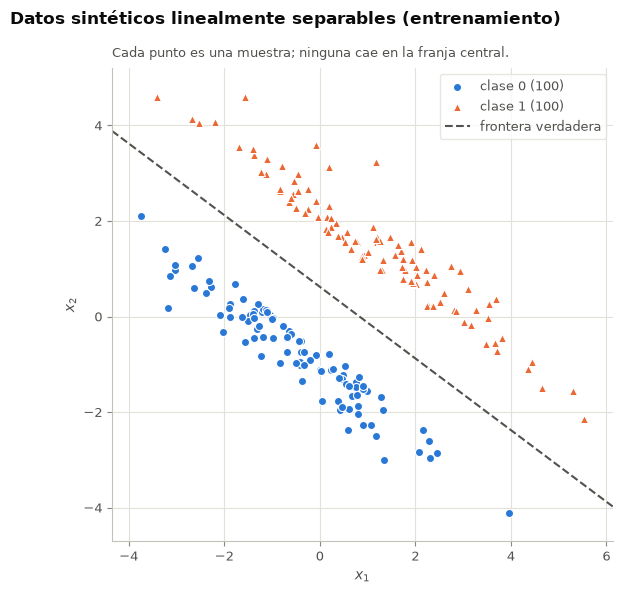

In [9]:
X_synthetic, y_synthetic = make_linearly_separable(n_samples=SYNTHETIC_SAMPLES, seed=SEED)
X_synthetic_test, y_synthetic_test = make_linearly_separable(
    n_samples=SYNTHETIC_SAMPLES, seed=SEED + 1
)
true_boundary = (torch.tensor(SYNTHETIC_TRUE_WEIGHTS), SYNTHETIC_TRUE_BIAS)

show_figure(
    plot_dataset(
        X_synthetic,
        y_synthetic,
        title="Datos sintéticos linealmente separables (entrenamiento)",
        true_boundary=true_boundary,
    )
)

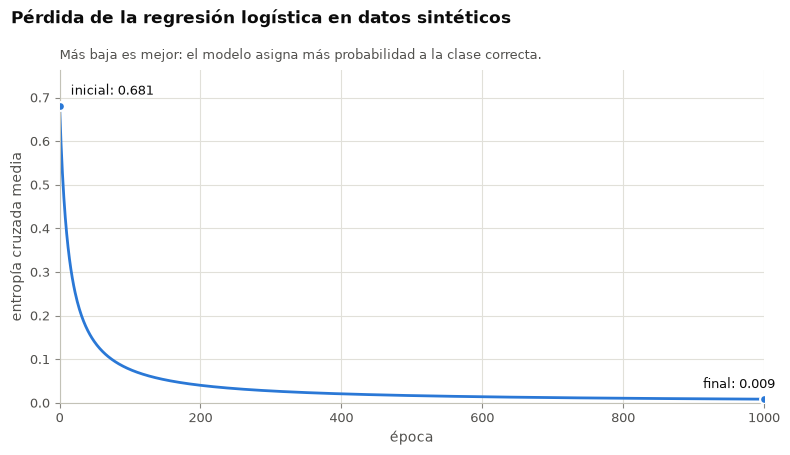

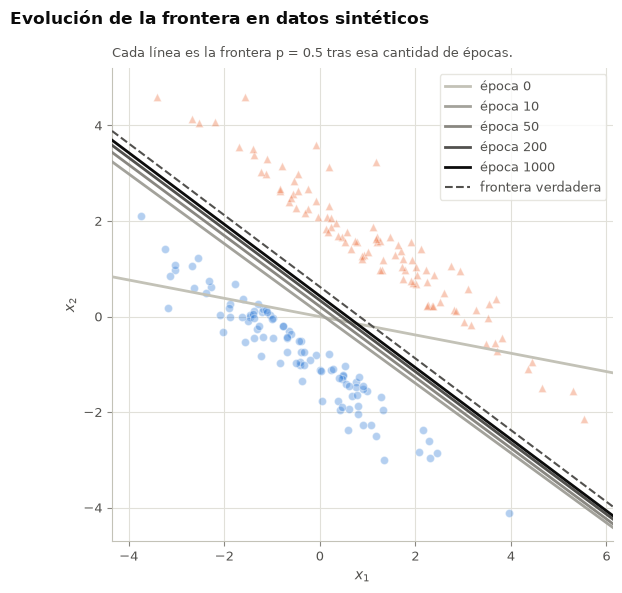

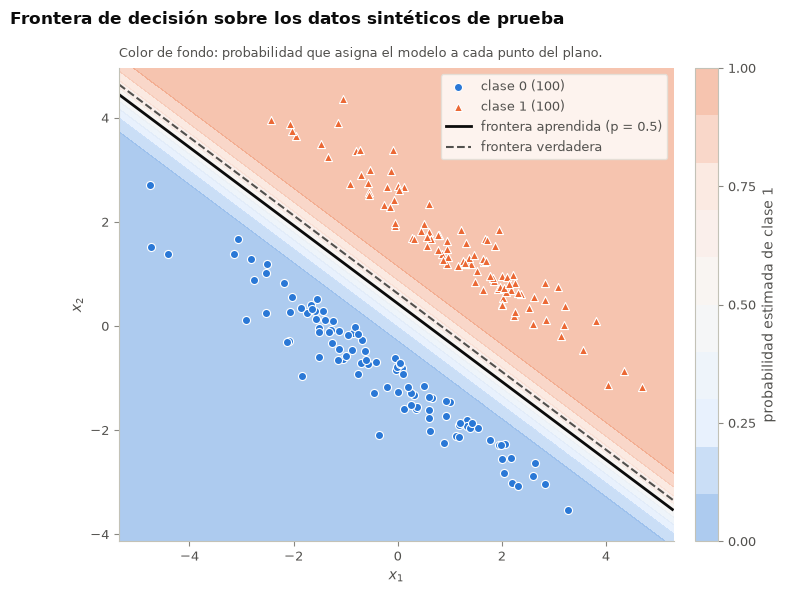

In [10]:
# Con la misma semilla el entrenamiento es determinista, así que entrenar k épocas
# reproduce exactamente el estado del entrenamiento completo en la época k.
synthetic_snapshots = {
    epochs: train_logistic_regression(
        X_synthetic, y_synthetic, SYNTHETIC_LEARNING_RATE, epochs, seed=SEED
    )
    for epochs in SYNTHETIC_SNAPSHOTS
}
synthetic_model = synthetic_snapshots[SYNTHETIC_EPOCHS]

show_figure(
    plot_loss_history(
        synthetic_model, title="Pérdida de la regresión logística en datos sintéticos"
    )
)
show_figure(
    plot_boundary_evolution(
        X_synthetic,
        y_synthetic,
        synthetic_snapshots,
        title="Evolución de la frontera en datos sintéticos",
        true_boundary=true_boundary,
    )
)
show_figure(
    plot_decision_boundary(
        X_synthetic_test,
        y_synthetic_test,
        lambda X: predict_proba(synthetic_model, X),
        title="Frontera de decisión sobre los datos sintéticos de prueba",
        true_boundary=true_boundary,
    )
)

In [11]:
synthetic_evolution = pd.DataFrame(
    {
        epochs: {
            "pérdida": model.loss_history[-1],
            "tasa de aciertos (entrenamiento)": accuracy(
                y_synthetic, predict(model, X_synthetic)
            ),
            **describe_boundary(model, true_boundary),
        }
        for epochs, model in synthetic_snapshots.items()
    }
).T.rename_axis("época")
display_table(
    synthetic_evolution, "Evolución del entrenamiento en datos sintéticos", formats="{:.4f}"
)

synthetic_metrics = pd.DataFrame(
    {
        "entrenamiento": classification_metrics(
            y_synthetic, predict(synthetic_model, X_synthetic)
        ),
        "prueba": classification_metrics(
            y_synthetic_test, predict(synthetic_model, X_synthetic_test)
        ),
    }
).T
display_table(
    synthetic_metrics, "Métricas de la regresión logística en datos sintéticos", formats="{:.4f}"
)

,pérdida,tasa de aciertos (entrenamiento),w1,w2,b,ángulo con la verdadera (°),||w||
época,,,,,,,
0,0.6811,0.9000,0.1883,0.9821,0.0000,26.0157,0.0194
10,0.3884,1.0000,0.5898,0.8076,-0.0541,0.7287,0.5584
50,0.1389,1.0000,0.5957,0.8032,-0.1719,0.3050,1.4931
200,0.0403,1.0000,0.5982,0.8014,-0.2738,0.1296,2.5489
1000,0.0085,1.0000,0.5999,0.8001,-0.3468,0.0087,3.8439


,tasa_aciertos,f1
entrenamiento,1.0000,1.0000
prueba,1.0000,1.0000


**Análisis.** El regresor aprende una frontera separadora casi paralela a la verdadera:

- **Proceso.** En la época 0 los pesos son casi nulos y aleatorios ($\lVert w \rVert = 0.02$): la frontera está girada 26° respecto de la verdadera y acierta el 90 % del entrenamiento. Tras 10 épocas ya acierta el 100 % y el ángulo baja a 0.73°; tras 1000 épocas el ángulo es de 0.009°. La pérdida baja de 0.681 a 0.009 sin oscilar.
- **Generalización.** En los 200 puntos de prueba, generados con otra semilla, la tasa de aciertos y el F1-score también valen 1.
- **$\lVert w \rVert$ crece sin parar** (de 0.02 a 3.84). Con datos separables la pérdida se puede seguir reduciendo haciendo más abrupta la transición de probabilidad, sin cambiar la recta; por eso la franja de colores alrededor de la frontera es angosta en el mapa de probabilidad.
- **El sesgo todavía no coincide.** Normalizado, vale $-0.35$ frente a $-0.5$: la frontera aprendida está desplazada 0.15 hacia la clase 0, pero dentro de la franja vacía de ancho 2, así que clasifica todo bien. Con datos separables hay infinitas rectas que separan perfectamente y el descenso del gradiente se mueve muy despacio hacia la de margen máximo (Soudry et al., 2018); la orientación converge mucho antes que la posición.

### 1.4 Extracción de características y 30 corridas

**Codificador.** `extract_features` convierte cada mensaje original en un vector de `sentence-transformers/all-mpnet-base-v2`, de $D = 768$ dimensiones. Se fija la revisión del modelo y se valida la forma $(n, 768)$, el tipo `float32` y que todos los valores sean finitos. Las características se calculan una sola vez: el codificador preentrenado no se ajusta con los mensajes del dataset.

La caché identifica el modelo, su revisión y el hash SHA-256 de los textos en su orden original. Una caché antigua de MiniLM o incompatible no se reutiliza. Las 768 dimensiones pertenecen a la representación del texto: el archivo de UCI contiene etiquetas y mensajes, no 768 columnas numéricas.

In [12]:
# Definiciones: 1.4, codificador, calibración y métricas por corrida

# ---------------------------------------------------------------------------
# 1.4: extracción de características con el codificador
# ---------------------------------------------------------------------------


def load_encoder(model_name, device="cpu", revision=None):
    """!
    @brief Carga un codificador de oraciones de sentence-transformers.

    Codificador del experimento: `sentence-transformers/all-mpnet-base-v2`,
    que produce vectores de 768 dimensiones. La revisión fija el modelo utilizado.
    La primera llamada descarga el modelo a la caché de Hugging Face.

    @param model_name Identificador del modelo (lo define `ENCODER_NAME` en el notebook).
    @param device Dispositivo de PyTorch donde se ejecuta el codificador.
    @param revision Revisión inmutable del modelo; None usa la revisión por defecto.
    @return Objeto `SentenceTransformer` listo para `extract_features`.
    """
    from sentence_transformers import SentenceTransformer

    return SentenceTransformer(model_name, device=device, revision=revision)


def extract_features(texts, encoder, batch_size=64):
    """!
    @brief Codifica cada mensaje en un vector de características.
    @param texts Lista de mensajes sin preprocesar.
    @param encoder Codificador devuelto por `load_encoder` (cualquier objeto con el método
           `encode` de sentence-transformers).
    @param batch_size Cantidad de mensajes codificados por lote.
    @return Tensor `float32` de forma (n, D), en el mismo orden que `texts`.
    """
    with torch.no_grad():
        embeddings = encoder.encode(
            list(texts), batch_size=batch_size, convert_to_tensor=True, show_progress_bar=False
        )
    return torch.as_tensor(embeddings).detach().to(torch.float32).cpu()


def grid_search_logistic_regression(
    X_fit, y_fit, X_val, y_val, learning_rates, epoch_values, score_fn, seed=None
):
    """!
    @brief Calibra tasas y épocas con trayectorias paralelas y checkpoints de la misma inicialización.
    @param X_fit Características de ajuste, forma (n, D).
    @param y_fit Etiquetas binarias de ajuste.
    @param X_val Características de validación, forma (m, D).
    @param y_val Etiquetas binarias de validación.
    @param learning_rates Tasas positivas que se prueban en paralelo.
    @param epoch_values Épocas no negativas donde se evalúa cada trayectoria.
    @param score_fn Función de puntuación de etiquetas; mayor es mejor.
    @param seed Semilla común de inicialización para todas las combinaciones.
    @return Cuadrícula ordenada por mayor puntaje y menor pérdida de validación.
    """
    X_fit = torch.as_tensor(X_fit)
    if not X_fit.is_floating_point():
        X_fit = X_fit.to(torch.float32)
    X_val = torch.as_tensor(X_val, dtype=X_fit.dtype, device=X_fit.device)
    y_fit = torch.as_tensor(y_fit, dtype=X_fit.dtype, device=X_fit.device)
    y_val = torch.as_tensor(y_val, device=X_fit.device)
    rates = tuple(float(rate) for rate in learning_rates)
    checkpoints = sorted(set(int(epoch) for epoch in epoch_values))
    if not rates or any(not np.isfinite(rate) or rate <= 0 for rate in rates):
        raise ValueError("La cuadrícula necesita tasas positivas y finitas.")
    if not checkpoints or checkpoints[0] < 0:
        raise ValueError("La cuadrícula necesita épocas no negativas.")
    if X_fit.ndim != 2 or y_fit.shape != (len(X_fit),) or len(X_fit) == 0:
        raise ValueError("Se requiere X_fit (n, D) e y_fit (n,) con n positivo.")
    n_features = X_fit.shape[1]
    initial = 0.01 * torch.randn(n_features, generator=_generator(seed), dtype=X_fit.dtype)
    weights = initial.to(X_fit.device)[:, None].expand(-1, len(rates)).clone()
    bias = torch.zeros(len(rates), dtype=X_fit.dtype, device=X_fit.device)
    rate_tensor = torch.tensor(rates, dtype=X_fit.dtype, device=X_fit.device)
    rows = []
    with torch.no_grad():
        for epoch in range(checkpoints[-1] + 1):
            if epoch in checkpoints:
                logits = X_val @ weights + bias
                validation_losses = (
                    logits.clamp(min=0) + torch.log1p(torch.exp(-logits.abs()))
                    - y_val.to(X_fit.dtype)[:, None] * logits
                ).mean(dim=0)
                fit_logits = X_fit @ weights + bias
                train_losses = (
                    fit_logits.clamp(min=0) + torch.log1p(torch.exp(-fit_logits.abs()))
                    - y_fit[:, None] * fit_logits
                ).mean(dim=0)
                predictions = (_sigmoid(logits) >= 0.5).to(torch.int64)
                for column, rate in enumerate(rates):
                    rows.append({
                        "learning_rate": rate, "epochs": epoch,
                        "score": float(score_fn(y_val, predictions[:, column])),
                        "validation_loss": float(validation_losses[column]),
                        "train_loss": float(train_losses[column]),
                    })
            if epoch < checkpoints[-1]:
                error = _sigmoid(X_fit @ weights + bias) - y_fit[:, None]
                weights = weights - (X_fit.T @ error) * rate_tensor / len(X_fit)
                bias = bias - rate_tensor * error.mean(dim=0)
    return pd.DataFrame(rows).sort_values(
        ["score", "validation_loss"], ascending=[False, True], kind="stable"
    ).reset_index(drop=True)


def plot_calibration(
    grid,
    title="Calibración de la regresión logística",
    score_label="F1 en validación",
    color_span=0.05,
):
    """!
    @brief Grafica el puntaje de validación de cada combinación como un mapa de calor.

    Cada celda muestra el puntaje; la celda recuadrada es la combinación elegida
    (la primera fila de `grid`). La escala de color cubre solo los puntajes
    cercanos al mejor (hasta `color_span` por debajo), para que se distingan las
    diferencias que deciden la elección; los puntajes menores quedan en el tono
    más claro y la barra de color lo indica con una flecha.

    @param grid DataFrame devuelto por `grid_search_logistic_regression`.
    @param title Título de la figura.
    @param score_label Nombre del puntaje para la barra de color.
    @param color_span Ancho del rango de puntajes que cubre la escala de color.
    @return Figura de Matplotlib (sin mostrar).
    """
    table = grid.pivot(index="learning_rate", columns="epochs", values="score").sort_index()
    values = table.to_numpy()
    high = np.nanmax(values)
    low = max(np.nanmin(values), high - color_span)
    colormap = LinearSegmentedColormap.from_list("puntaje", _BLUE_RAMP)
    figure, axis = plt.subplots(figsize=(1.3 * table.shape[1] + 2.6, 0.62 * table.shape[0] + 1.9))
    _style_axis(axis, grid=False)
    image = axis.imshow(values, cmap=colormap, aspect="auto", vmin=low, vmax=high)

    # Texto blanco solo sobre los tonos oscuros de la rampa, para que se lea en todas las celdas.
    dark_from = low + 0.6 * (high - low)
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            axis.text(
                column, row, f"{values[row, column]:.3f}", ha="center", va="center", fontsize=9,
                color=_SURFACE if values[row, column] >= dark_from else _INK,
            )
    best = grid.iloc[0]
    best_row = list(table.index).index(best["learning_rate"])
    best_column = list(table.columns).index(best["epochs"])
    # La mejor celda es la más oscura, así que su recuadro va en blanco.
    axis.add_patch(
        plt.Rectangle(
            (best_column - 0.46, best_row - 0.44), 0.92, 0.88, fill=False, edgecolor=_SURFACE,
            linewidth=3,
        )
    )

    axis.set_xticks(range(table.shape[1]), [str(value) for value in table.columns])
    axis.set_yticks(range(table.shape[0]), [f"{value:g}" for value in table.index])
    axis.set_xlabel("épocas")
    axis.set_ylabel("tasa de aprendizaje")
    for side in ("left", "bottom"):
        axis.spines[side].set_visible(False)
    colorbar = figure.colorbar(
        image, ax=axis, fraction=0.046, pad=0.03, extend="min" if low > np.nanmin(values) else "neither"
    )
    colorbar.set_label(score_label, color=_INK_SECONDARY)
    colorbar.ax.tick_params(colors=_INK_MUTED, labelcolor=_INK_SECONDARY, labelsize=9)
    colorbar.outline.set_edgecolor(_AXIS)
    subtitle = (
        f"Recuadro blanco: combinación elegida (tasa {best['learning_rate']:g}, "
        f"{int(best['epochs'])} épocas). El color distingue los puntajes más altos."
    )
    _set_titles(figure, axis, title, subtitle)
    figure.tight_layout()
    return figure


def plot_run_metrics(runs, title="Métricas en las 30 corridas", metrics=None):
    """!
    @brief Grafica el valor de cada métrica en cada corrida, con su media y desviación.

    Cada punto es una corrida (partición distinta). La barra negra marca la
    media y el texto muestra media ± desviación estándar.

    @param runs DataFrame de `repeat_experiment` con una columna por métrica.
    @param title Título de la figura.
    @param metrics Lista opcional de pares `(columna, nombre visible)`; por omisión, la
           tasa de aciertos y el F1-score.
    @return Figura de Matplotlib (sin mostrar).
    """
    metrics = metrics or [("tasa_aciertos", "tasa de aciertos"), ("f1", "F1-score")]
    offsets = np.random.default_rng(0).uniform(-0.12, 0.12, len(runs))
    figure, axis = plt.subplots(figsize=(7.6, 5.0))
    _style_axis(axis)
    axis.grid(axis="x", visible=False)
    low, high = 1.0, 0.0
    for position, (column, _) in enumerate(metrics):
        values = runs[column].to_numpy(dtype=float)
        low, high = min(low, values.min()), max(high, values.max())
        axis.scatter(
            position + offsets, values, s=36, color=_CLASS_COLORS[0], alpha=0.8,
            edgecolors=_SURFACE, linewidths=1.2, zorder=3,
        )
        mean, std = values.mean(), values.std(ddof=1)
        axis.plot(
            [position - 0.25, position + 0.25], [mean, mean], color=_INK, linewidth=2.5, zorder=4
        )
        axis.annotate(
            f"media {mean:.3f}\n± {std:.3f}", (position + 0.27, mean), xytext=(4, 0),
            textcoords="offset points", va="center", fontsize=9, color=_INK,
        )
    span = max(high - low, 0.01)
    axis.set_ylim(low - 0.25 * span, min(high + 0.25 * span, 1.0 + 0.05 * span))
    axis.set_xlim(-0.5, len(metrics) - 0.2)
    axis.set_xticks(range(len(metrics)), [name for _, name in metrics])
    axis.set_ylabel("valor en la partición de prueba")
    subtitle = f"Cada punto es una de las {len(runs)} corridas; la barra negra es la media."
    _set_titles(figure, axis, title, subtitle)
    figure.tight_layout()
    return figure


def plot_confusion_matrix(runs, title="Matriz de confusión promedio", class_names=("ham", "spam")):
    """!
    @brief Grafica la matriz de confusión promedio de varias corridas.

    Filas: clase real; columnas: clase predicha. Cada celda muestra la cantidad
    media de mensajes por corrida y el porcentaje de su fila; el color sigue a
    ese porcentaje, de modo que la diagonal oscura indica aciertos.

    @param runs DataFrame con las columnas `tn`, `fp`, `fn` y `tp` (una fila por corrida).
    @param title Título de la figura.
    @param class_names Nombres de las clases negativa y positiva.
    @return Figura de Matplotlib (sin mostrar).
    """
    counts = np.array(
        [[runs["tn"].mean(), runs["fp"].mean()], [runs["fn"].mean(), runs["tp"].mean()]]
    )
    percentages = 100 * counts / counts.sum(axis=1, keepdims=True)
    colormap = LinearSegmentedColormap.from_list("porcentaje", _BLUE_RAMP)
    figure, axis = plt.subplots(figsize=(6.4, 5.2))
    _style_axis(axis, grid=False)
    image = axis.imshow(percentages, cmap=colormap, vmin=0, vmax=100)
    for row in range(2):
        for column in range(2):
            axis.text(
                column, row, f"{counts[row, column]:.1f}\n({percentages[row, column]:.1f} %)",
                ha="center", va="center", fontsize=11,
                color=_SURFACE if percentages[row, column] > 55 else _INK,
            )
    axis.set_xticks([0, 1], [f"predicho: {name}" for name in class_names])
    axis.set_yticks([0, 1], [f"real: {name}" for name in class_names])
    for side in ("left", "bottom"):
        axis.spines[side].set_visible(False)
    axis.tick_params(length=0)
    colorbar = figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
    colorbar.set_label("% de los mensajes de la clase real", color=_INK_SECONDARY)
    colorbar.ax.tick_params(colors=_INK_MUTED, labelcolor=_INK_SECONDARY, labelsize=9)
    colorbar.outline.set_edgecolor(_AXIS)
    subtitle = f"Mensajes por corrida en la prueba, promedio de {len(runs)} corridas."
    _set_titles(figure, axis, title, subtitle)
    figure.tight_layout()
    return figure

In [13]:
# Definiciones: calibración interna y caché verificada de características.
import hashlib
import json


def feature_cache_metadata(texts, encoder_name, expected_dimensions, revision=None):
    """!
    @brief Identifica el codificador y los textos ordenados de una caché de características.
    @param texts Mensajes originales en el orden que se desea codificar.
    @param encoder_name Identificador del codificador.
    @param expected_dimensions Dimensión esperada de cada embedding.
    @param revision Revisión inmutable del codificador, si se especifica.
    @return Diccionario de metadatos con hash SHA-256, modelo, revisión, forma y tipo.
    """
    serialized = json.dumps(list(texts), ensure_ascii=False, separators=(",", ":"))
    return {
        "format_version": 2,
        "texts_sha256": hashlib.sha256(serialized.encode("utf-8")).hexdigest(),
        "encoder_name": str(encoder_name),
        "encoder_revision": revision,
        "n_messages": len(texts),
        "dimensions": int(expected_dimensions),
        "dtype": "float32",
    }


def feature_cache_is_valid(payload, metadata):
    """!
    @brief Verifica que una caché corresponde a los textos, modelo, forma y tipo requeridos.
    @param payload Objeto leído de la caché; debe contener metadatos y características.
    @param metadata Identidad esperada generada por feature_cache_metadata.
    @return Verdadero si la caché coincide y su tensor es finito, float32 y de forma (n, D).
    """
    if not isinstance(payload, dict) or payload.get("metadata") != metadata:
        return False
    embeddings = payload.get("features")
    return (
        isinstance(embeddings, torch.Tensor)
        and embeddings.dtype == torch.float32
        and embeddings.shape == (metadata["n_messages"], metadata["dimensions"])
        and bool(torch.isfinite(embeddings).all())
    )


def _pca_for_training_indices(features, indices, cache=None):
    """!
    @brief Ajusta PCA solo con los índices de entrenamiento y permite reutilizarlo para varios k.
    @param features Matriz original de características.
    @param indices Índices exclusivos del conjunto que ajusta el PCA.
    @param cache Diccionario opcional de modelos; se comparte solo dentro del mismo experimento.
    @return PCA completo ajustado exclusivamente con las filas indicadas.
    """
    key = tuple(int(index) for index in indices)
    if cache is not None and key in cache:
        return cache[key]
    model = fit_pca(features[indices], min(len(indices), features.shape[1]))
    if cache is not None:
        cache[key] = model
    return model


def calibrate_training_partition(
    features, targets, train_indices, learning_rates, epoch_values,
    validation_fraction=0.2, seed=None, n_components=None, pca_cache=None,
):
    """!
    @brief Calibra la regresión usando una validación extraída solo del entrenamiento actual.
    @param features Matriz de características originales, forma (n, D).
    @param targets Etiquetas binarias en el orden del dataset.
    @param train_indices Índices del 70 % de entrenamiento de la corrida actual.
    @param learning_rates Tasas de aprendizaje de la cuadrícula.
    @param epoch_values Épocas de la cuadrícula.
    @param validation_fraction Parte del entrenamiento reservada para validación.
    @param seed Semilla de la partición interna y de la inicialización.
    @param n_components Componentes del PCA; None conserva las características originales.
    @param pca_cache Caché opcional de ajustes PCA para reutilizarlos entre valores de k.
    @return Cuadrícula ordenada por mayor F1 y, entre empates, menor pérdida de validación.
    """
    fit_positions, validation_positions = stratified_split(
        targets[train_indices], 1 - validation_fraction, seed
    )
    fit_indices = train_indices[fit_positions]
    validation_indices = train_indices[validation_positions]
    X_fit, X_validation = features[fit_indices], features[validation_indices]
    if n_components is not None:
        pca_model = _pca_for_training_indices(features, fit_indices, pca_cache)
        X_fit = transform_pca(pca_model, X_fit)[:, :n_components]
        X_validation = transform_pca(pca_model, X_validation)[:, :n_components]
    return grid_search_logistic_regression(
        X_fit, targets[fit_indices], X_validation, targets[validation_indices],
        learning_rates, epoch_values, f1_score, seed=seed,
    )


def calibrated_logistic_regression_run(
    features, targets, seed, learning_rates, epoch_values,
    train_fraction=0.7, validation_fraction=0.2, n_components=None, pca_cache=None,
):
    """!
    @brief Calibra y evalúa una corrida sin que la prueba influya en PCA o hiperparámetros.
    @param features Matriz de características originales, forma (n, D).
    @param targets Etiquetas binarias en el orden del dataset.
    @param seed Semilla de la corrida.
    @param learning_rates Tasas candidatas para la calibración interna.
    @param epoch_values Épocas candidatas para la calibración interna.
    @param train_fraction Fracción estratificada usada como entrenamiento externo.
    @param validation_fraction Fracción del entrenamiento reservada para validación interna.
    @param n_components Componentes del PCA; None usa las características originales.
    @param pca_cache Caché opcional de ajustes PCA del mismo dataset y experimento.
    @return Métricas y confusión de prueba, más tasa y épocas elegidas en validación interna.
    """
    train_indices, test_indices = stratified_split(targets, train_fraction, seed)
    grid = calibrate_training_partition(
        features, targets, train_indices, learning_rates, epoch_values,
        validation_fraction, seed, n_components, pca_cache,
    )
    best = grid.iloc[0]
    X_train, X_test = features[train_indices], features[test_indices]
    if n_components is not None:
        pca_model = _pca_for_training_indices(features, train_indices, pca_cache)
        X_train = transform_pca(pca_model, X_train)[:, :n_components]
        X_test = transform_pca(pca_model, X_test)[:, :n_components]
    model = train_logistic_regression(
        X_train, targets[train_indices], float(best.learning_rate), int(best.epochs), seed=seed
    )
    predictions = predict(model, X_test)
    return {
        **classification_metrics(targets[test_indices], predictions),
        **confusion_counts(targets[test_indices], predictions),
        "learning_rate": float(best.learning_rate),
        "epochs": int(best.epochs),
    }


def only_metrics(results):
    """!
    @brief Selecciona las métricas de clasificación para comparar métodos sin mezclar metadatos.
    @param results Diccionario de DataFrame por método.
    @return Diccionario con solo tasa_aciertos y f1 para cada método.
    """
    return {name: runs[["tasa_aciertos", "f1"]] for name, runs in results.items()}


In [14]:
cache_metadata = feature_cache_metadata(
    texts, ENCODER_NAME, EXPECTED_EMBEDDING_DIMENSIONS, ENCODER_REVISION
)
cache_key = hashlib.sha256(
    json.dumps(cache_metadata, sort_keys=True).encode("utf-8")
).hexdigest()[:16]
features_path = PROCESSED_DIRECTORY / f"features-{cache_key}.pt"
cache_payload = None
if features_path.exists():
    try:
        cache_payload = torch.load(features_path, weights_only=True, map_location="cpu")
    except (OSError, RuntimeError, EOFError):
        print("Caché ilegible: se volverán a codificar los mensajes.")

if feature_cache_is_valid(cache_payload, cache_metadata):
    features = cache_payload["features"]
else:
    encoder = load_encoder(ENCODER_NAME, revision=ENCODER_REVISION)
    if encoder.get_embedding_dimension() != EXPECTED_EMBEDDING_DIMENSIONS:
        raise ValueError("El codificador no produce las 768 dimensiones esperadas.")
    features = extract_features(texts, encoder)
    cache_payload = {"metadata": cache_metadata, "features": features}
    if not feature_cache_is_valid(cache_payload, cache_metadata):
        raise ValueError("Características incompatibles: revisar forma, tipo y valores finitos.")
    PROCESSED_DIRECTORY.mkdir(parents=True, exist_ok=True)
    torch.save(cache_payload, features_path)

norms = features.norm(dim=1)
print(f"Características: {tuple(features.shape)}; norma entre {norms.min():.4f} y {norms.max():.4f}")
print(f"Codificador: {ENCODER_NAME}; revisión: {ENCODER_REVISION}; hash textos: {cache_metadata['texts_sha256']}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Características: (5574, 768); norma entre 1.0000 y 1.0000
Codificador: sentence-transformers/all-mpnet-base-v2; revisión: e8c3b32edf5434bc2275fc9bab85f82640a19130; hash textos: ec071a543cbf3557b09ddd7724127409b50934f790028a830d9a8a0c189f4a3f


#### Calibración de la tasa de aprendizaje y las épocas

**Cada corrida tiene su propia validación interna.** Se toma su 70 % de entrenamiento y se separa de él un 20 % estratificado para validación; el 80 % restante ajusta cada candidato. La cuadrícula conserva tasas de 0.1 a 50 y de 250 a 4000 épocas. Se selecciona automáticamente el mayor F1 de validación; los empates se resuelven con la menor entropía cruzada de validación. El modelo elegido vuelve a entrenarse con todo el 70 % antes de evaluar el 30 % de prueba.

La figura siguiente muestra la primera corrida como ejemplo. Su selección no se reutiliza en las otras 29. Así se evita que los mensajes de validación de una partición influyan en la selección de modelos cuya prueba los contiene en otra partición.

Para reducir el costo, las tasas se entrenan en paralelo con la misma inicialización y cada cantidad de épocas se evalúa como checkpoint de su trayectoria. Esto conserva la cuadrícula y las actualizaciones propias de descenso del gradiente; una prueba contrasta los resultados con entrenamientos independientes.

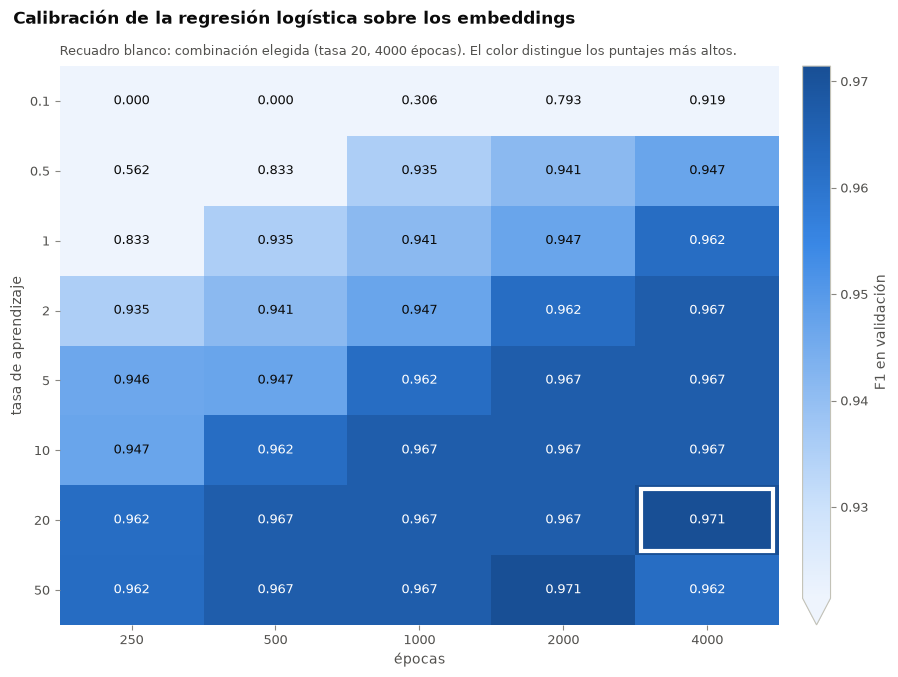

,tasa de aprendizaje,épocas,F1 en validación,pérdida en validación,pérdida en ajuste
0,20,4000,0.9714,0.0403,0.0061
1,50,2000,0.9714,0.0411,0.0050
2,10,4000,0.9668,0.0394,0.0108
3,20,2000,0.9668,0.0394,0.0108
4,50,1000,0.9668,0.0399,0.0090


Primera corrida: tasa 20 y 4000 épocas (F1 en validación 0.9714). Cada corrida vuelve a calibrar dentro de su entrenamiento.


In [15]:
calibration_train, _ = stratified_split(targets, TRAIN_FRACTION, SEED)
calibration_grid = calibrate_training_partition(
    features, targets, calibration_train,
    LR_CALIBRATION_LEARNING_RATES, LR_CALIBRATION_EPOCHS,
    LR_VALIDATION_FRACTION, SEED,
)
show_figure(
    plot_calibration(
        calibration_grid, title="Calibración de la regresión logística sobre los embeddings"
    )
)
display_table(
    calibration_grid.head(5).rename(
        columns={
            "learning_rate": "tasa de aprendizaje",
            "epochs": "épocas",
            "score": "F1 en validación",
            "validation_loss": "pérdida en validación",
            "train_loss": "pérdida en ajuste",
        }
    ),
    "Mejores combinaciones de la calibración",
    formats={
        "tasa de aprendizaje": "{:g}",
        "F1 en validación": "{:.4f}",
        "pérdida en validación": "{:.4f}",
        "pérdida en ajuste": "{:.4f}",
    },
)

best = calibration_grid.iloc[0]
print(
    f"Primera corrida: tasa {best.learning_rate:g} y {int(best.epochs)} épocas "
    f"(F1 en validación {best.score:.4f}). Cada corrida vuelve a calibrar dentro de su entrenamiento."
)

#### 30 corridas con particiones 70/30

Cada corrida usa una partición estratificada distinta (semilla `SEED + k - 1`), calibra con su propia validación interna, vuelve a entrenar en su 70 % completo y evalúa en su 30 % de prueba. Guarda la tasa de aciertos, el F1-score, la matriz de confusión y los hiperparámetros elegidos. Las tablas comparativas seleccionan solo las métricas para no mezclar hiperparámetros o conteos con resultados de clasificación.

Sin PCA: corrida 1/30; F1=0.9683
Sin PCA: corrida 2/30; F1=0.9635
Sin PCA: corrida 3/30; F1=0.9587
Sin PCA: corrida 4/30; F1=0.9680
Sin PCA: corrida 5/30; F1=0.9657
Sin PCA: corrida 6/30; F1=0.9565
Sin PCA: corrida 7/30; F1=0.9541
Sin PCA: corrida 8/30; F1=0.9611
Sin PCA: corrida 9/30; F1=0.9635
Sin PCA: corrida 10/30; F1=0.9657
Sin PCA: corrida 11/30; F1=0.9682
Sin PCA: corrida 12/30; F1=0.9689
Sin PCA: corrida 13/30; F1=0.9635
Sin PCA: corrida 14/30; F1=0.9573
Sin PCA: corrida 15/30; F1=0.9565
Sin PCA: corrida 16/30; F1=0.9550
Sin PCA: corrida 17/30; F1=0.9726
Sin PCA: corrida 18/30; F1=0.9655
Sin PCA: corrida 19/30; F1=0.9726
Sin PCA: corrida 20/30; F1=0.9611
Sin PCA: corrida 21/30; F1=0.9776
Sin PCA: corrida 22/30; F1=0.9705
Sin PCA: corrida 23/30; F1=0.9519
Sin PCA: corrida 24/30; F1=0.9692
Sin PCA: corrida 25/30; F1=0.9635
Sin PCA: corrida 26/30; F1=0.9611
Sin PCA: corrida 27/30; F1=0.9593
Sin PCA: corrida 28/30; F1=0.9730
Sin PCA: corrida 29/30; F1=0.9620
Sin PCA: corrida 30/30;

,media,desviación,mínimo,máximo
tasa_aciertos,0.9906,0.0016,0.9874,0.9940
f1,0.9641,0.0063,0.9519,0.9776


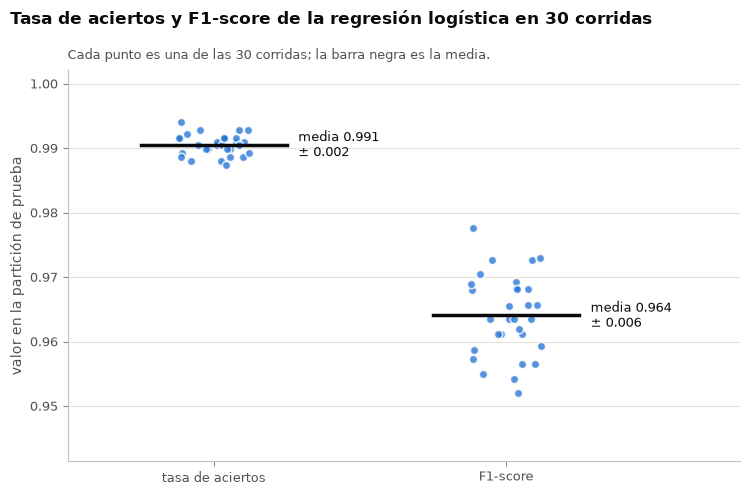

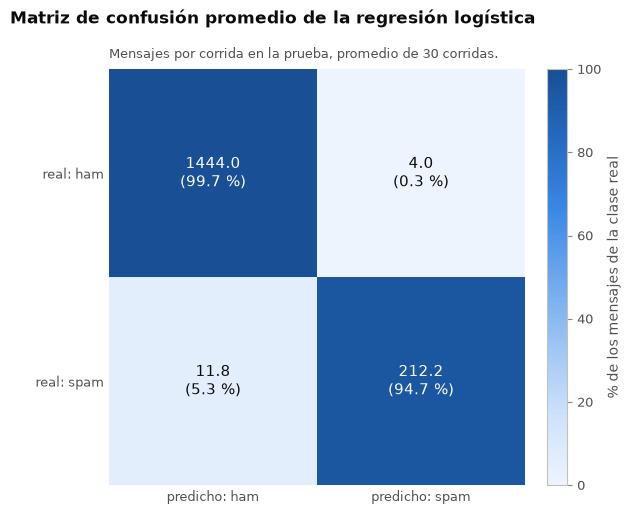

,corrida,semilla,learning_rate,epochs
0,1,2026,20,4000
1,2,2027,20,4000
2,3,2028,20,500
3,4,2029,50,500
4,5,2030,20,4000
5,6,2031,20,500
6,7,2032,20,2000
7,8,2033,10,1000
8,9,2034,50,2000
9,10,2035,50,1000


In [16]:
from functools import partial

# Cada corrida recibe los datos y calibra con su propia validación interna.
pca_experiment_cache = {}
logistic_regression_run = partial(
    calibrated_logistic_regression_run,
    features, targets,
    learning_rates=LR_CALIBRATION_LEARNING_RATES,
    epoch_values=LR_CALIBRATION_EPOCHS,
    train_fraction=TRAIN_FRACTION,
    validation_fraction=LR_VALIDATION_FRACTION,
    pca_cache=pca_experiment_cache,
)

def baseline_with_progress(seed):
    """!
    @brief Ejecuta y anuncia una corrida del modelo sin PCA.
    @param seed Semilla de la corrida.
    @return Métricas, confusión e hiperparámetros elegidos.
    """
    result = logistic_regression_run(seed)
    print(f"Sin PCA: corrida {seed - SEED + 1}/{N_RUNS}; F1={result['f1']:.4f}", flush=True)
    return result

baseline_name = f"RL (D = {features.shape[1]})"
classification_results = {
    baseline_name: repeat_experiment(baseline_with_progress, n_runs=N_RUNS, base_seed=SEED)
}
baseline_runs = classification_results[baseline_name]

display_table(
    summarize_runs(baseline_runs[METRIC_COLUMNS]),
    "Regresión logística con las características del codificador (30 corridas)",
    formats="{:.4f}",
)
show_figure(
    plot_run_metrics(
        baseline_runs, title="Tasa de aciertos y F1-score de la regresión logística en 30 corridas"
    )
)
show_figure(
    plot_confusion_matrix(
        baseline_runs, title="Matriz de confusión promedio de la regresión logística"
    )
)
display_table(
    baseline_runs[["corrida", "semilla", "learning_rate", "epochs"]],
    "Hiperparámetros elegidos dentro de cada corrida sin PCA",
    formats={"learning_rate": "{:g}", "epochs": "{:.0f}"},
)

**Análisis (MPNet, 768 dimensiones).** Las 30 corridas con calibración interna dan una tasa de aciertos de **0.9906 ± 0.0016** y F1 de **0.9641 ± 0.0063** (media ± desviación muestral). El F1 varía entre 0.9519 y 0.9776. Se ejecutó esta evaluación antes de la demostración 1.3: no necesita sus datos, modelos ni hiperparámetros.

La primera validación eligió tasa 20 y 4000 épocas, con F1 de validación 0.9714. Cada corrida aplica su propia elección: las tasas seleccionadas fueron 10 en 6 corridas, 20 en 10 y 50 en 14; 15 corridas eligieron 4000 épocas. Algunas elecciones alcanzan el borde de la cuadrícula, por lo que describimos el mejor candidato probado y no un óptimo global. El conjunto de prueba no interviene en esa selección.

Estos resultados reemplazan el estado anterior con MiniLM/384. Como cambiaron tanto el codificador como el protocolo de calibración, la diferencia no permite atribuir una mejora únicamente al codificador. Además, las particiones son por filas y pueden compartir textos idénticos de UCI entre entrenamiento y prueba; las métricas deben interpretarse con esa limitación.

### 1.5 Reducción de dimensionalidad con PCA

`fit_pca` centra los embeddings y obtiene las componentes mediante `torch.linalg.svd`; `transform_pca` proyecta restando la media del ajuste. El signo de cada componente se fija con su coordenada de mayor valor absoluto para mejorar la reproducibilidad de las figuras.

Con $D = 768$, se conservan 384 componentes (50 %), 192 (25 %) y 2 dimensiones.

- **Figuras.** Un PCA sobre todos los mensajes se usa exclusivamente para visualizar. Con 2 dimensiones se muestran todos los mensajes en el plano. Con 192 y 384, un segundo panel muestra la separación entre clases por componente con $|d|$ de Cohen.
- **Calibración.** Cada valor de $k$ y cada corrida usan una validación tomada solo de su propio entrenamiento. El PCA de calibración se ajusta solo con la parte interna de ajuste y se aplica a la validación interna.
- **Evaluación.** Seleccionados tasa y épocas, se vuelve a ajustar PCA con todo el 70 % de entrenamiento; se entrenan los parámetros del regresor y se evalúa el 30 % de prueba. Las 30 particiones coinciden con las usadas sin PCA, para comparar las diferencias corrida a corrida.
- **Reutilización.** Para distintos valores de $k$, se conserva el PCA completo de cada conjunto de ajuste y se seleccionan sus primeras componentes. La caché se limita a este dataset y ejecución; no mezcla conjuntos de entrenamiento distintos.

In [17]:
# Definiciones: 1.5, PCA y visualización de proyecciones

# ---------------------------------------------------------------------------
# 1.5: reducción de dimensionalidad con PCA
# ---------------------------------------------------------------------------


@dataclass
class PCAModel:
    """!
    @brief Resultado del ajuste de un PCA.
    """

    ## Media de los datos de ajuste, forma (D,).
    mean: torch.Tensor
    ## Componentes principales en columnas, forma (D, k).
    components: torch.Tensor
    ## Varianza explicada por cada componente, forma (k,).
    explained_variance: torch.Tensor
    ## Fracción de la varianza total explicada por cada componente, forma (k,).
    explained_variance_ratio: torch.Tensor


def components_for_fraction(n_features, fraction):
    """!
    @brief Traduce un porcentaje de dimensiones (50 %, 25 %) en una cantidad de componentes.
    @param n_features Dimensión original D.
    @param fraction Fracción de D que se conserva, en (0, 1].
    @return Cantidad de componentes, al menos 1.
    """
    if not 0.0 < fraction <= 1.0:
        raise ValueError("fraction debe estar en el intervalo (0, 1].")
    return max(1, round(n_features * fraction))


def fit_pca(X, n_components):
    """!
    @brief Ajusta un PCA sobre `X`.

    Centra los datos con su media y obtiene los componentes con la
    descomposición en valores singulares de la matriz centrada
    (`torch.linalg.svd`): las filas de V^T son las direcciones de máxima
    varianza, ordenadas de mayor a menor. El cálculo se hace en `float64` para
    que la varianza de los últimos componentes no se pierda por redondeo.

    El signo de cada componente es arbitrario en la SVD; se fija para que su
    coordenada de mayor valor absoluto sea positiva, de modo que el resultado
    (y las figuras) sea el mismo en cualquier máquina.

    En las corridas se ajusta solo con el entrenamiento y se aplica a la
    prueba, para no filtrar información del conjunto de prueba.

    @param X Tensor de forma (n, D).
    @param n_components Cantidad k de componentes que se conservan.
    @return PCAModel con media, componentes y varianza explicada.
    """
    X = torch.as_tensor(X)
    if X.ndim != 2:
        raise ValueError("X debe tener forma (n, D).")
    n_samples, n_features = X.shape
    if not 1 <= n_components <= min(n_samples, n_features):
        raise ValueError(f"n_components debe estar entre 1 y {min(n_samples, n_features)}.")

    data = X.to(torch.float64)
    mean = data.mean(dim=0)
    _, singular_values, vh = torch.linalg.svd(data - mean, full_matrices=False)
    components = vh[:n_components].T
    largest = components.abs().argmax(dim=0)
    signs = torch.sign(components[largest, torch.arange(n_components)])
    components = components * signs

    variance = singular_values**2 / max(n_samples - 1, 1)
    return PCAModel(
        mean=mean.to(torch.float32),
        components=components.to(torch.float32),
        explained_variance=variance[:n_components].to(torch.float32),
        explained_variance_ratio=(variance[:n_components] / variance.sum()).to(torch.float32),
    )


def transform_pca(model, X):
    """!
    @brief Proyecta `X` sobre los componentes del modelo.

    Resta la media del ajuste (no la de `X`), así la prueba se proyecta con lo
    aprendido del entrenamiento.

    @param model PCAModel ajustado.
    @param X Tensor de forma (n, D).
    @return Tensor de forma (n, k).
    """
    X = torch.as_tensor(X, dtype=torch.float32)
    if X.ndim != 2 or X.shape[1] != model.mean.shape[0]:
        raise ValueError(f"X debe tener forma (n, {model.mean.shape[0]}).")
    return (X - model.mean) @ model.components


def plot_explained_variance(model, title="Varianza explicada por componente"):
    """!
    @brief Grafica la varianza explicada individual y acumulada.

    A la izquierda, el porcentaje de la varianza total que explica cada
    componente; a la derecha, el porcentaje acumulado. En la curva acumulada se
    marcan los tres casos del apartado 1.5 (2 dimensiones, 25 % y 50 % de D)
    que caben en el modelo.

    @param model PCAModel ajustado.
    @param title Título de la figura.
    @return Figura de Matplotlib (sin mostrar).
    """
    ratio = 100 * model.explained_variance_ratio.detach().cpu().numpy().astype(float)
    cumulative = np.cumsum(ratio)
    n_components = len(ratio)
    n_features = model.mean.shape[0]
    positions = np.arange(1, n_components + 1)

    figure, (individual, accumulated) = plt.subplots(1, 2, figsize=(12.0, 4.8))
    for axis in (individual, accumulated):
        _style_axis(axis)
        axis.set_xlim(0, n_components + 1)
        axis.set_xlabel("componente principal")

    individual.bar(positions, ratio, width=1.0, color=_BLUE_RAMP[4], linewidth=0)
    individual.set_ylabel("% de la varianza total")
    individual.set_ylim(0, ratio.max() * 1.12)
    individual.annotate(
        f"componente 1: {ratio[0]:.1f} %", (1, ratio[0]), xytext=(10, -2),
        textcoords="offset points", va="top", fontsize=9, color=_INK,
    )

    accumulated.plot(positions, cumulative, color=_BLUE_RAMP[5], linewidth=2)
    accumulated.set_ylabel("% acumulado de la varianza total")
    accumulated.set_ylim(0, 100)
    cases = {2: "2 dimensiones"}
    cases.setdefault(components_for_fraction(n_features, 0.25), "25 % de D")
    cases.setdefault(components_for_fraction(n_features, 0.5), "50 % de D")
    for k, name in sorted(cases.items()):
        if k > n_components:
            continue
        value = cumulative[k - 1]
        accumulated.scatter(k, value, s=40, color=_INK, edgecolors=_SURFACE, linewidths=1.5, zorder=3)
        # La curva es creciente: la etiqueta del primer punto va abajo a la derecha y las
        # demás arriba a la izquierda, siempre del lado donde no pasa la curva.
        first = k == min(cases)
        accumulated.annotate(
            f"{name} (k = {k}): {value:.1f} %", (k, value),
            xytext=(8, -14) if first else (-6, 8), textcoords="offset points", fontsize=9,
            color=_INK, ha="left" if first else "right", va="baseline" if first else "bottom",
        )

    _set_titles(figure, individual, title, "Varianza que explica cada componente.")
    accumulated.set_title(
        "Varianza acumulada; los puntos son los casos del apartado 1.5.",
        loc="left", fontsize=9, color=_INK_SECONDARY, pad=8,
    )
    figure.tight_layout()
    return figure


def _class_separation(X, y):
    """!
    @brief Mide cuánto separa cada columna a las dos clases (|d| de Cohen).

    Para cada columna, la diferencia de medias entre la clase 1 y la clase 0
    dividida entre la desviación estándar combinada de ambas clases. Un valor
    de 1 indica que las medias están a una desviación estándar de distancia.

    @param X Arreglo de forma (n, k).
    @param y Etiquetas 0/1 de forma (n,).
    @return Arreglo de forma (k,) con |d| de cada columna.
    """
    negatives, positives = X[y == 0], X[y == 1]
    pooled = np.sqrt((negatives.var(axis=0, ddof=1) + positives.var(axis=0, ddof=1)) / 2)
    return np.abs(positives.mean(axis=0) - negatives.mean(axis=0)) / pooled


def plot_pca_projection(X_reduced, y, title="Proyección del dataset con PCA"):
    """!
    @brief Grafica el dataset proyectado con PCA, coloreado por clase.

    Con k = 2 se grafican todos los mensajes en el plano de las dos
    componentes. Con k > 2 no se pueden dibujar todas las dimensiones como
    puntos, así que la figura tiene dos paneles: los mensajes sobre las dos
    primeras componentes (las de mayor varianza) y, para cada una de las k
    componentes, cuánto separa a ham de spam (|d| de Cohen). El segundo panel
    muestra en qué componentes está la información de clase.

    @param X_reduced Tensor de forma (n, k) con k >= 2.
    @param y Etiquetas 0/1 de forma (n,).
    @param title Título de la figura.
    @return Figura de Matplotlib (sin mostrar).
    """
    X = torch.as_tensor(X_reduced).detach().cpu().numpy().astype(float)
    y = torch.as_tensor(y).detach().cpu().numpy().astype(int)
    if X.ndim != 2 or X.shape[1] < 2:
        raise ValueError("X_reduced debe tener forma (n, k) con k >= 2.")
    n_components = X.shape[1]
    class_names = ("ham", "spam")

    if n_components == 2:
        figure, scatter_axis = plt.subplots(figsize=(7.6, 6.0))
    else:
        figure, (scatter_axis, separation_axis) = plt.subplots(
            1, 2, figsize=(13.0, 5.4), gridspec_kw={"width_ratios": [1.0, 1.25]}
        )

    _style_axis(scatter_axis)
    # Primero ham y encima spam, que es la clase minoritaria.
    for label, size, alpha in ((0, 9, 0.35), (1, 14, 0.7)):
        points = X[y == label]
        scatter_axis.scatter(
            points[:, 0], points[:, 1], s=size, marker=_CLASS_MARKERS[label],
            color=_CLASS_COLORS[label], alpha=alpha, linewidths=0,
            label=f"{class_names[label]} ({len(points)})", zorder=3,
        )
    scatter_axis.set_xlabel("componente principal 1")
    scatter_axis.set_ylabel("componente principal 2")
    _legend(scatter_axis, loc="upper right", markerscale=1.8)

    if n_components == 2:
        subtitle = "Cada punto es un mensaje del dataset completo."
    else:
        subtitle = f"Mensajes sobre las 2 primeras de las {n_components} componentes."
        separation = _class_separation(X, y)
        positions = np.arange(1, n_components + 1)
        _style_axis(separation_axis)
        separation_axis.bar(positions, separation, width=1.0, color=_BLUE_RAMP[4], linewidth=0)
        separation_axis.set_xlim(0, n_components + 1)
        separation_axis.set_ylim(0, separation.max() * 1.15)
        separation_axis.set_xlabel("componente principal")
        separation_axis.set_ylabel("separación entre clases |d|")
        top = np.argsort(separation)[::-1][:3]
        for index in top:
            separation_axis.annotate(
                f"{index + 1}", (positions[index], separation[index]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=8, color=_INK,
            )
        separation_axis.set_title(
            "Diferencia de medias spam - ham en cada componente, en desviaciones estándar.",
            loc="left", fontsize=9, color=_INK_SECONDARY, pad=8,
        )
    _set_titles(figure, scatter_axis, title, subtitle)
    figure.tight_layout()
    return figure


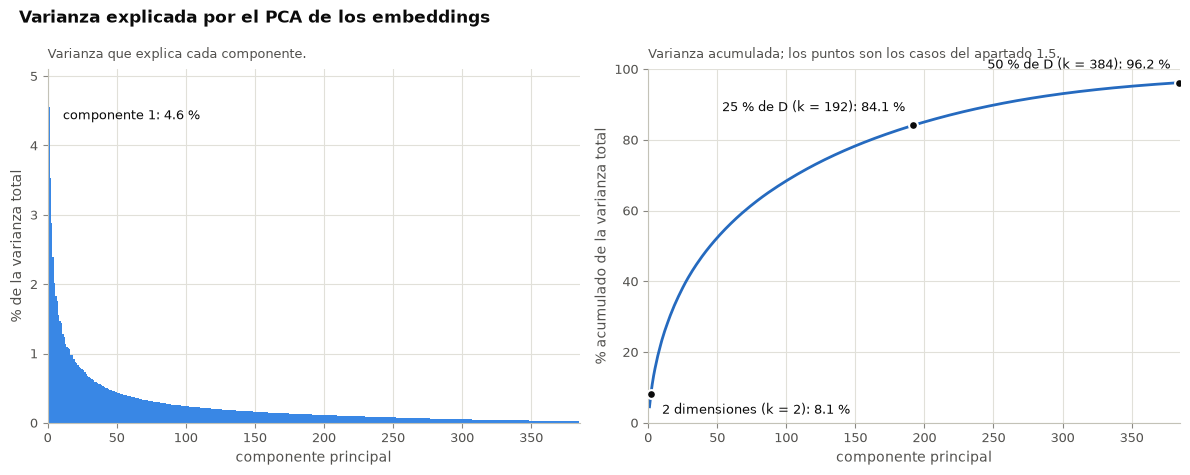

,k,varianza conservada
50 % de D,384,96.16%
25 % de D,192,84.13%
2 dimensiones,2,8.08%


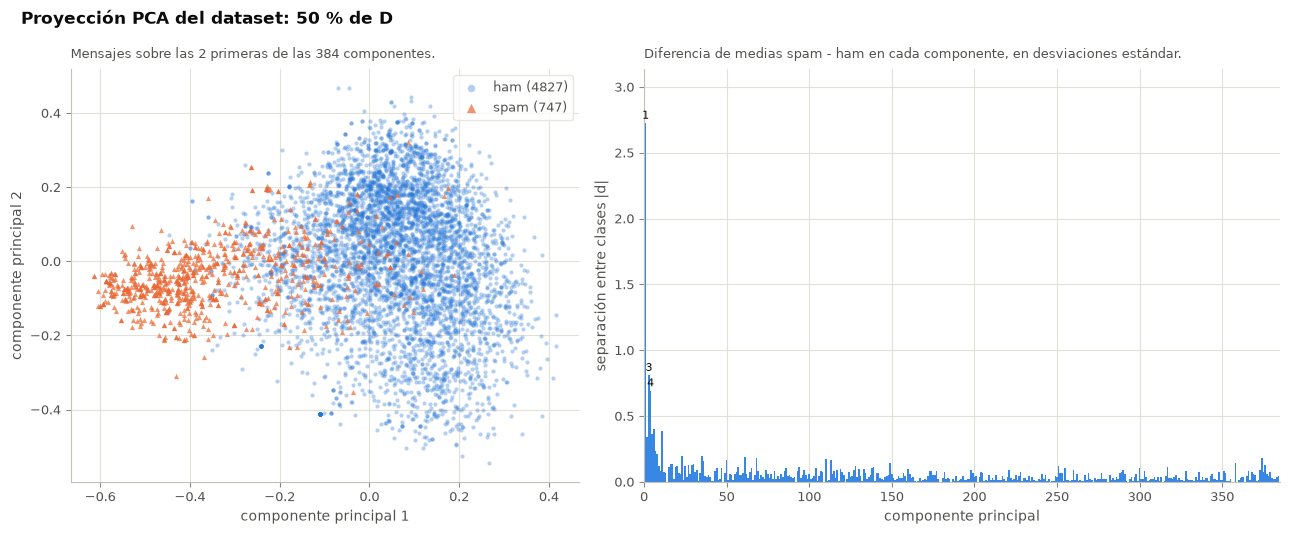

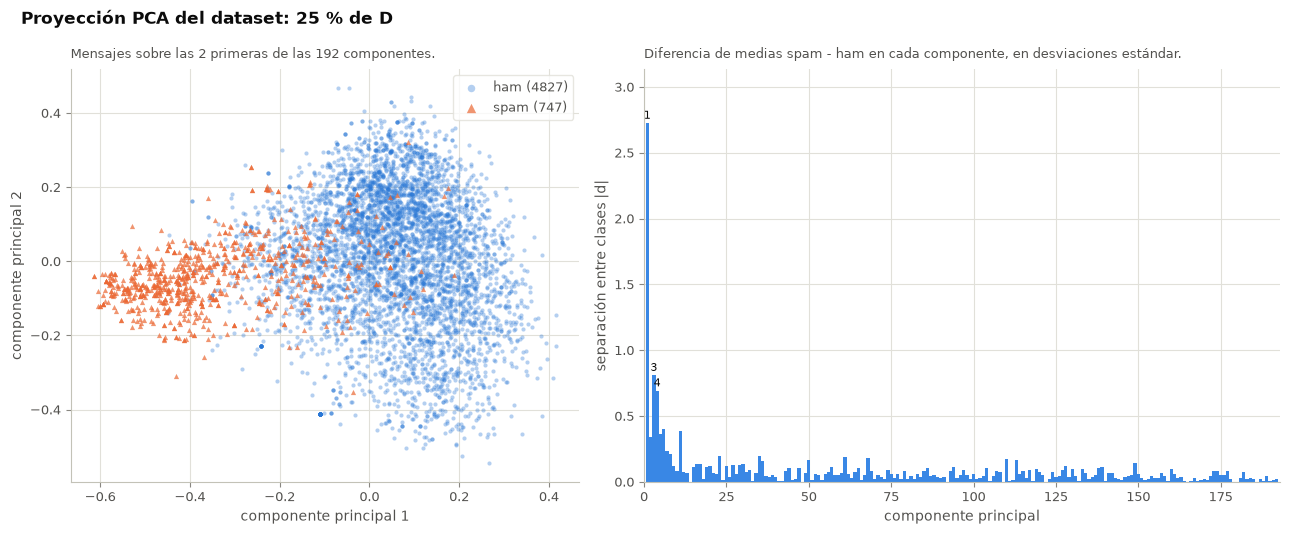

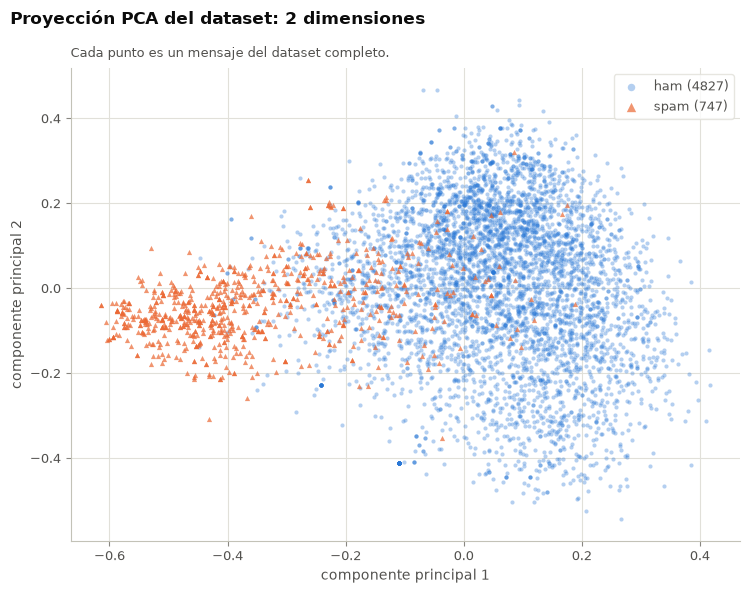

In [18]:
pca_dimensions = {
    f"{label} de D": components_for_fraction(features.shape[1], fraction)
    for label, fraction in PCA_FRACTIONS.items()
}
pca_dimensions["2 dimensiones"] = 2

# PCA de todo el dataset, solo para graficar; en las corridas se ajusta con cada entrenamiento.
full_pca = fit_pca(features, max(pca_dimensions.values()))
show_figure(
    plot_explained_variance(full_pca, title="Varianza explicada por el PCA de los embeddings")
)
cumulative_variance = full_pca.explained_variance_ratio.cumsum(dim=0)
display_table(
    pd.DataFrame(
        {
            "k": list(pca_dimensions.values()),
            "varianza conservada": [float(cumulative_variance[k - 1]) for k in pca_dimensions.values()],
        },
        index=list(pca_dimensions),
    ),
    "Varianza que conserva cada reducción",
    formats={"varianza conservada": "{:.2%}"},
)
for name, n_components in pca_dimensions.items():
    projection = transform_pca(full_pca, features)[:, :n_components]
    show_figure(
        plot_pca_projection(projection, targets, title=f"Proyección PCA del dataset: {name}")
    )

In [ ]:
# La validación y los hiperparámetros se obtienen de nuevo en cada partición y para cada k.
# Los PCA internos y externos se reutilizan entre k, siempre con los mismos índices de ajuste.
for name, n_components in pca_dimensions.items():
    def pca_with_progress(seed, k=n_components):
        """!
        @brief Ejecuta y anuncia una corrida con calibración interna y PCA.
        @param seed Semilla de la corrida.
        @param k Cantidad de componentes conservadas.
        @return Métricas, confusión e hiperparámetros elegidos.
        """
        result = logistic_regression_run(seed, n_components=k)
        print(f"PCA k={k}: corrida {seed - SEED + 1}/{N_RUNS}; F1={result['f1']:.4f}", flush=True)
        return result

    classification_results[f"RL + PCA k = {n_components}"] = repeat_experiment(
        pca_with_progress, n_runs=N_RUNS, base_seed=SEED,
    )

display_table(
    pd.concat(
        {name: runs[["corrida", "semilla", "learning_rate", "epochs"]]
         for name, runs in classification_results.items()},
        names=["método", "fila"],
    ).droplevel("fila"),
    "Hiperparámetros elegidos en validación interna por método y corrida",
    formats={"learning_rate": "{:g}", "epochs": "{:.0f}"},
)

display_table(
    compare_experiments(only_metrics(classification_results)),
    "Regresión logística con y sin PCA (30 corridas)",
    formats="{:.4f}",
)
display_table(
    pd.DataFrame(
        {
            name: {
                "ham marcados como spam": runs["fp"].mean(),
                "spam que se escapa": runs["fn"].mean(),
                "spam detectado": runs["tp"].mean(),
            }
            for name, runs in classification_results.items()
        }
    ).T,
    "Errores promedio por corrida con y sin PCA",
    formats="{:.1f}",
)
# Todas las variantes usan las mismas 30 particiones, así que se comparan corrida a corrida.
display_table(
    pd.DataFrame(
        {
            name: {
                "diferencia media de F1": (runs["f1"] - baseline_runs["f1"]).mean(),
                "desviación de la diferencia": (runs["f1"] - baseline_runs["f1"]).std(),
                "corridas con F1 menor": int((runs["f1"] < baseline_runs["f1"]).sum()),
            }
            for name, runs in classification_results.items()
            if name != baseline_name
        }
    ).T,
    "Diferencia de F1 frente a la regresión sin PCA en la misma partición",
    formats={
        "diferencia media de F1": "{:+.4f}",
        "desviación de la diferencia": "{:.4f}",
        "corridas con F1 menor": "{:.0f}",
    },
)
show_figure(
    plot_metric_distributions(
        classification_results, "f1", title="F1-score de la regresión logística con y sin PCA"
    )
)

PCA k=384: corrida 1/30; F1=0.9661
PCA k=384: corrida 2/30; F1=0.9613
PCA k=384: corrida 3/30; F1=0.9613
PCA k=384: corrida 4/30; F1=0.9657
PCA k=384: corrida 5/30; F1=0.9657
PCA k=384: corrida 6/30; F1=0.9495
PCA k=384: corrida 7/30; F1=0.9541
PCA k=384: corrida 8/30; F1=0.9565
PCA k=384: corrida 9/30; F1=0.9657
PCA k=384: corrida 10/30; F1=0.9679
PCA k=384: corrida 11/30; F1=0.9680
PCA k=384: corrida 12/30; F1=0.9776
PCA k=384: corrida 13/30; F1=0.9613


**Análisis (MPNet, 768 dimensiones; 30 corridas por método).** La comparación usa las mismas semillas de 2026 a 2055 y calibra tasa y épocas dentro del entrenamiento de cada corrida y cada cantidad de componentes.

| Dimensiones | Varianza conservada (PCA descriptivo) | Tasa de aciertos, media ± desviación | F1, media ± desviación | Diferencia media de F1 frente a sin PCA |
|---|---:|---:|---:|---:|
| 768, sin PCA | 100 % | 0.9906 ± 0.0016 | 0.9641 ± 0.0063 | — |
| 384, 50 % | 96.16 % | 0.9905 ± 0.0019 | 0.9637 ± 0.0075 | −0.0004 |
| 192, 25 % | 84.13 % | 0.9894 ± 0.0021 | 0.9596 ± 0.0082 | −0.0045 |
| 2 | 8.08 % | 0.9466 ± 0.0054 | 0.7845 ± 0.0189 | −0.1796 |

Con 384 componentes el F1 baja en 14 de las 30 particiones; la diferencia pareada es −0.0004 ± 0.0030. Se conserva casi toda la varianza con la mitad de características y la pérdida media de F1 es pequeña en estas particiones. Con 192 baja en 24 de las 30: diferencia −0.0045 ± 0.0054. Esto reduce nuevamente a la mitad las dimensiones, con una pérdida media mayor. Las desviaciones son variaciones entre particiones que reutilizan mensajes, no intervalos de confianza de muestras independientes.

Con 2 dimensiones el F1 baja en las 30 corridas: diferencia −0.1796 ± 0.0198. Los spam no detectados suben de 11.8 por prueba sin PCA a 61.4, y los ham marcados como spam, de 4.0 a 27.9. La tasa de aciertos oculta parte del deterioro de la clase minoritaria. Una proyección útil para visualizar no conserva necesariamente la información necesaria para clasificar.

**Dimensión elegida: 384 (24/10/2026).** El equipo fija `OPTIMAL_PCA_DIMENSIONS = 384` para la regresión logística: conserva el 96.16 % de la varianza del PCA descriptivo y un F1 medio de 0.9637 frente a 0.9641 sin PCA, con una diferencia pareada de −0.0004. Se reduce a la mitad la cantidad de características respecto de las 768 dimensiones originales. El detector de histogramas del punto 2 elige entre estos mismos casos con su propia validación y usa 2 componentes (ver 2.1). Es un compromiso entre dimensionalidad y desempeño observado; no demuestra equivalencia estadística ni un óptimo global. Estas conclusiones sustituyen las de MiniLM/384 y mantienen la limitación de textos duplicados entre entrenamiento y prueba por partición de filas.

---
## 2. Detección de anomalías: umbral de verosimilitud

Implementación: celdas de esta sección · Pruebas: `tests/test_punto2.py` · Informe: `docs/report/sections/02-punto2-deteccion-anomalias.tex`

### 2.1 Densidades por histograma

Cada mensaje se proyecta con un PCA ajustado solo con el entrenamiento de su partición. En cada componente $d$ se estima la densidad $p_d$ con un histograma de `HISTOGRAM_BINS = 30` intervalos de igual ancho entre el mínimo y el máximo observados, normalizado para que integre 1. El puntaje de un mensaje es $\sum_{d=1}^{D}\log p_d(x_d)$, tratando las componentes como independientes; un valor en un intervalo vacío o fuera del soporte recibe la densidad mínima $\varepsilon = 10^{-12}$. Un puntaje menor que el umbral marca el mensaje como fuera de la distribución (spam).

**Decisiones del equipo (24/10/2026).**

- **Datos de las densidades: solo ham del entrenamiento.** Los histogramas describen la distribución normal; el spam no participa, así que queda como lo atípico.
- **Umbral: cuantil 5 % de ham reservado.** El 20 % de los ham de entrenamiento no construye los histogramas y se usa solo para el umbral: el cuantil 5 % de sus puntajes (`ANOMALY_THRESHOLD_QUANTILE`). Si el umbral se calculara con los mismos ham de los histogramas, ninguno caería fuera del soporte y el umbral quedaría sesgado hacia arriba. El umbral toma en cuenta la verosimilitud sumada de todas las densidades, como pide el enunciado.
- **Dimensión del detector: $D = 2$ (`ANOMALY_PCA_DIMENSIONS`).** Se elige entre los tres casos del apartado 1.5 (384, 192 y 2) con una validación interna de los 30 entrenamientos, sin usar la prueba. La regresión logística conserva su óptimo `OPTIMAL_PCA_DIMENSIONS = 384`; la justificación está a continuación.

**Alcance auditado.** La elección de D usa etiquetas de validación y sus particiones se solapan entre corridas. D=2 es una variante acordada por el equipo respecto de la lectura literal de 2.1 (reutilizar D=384); falta validar ese alcance con el docente. El cuantil de ham reservado fija una fracción objetivo en calibración, sin garantía de la misma tasa en datos futuros.

In [ ]:
# Definiciones: 2, densidades por histograma y anomalías

@dataclass
class HistogramDensities:
    """!
    @brief Histogramas normalizados, uno por dimensión.
    """

    ## Bordes de los intervalos de cada dimensión, forma (D, B + 1).
    bin_edges: torch.Tensor
    ## Densidad de cada intervalo (integra 1 en cada dimensión), forma (D, B).
    densities: torch.Tensor


# ---------------------------------------------------------------------------
# 2.1: estimación de densidades y umbral
# ---------------------------------------------------------------------------


def _bin_indices(bin_edges, X):
    """!
    @brief Ubica cada valor en el intervalo cuyo borde izquierdo es el mayor que no lo supera.

    Un valor igual a un borde interno pertenece al intervalo de la derecha. El
    resultado no se recorta: el máximo del soporte da B y los valores por debajo
    del mínimo dan -1, para que quien llama decida cómo tratarlos.

    @param bin_edges Bordes de forma (D, B + 1), crecientes en cada fila.
    @param X Valores de forma (n, D).
    @return Tensor `int64` de forma (n, D) con el índice de intervalo de cada valor.
    """
    values = X.to(bin_edges.dtype).T.contiguous()
    return (torch.searchsorted(bin_edges.contiguous(), values, right=True) - 1).T


def fit_histogram_densities(X_train, n_bins=30):
    """!
    @brief Estima la densidad de cada dimensión con un histograma.

    En cada dimensión, B intervalos de igual ancho cubren desde el mínimo hasta
    el máximo de `X_train`; el máximo se cuenta en el último intervalo. La
    densidad de un intervalo es su frecuencia relativa dividida entre su ancho,
    así que cada histograma integra 1. Una dimensión constante recibe un
    soporte centrado en su valor, de radio `0.5 * max(|valor|, 1)`.

    El notebook construye las densidades solo con los mensajes ham del
    entrenamiento (decisión del equipo): describen la distribución normal y el
    spam queda como lo atípico.

    @param X_train Tensor de entrenamiento (n, D) con valores finitos.
    @param n_bins Cantidad de intervalos B por dimensión (entero positivo).
    @return HistogramDensities ajustado, con tensores `float64`.
    @throws ValueError Si `X_train` está vacío, no es una matriz o tiene valores no finitos,
            o si `n_bins` no es un entero positivo.
    """
    if isinstance(n_bins, bool) or not isinstance(n_bins, int) or n_bins < 1:
        raise ValueError("n_bins debe ser un entero positivo.")
    X = torch.as_tensor(X_train)
    if X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0:
        raise ValueError("X_train debe tener forma (n, D) con n > 0 y D > 0.")
    X = X.to(torch.float64)
    if not torch.isfinite(X).all():
        raise ValueError("X_train contiene valores no finitos.")

    n_samples, n_dimensions = X.shape
    low, high = X.min(dim=0).values, X.max(dim=0).values
    constant = high == low
    radius = 0.5 * low.abs().clamp_min(1.0)
    low = torch.where(constant, low - radius, low)
    high = torch.where(constant, high + radius, high)

    steps = torch.linspace(0.0, 1.0, n_bins + 1, dtype=X.dtype)
    bin_edges = low[:, None] + (high - low)[:, None] * steps
    bin_edges[:, 0], bin_edges[:, -1] = low, high

    bins = _bin_indices(bin_edges, X).clamp(0, n_bins - 1)
    counts = torch.zeros(n_dimensions, n_bins, dtype=X.dtype)
    counts.scatter_add_(1, bins.T.contiguous(), torch.ones(n_dimensions, n_samples, dtype=X.dtype))
    densities = counts / (n_samples * bin_edges.diff(dim=1))
    return HistogramDensities(bin_edges=bin_edges, densities=densities)


def per_dimension_log_likelihood(model, X, epsilon=1e-12):
    """!
    @brief Calcula log p_d(x_d) de cada mensaje en cada dimensión, sin sumar.

    Un valor en un intervalo vacío o fuera del soporte de su histograma (por
    debajo del primer borde o por encima del último) recibe la densidad mínima
    `epsilon`; los valores no se recortan al soporte.

    @param model HistogramDensities ajustado.
    @param X Tensor de forma (n, D) con valores finitos.
    @param epsilon Densidad mínima (positiva) para evitar log(0).
    @return Tensor `float64` de forma (n, D) con log p_d(x_d).
    @throws ValueError Si `X` no coincide con las dimensiones del modelo, tiene valores no
            finitos o `epsilon` no es positivo.
    """
    if not epsilon > 0:
        raise ValueError("epsilon debe ser positivo.")
    bin_edges = torch.as_tensor(model.bin_edges)
    densities = torch.as_tensor(model.densities).to(torch.float64)
    X = torch.as_tensor(X)
    if X.ndim != 2 or X.shape[1] != bin_edges.shape[0]:
        raise ValueError("X debe tener forma (n, D) con las mismas D dimensiones del modelo.")
    if not torch.isfinite(X).all():
        raise ValueError("X contiene valores no finitos.")

    X = X.to(bin_edges.dtype)
    inside = (X >= bin_edges[:, 0]) & (X <= bin_edges[:, -1])
    bins = _bin_indices(bin_edges, X).clamp(0, densities.shape[1] - 1)
    values = torch.gather(densities, 1, bins.T.contiguous()).T
    values = torch.where(inside, values, torch.zeros_like(values)).clamp_min(epsilon)
    return values.log()


def log_likelihood(model, X, epsilon=1e-12):
    """!
    @brief Calcula el puntaje de verosimilitud sumado sobre todas las dimensiones.

    El puntaje de un mensaje es la suma de log p_d(x_d) en las D dimensiones,
    tratadas como independientes (ver `per_dimension_log_likelihood`).

    @param model HistogramDensities ajustado.
    @param X Tensor de forma (n, D) con valores finitos.
    @param epsilon Densidad mínima (positiva) para evitar log(0).
    @return Tensor `float64` de forma (n,) con la suma de log p_d(x_d).
    @throws ValueError Si `X` no coincide con las dimensiones del modelo, tiene valores no
            finitos o `epsilon` no es positivo.
    """
    return per_dimension_log_likelihood(model, X, epsilon).sum(dim=1)


def select_threshold(scores, quantile=0.05):
    """!
    @brief Define el umbral de verosimilitud a partir de puntajes de entrenamiento.

    El umbral es el cuantil `quantile` de los puntajes, con interpolación
    lineal entre los valores ordenados. Con la regla estricta de
    `predict_anomalies` (puntaje menor que el umbral), aproximadamente esa
    fracción de los datos de referencia queda marcada como anomalía; si hay
    empates en el umbral, la fracción marcada puede ser menor.

    @param scores Puntajes de `log_likelihood` de los datos de referencia, forma (n,).
    @param quantile Fracción de datos de referencia que se acepta marcar como anomalía,
           entre 0 y 1.
    @return Umbral escalar (float).
    @throws ValueError Si los puntajes están vacíos, no son un vector o tienen valores no
            finitos, o si `quantile` no está entre 0 y 1.
    """
    scores = torch.as_tensor(scores)
    if scores.ndim != 1 or scores.numel() == 0:
        raise ValueError("scores debe ser un vector no vacío.")
    if not torch.isfinite(scores).all():
        raise ValueError("scores contiene valores no finitos.")
    if not 0.0 <= quantile <= 1.0:
        raise ValueError("quantile debe estar entre 0 y 1.")
    return float(torch.quantile(scores.to(torch.float64), float(quantile)))


def predict_anomalies(scores, threshold):
    """!
    @brief Marca como anomalía (spam = 1) cada puntaje por debajo del umbral.
    @param scores Tensor de forma (n,) con puntajes de verosimilitud.
    @param threshold Umbral devuelto por `select_threshold`.
    @return Tensor `int64` de forma (n,) con etiquetas 0/1.
    """
    return (torch.as_tensor(scores) < threshold).to(torch.int64)


@dataclass
class AnomalyDetector:
    """!
    @brief Detector de anomalías ajustado: histogramas de la clase normal y su umbral.
    """

    ## Histogramas de la distribución normal (ham).
    densities: HistogramDensities
    ## Umbral de verosimilitud: un puntaje menor marca el mensaje como anomalía (spam).
    threshold: float


def fit_anomaly_detector(X_normal, n_bins=30, quantile=0.05, threshold_fraction=0.2, seed=None):
    """!
    @brief Construye las densidades con una parte de los datos normales y fija el umbral con el resto.

    Las filas de `X_normal` se reparten al azar: `1 - threshold_fraction` construye
    los histogramas y `threshold_fraction` (reservada) da los puntajes con los que
    `select_threshold` calcula el cuantil. Si el umbral se calculara con las mismas
    filas de los histogramas, ninguna caería fuera del soporte y el umbral quedaría
    más alto de lo que corresponde a datos nuevos.

    @param X_normal Datos de la clase normal (ham) del entrenamiento, forma (n, D), n >= 2.
    @param n_bins Cantidad de intervalos por dimensión.
    @param quantile Fracción de los datos normales reservados que se acepta marcar como anomalía.
    @param threshold_fraction Fracción de `X_normal` reservada para el umbral, en (0, 1).
    @param seed Semilla del reparto; la misma semilla da el mismo detector.
    @return AnomalyDetector con las densidades y el umbral.
    @throws ValueError Si hay menos de dos filas o `threshold_fraction` no está en (0, 1).
    """
    X = torch.as_tensor(X_normal)
    if X.ndim != 2 or X.shape[0] < 2:
        raise ValueError("X_normal debe tener forma (n, D) con al menos dos filas.")
    if not 0.0 < threshold_fraction < 1.0:
        raise ValueError("threshold_fraction debe estar en el intervalo (0, 1).")

    order = torch.randperm(X.shape[0], generator=_generator(seed))
    n_threshold = min(X.shape[0] - 1, max(1, round(threshold_fraction * X.shape[0])))
    threshold_rows, density_rows = order[:n_threshold], order[n_threshold:]
    densities = fit_histogram_densities(X[density_rows], n_bins=n_bins)
    threshold = select_threshold(log_likelihood(densities, X[threshold_rows]), quantile)
    return AnomalyDetector(densities=densities, threshold=threshold)


def detector_metrics(detector, X, y):
    """!
    @brief Evalúa un detector: métricas del enunciado y tasas por clase.
    @param detector AnomalyDetector ajustado.
    @param X Datos de evaluación, forma (n, D).
    @param y Etiquetas 0/1 de forma (n,), con spam = 1 como anomalía.
    @return Diccionario con `tasa_aciertos`, `f1`, la fracción de spam detectado y la
            fracción de ham marcado como spam (NaN si falta la clase).
    """
    y = torch.as_tensor(y)
    predictions = predict_anomalies(log_likelihood(detector.densities, X), detector.threshold)
    rates = {}
    for label, name in ((1, "spam detectado"), (0, "ham marcado como spam")):
        mask = y == label
        rates[name] = float(predictions[mask].float().mean()) if mask.any() else float("nan")
    return {**classification_metrics(y, predictions), **rates}


def evaluate_detector_dimensions(
    X_fit, y_fit, X_validation, y_validation, candidates,
    n_bins=30, quantile=0.05, threshold_fraction=0.2, seed=None,
):
    """!
    @brief Compara cantidades de componentes del detector en una validación interna.

    Para cada k se usan las primeras k columnas (componentes principales ya
    ordenadas): el detector se ajusta con los ham de `X_fit` y se evalúa en
    `X_validation`, que contiene ham y spam. La prueba no interviene.

    @param X_fit Datos de ajuste proyectados con al menos `max(candidates)` componentes.
    @param y_fit Etiquetas 0/1 de `X_fit`; solo sus ham construyen el detector.
    @param X_validation Datos de validación con las mismas columnas que `X_fit`.
    @param y_validation Etiquetas 0/1 de `X_validation`.
    @param candidates Cantidades de componentes que se comparan.
    @param n_bins Cantidad de intervalos por dimensión.
    @param quantile Cuantil del umbral sobre los ham reservados.
    @param threshold_fraction Fracción de los ham de ajuste reservada para el umbral.
    @param seed Semilla del reparto de los ham de ajuste.
    @return DataFrame con una fila por k y las columnas de `detector_metrics`.
    @throws ValueError Si algún candidato no es positivo o supera las columnas disponibles.
    """
    X_fit, X_validation = torch.as_tensor(X_fit), torch.as_tensor(X_validation)
    y_fit = torch.as_tensor(y_fit)
    if any(int(k) < 1 or int(k) > X_fit.shape[1] for k in candidates):
        raise ValueError("Cada candidato debe estar entre 1 y la cantidad de columnas de X_fit.")
    rows = []
    for k in candidates:
        k = int(k)
        detector = fit_anomaly_detector(
            X_fit[y_fit == 0][:, :k], n_bins, quantile, threshold_fraction, seed
        )
        rows.append({"k": k, **detector_metrics(detector, X_validation[:, :k], y_validation)})
    return pd.DataFrame(rows)


def component_log_likelihood_gap(model, X, y, epsilon=1e-12):
    """!
    @brief Mide, por componente, cuánto menos verosímil es el spam que el ham.

    Para cada dimensión d calcula la media de log p_d(x_d) de los ham menos la
    de los spam. Un valor positivo indica que en esa dimensión el spam cae en
    zonas de menor densidad y ayuda a detectarlo; uno negativo, que el spam
    parece más normal que el propio ham. La suma acumulada hasta k es la
    diferencia media de puntajes que tendría un detector con k componentes.

    @param model HistogramDensities ajustado con datos normales (ham).
    @param X Datos de evaluación con ambas clases, forma (n, D).
    @param y Etiquetas 0/1 de forma (n,).
    @param epsilon Densidad mínima de `per_dimension_log_likelihood`.
    @return Tensor `float64` de forma (D,) con la brecha de cada dimensión.
    @throws ValueError Si falta alguna de las dos clases.
    """
    y = torch.as_tensor(y)
    if not (y == 0).any() or not (y == 1).any():
        raise ValueError("Se necesitan mensajes ham y spam para medir la brecha.")
    values = per_dimension_log_likelihood(model, X, epsilon)
    return values[y == 0].mean(dim=0) - values[y == 1].mean(dim=0)


# ---------------------------------------------------------------------------
# 2.1: gráficos de las densidades y de los puntajes
# ---------------------------------------------------------------------------


def plot_densities(model, max_dimensions=6, title="Densidades estimadas por dimensión"):
    """!
    @brief Grafica los histogramas de las primeras dimensiones.

    Cada panel muestra la densidad estimada p_d de una dimensión como barras
    contiguas; el área total de cada panel es 1.

    @param model HistogramDensities ajustado.
    @param max_dimensions Cantidad máxima de dimensiones que se grafican.
    @param title Título de la figura (también define el nombre del PNG exportado).
    @return Figura de Matplotlib (sin mostrar).
    """
    bin_edges = torch.as_tensor(model.bin_edges).detach().cpu().numpy().astype(float)
    densities = torch.as_tensor(model.densities).detach().cpu().numpy().astype(float)
    n_panels = min(int(max_dimensions), densities.shape[0])
    if n_panels < 1:
        raise ValueError("Se necesita al menos una dimensión para graficar.")
    n_columns = min(3, n_panels)
    n_rows = int(np.ceil(n_panels / n_columns))

    figure, axes = plt.subplots(
        n_rows, n_columns, figsize=(4.0 * n_columns, 3.0 * n_rows + 0.8), squeeze=False
    )
    for index, axis in enumerate(axes.flat):
        if index >= n_panels:
            axis.set_visible(False)
            continue
        _style_axis(axis)
        edges = bin_edges[index]
        axis.stairs(
            densities[index], edges, fill=True, color=_CLASS_COLORS[0], alpha=0.35, linewidth=0
        )
        axis.stairs(densities[index], edges, color=_CLASS_COLORS[0], linewidth=1.4)
        axis.set_xlim(edges[0], edges[-1])
        axis.set_ylim(0, densities[index].max() * 1.12 if densities[index].max() > 0 else 1)
        axis.set_xlabel(f"componente {index + 1}")
        if index % n_columns == 0:
            axis.set_ylabel("densidad")

    _set_titles(
        figure, axes[0, 0], title,
        "Histograma normalizado (área 1) de cada componente; las barras altas son los valores frecuentes.",
    )
    figure.tight_layout()
    return figure


def plot_score_distribution(scores, y, threshold, title="Puntajes de verosimilitud por clase"):
    """!
    @brief Grafica la distribución de puntajes de ham y spam junto con el umbral.

    Las dos clases se dibujan como histogramas normalizados (área 1) con los
    mismos intervalos, para comparar su forma aunque spam sea minoritario. Ham
    usa línea continua y spam discontinua. A la izquierda de la línea vertical
    (puntaje menor que el umbral) los mensajes se marcan como spam.

    @param scores Tensor de forma (n,) con puntajes.
    @param y Etiquetas 0/1 de forma (n,).
    @param threshold Umbral de decisión.
    @param title Título de la figura.
    @return Figura de Matplotlib (sin mostrar).
    """
    scores = torch.as_tensor(scores).detach().cpu().numpy().astype(float)
    y = torch.as_tensor(y).detach().cpu().numpy().astype(int)
    if scores.ndim != 1 or scores.shape != y.shape or scores.size == 0:
        raise ValueError("scores e y deben ser vectores no vacíos de la misma longitud.")
    threshold = float(threshold)

    low = min(scores.min(), threshold)
    high = max(scores.max(), threshold)
    padding = 0.02 * (high - low) if high > low else 1.0
    bins = np.linspace(low - padding, high + padding, 61)

    figure, axis = plt.subplots(figsize=(9.0, 4.8))
    _style_axis(axis)
    names = ("ham", "spam")
    line_styles = ("-", "--")
    for label in (0, 1):
        values = scores[y == label]
        if values.size == 0:
            continue
        flagged = np.mean(values < threshold)
        density, _ = np.histogram(values, bins=bins, density=True)
        axis.stairs(density, bins, fill=True, color=_CLASS_COLORS[label], alpha=0.25, linewidth=0)
        axis.stairs(
            density, bins, color=_CLASS_COLORS[label], linewidth=1.6,
            linestyle=line_styles[label],
            label=f"{names[label]} ({values.size}); {flagged:.1%} bajo el umbral",
        )
    axis.axvline(threshold, color=_INK, linewidth=1.3, linestyle=":")
    axis.annotate(
        f"umbral = {threshold:.1f}", (threshold, 1.0), xycoords=("data", "axes fraction"),
        xytext=(6, -4), textcoords="offset points", va="top", fontsize=9, color=_INK,
    )
    axis.set_xlabel(r"puntaje $\sum_d \log p_d(x_d)$")
    axis.set_ylabel("densidad")
    _legend(axis, loc="upper center")
    _set_titles(
        figure, axis, title,
        "Histogramas normalizados por clase. A la izquierda del umbral el mensaje se marca como spam.",
    )
    figure.tight_layout()
    return figure


def plot_component_separation(gap, highlight=(2,), title="Brecha de verosimilitud entre ham y spam por componente"):
    """!
    @brief Grafica la brecha de `component_log_likelihood_gap` y su suma acumulada.

    Arriba, la brecha de cada componente (positiva: el spam es menos verosímil
    que el ham y la componente ayuda a detectarlo). Abajo, la suma acumulada
    hasta k, que es la diferencia media de puntajes ham − spam de un detector
    con k componentes; se marcan las cantidades de `highlight`.

    @param gap Tensor o arreglo de forma (D,) con la brecha por componente.
    @param highlight Cantidades de componentes que se marcan en la curva acumulada.
    @param title Título de la figura (también define el nombre del PNG exportado).
    @return Figura de Matplotlib (sin mostrar).
    """
    gap = torch.as_tensor(gap).detach().cpu().numpy().astype(float)
    if gap.ndim != 1 or gap.size == 0:
        raise ValueError("gap debe ser un vector no vacío.")
    positions = np.arange(1, gap.size + 1)
    cumulative = np.cumsum(gap)

    figure, (per_component, accumulated) = plt.subplots(
        2, 1, figsize=(10.0, 6.6), sharex=True, gridspec_kw={"height_ratios": (1, 1.15)}
    )
    for axis in (per_component, accumulated):
        _style_axis(axis)
        axis.axhline(0, color=_INK_MUTED, linewidth=0.9)
    colors = np.where(gap > 0, _BLUE_RAMP[5], _INK_MUTED)
    per_component.bar(positions, gap, width=1.0, color=colors, linewidth=0)
    per_component.set_ylabel("brecha por componente")

    accumulated.plot(positions, cumulative, color=_INK, linewidth=1.8)
    accumulated.set_ylabel("brecha acumulada hasta k")
    accumulated.set_xlabel("componente principal (k)")
    accumulated.set_xlim(0, gap.size + 1)
    for k in sorted(set(int(value) for value in highlight)):
        if not 1 <= k <= gap.size:
            continue
        value = cumulative[k - 1]
        accumulated.scatter(k, value, s=40, color=_INK, edgecolors=_SURFACE, linewidths=1.5, zorder=3)
        # La curva tiende a bajar: las etiquetas positivas van arriba a la derecha y las
        # negativas abajo a la izquierda, donde no pasa la curva.
        accumulated.annotate(
            f"k = {k}: {value:+.1f}", (k, value),
            xytext=(8, 6) if value >= 0 else (-8, -14), textcoords="offset points",
            fontsize=9, color=_INK, ha="left" if value >= 0 else "right",
        )

    _set_titles(
        figure, per_component, title,
        "Media de log p_d de los ham menos la de los spam. Barra azul: el spam es menos verosímil; gris: parece más normal.",
    )
    accumulated.set_title(
        "Suma acumulada: diferencia media de puntajes de un detector con k componentes (mayor separa mejor).",
        loc="left", fontsize=9, color=_INK_SECONDARY, pad=8,
    )
    figure.tight_layout()
    return figure


def plot_detector_region(detector, X, y, title="Región normal del detector en dos componentes"):
    """!
    @brief Dibuja los mensajes en el plano y la región que el detector considera normal.

    La región sombreada contiene los puntos cuyo puntaje supera el umbral
    (ham para el detector); fuera de ella, el mensaje se marca como spam. Como
    las densidades son histogramas, la región está formada por rectángulos.

    @param detector AnomalyDetector ajustado con exactamente dos dimensiones.
    @param X Datos de forma (n, 2).
    @param y Etiquetas 0/1 de forma (n,).
    @param title Título de la figura (también define el nombre del PNG exportado).
    @return Figura de Matplotlib (sin mostrar).
    """
    if detector.densities.bin_edges.shape[0] != 2:
        raise ValueError("La región solo se puede dibujar para un detector de dos dimensiones.")
    points, labels = _points_as_numpy(X, y)
    edges = detector.densities.bin_edges.detach().cpu().numpy().astype(float)
    low = np.minimum(points.min(axis=0), edges[:, 0])
    high = np.maximum(points.max(axis=0), edges[:, -1])
    padding = 0.05 * (high - low)
    grid_x = np.linspace(low[0] - padding[0], high[0] + padding[0], 400)
    grid_y = np.linspace(low[1] - padding[1], high[1] + padding[1], 400)
    mesh_x, mesh_y = np.meshgrid(grid_x, grid_y)
    grid = torch.as_tensor(np.column_stack([mesh_x.ravel(), mesh_y.ravel()]))
    normal = ~predict_anomalies(log_likelihood(detector.densities, grid), detector.threshold).bool()
    normal = normal.numpy().reshape(mesh_x.shape)

    figure, axis = plt.subplots(figsize=(8.0, 6.6))
    _style_axis(axis, grid=False)
    axis.contourf(mesh_x, mesh_y, normal.astype(float), levels=[0.5, 1.5], colors=[_BLUE_RAMP[1]])
    axis.contour(mesh_x, mesh_y, normal.astype(float), levels=[0.5], colors=[_INK_SECONDARY], linewidths=0.9)
    flagged = predict_anomalies(log_likelihood(detector.densities, torch.as_tensor(points)), detector.threshold)
    flagged = flagged.numpy().astype(bool)
    names = ("ham", "spam")
    for label in (0, 1):
        mask = labels == label
        axis.scatter(
            points[mask, 0], points[mask, 1], s=22, marker=_CLASS_MARKERS[label],
            color=_CLASS_COLORS[label], edgecolors=_SURFACE, linewidths=0.5, alpha=0.8,
            label=f"{names[label]} ({mask.sum()}); {flagged[mask].mean():.1%} fuera de la región",
            zorder=3,
        )
    handles = axis.get_legend_handles_labels()[0]
    handles.append(plt.Rectangle((0, 0), 1, 1, color=_BLUE_RAMP[1], label="región normal (puntaje ≥ umbral)"))
    _legend(axis, handles=handles, loc="lower left")
    axis.set_xlim(grid_x[0], grid_x[-1])
    axis.set_ylim(grid_y[0], grid_y[-1])
    axis.set_xlabel("componente principal 1")
    axis.set_ylabel("componente principal 2")
    _set_titles(
        figure, axis, title,
        "Dentro de la zona sombreada el mensaje se acepta como ham; fuera, el detector lo marca como spam.",
    )
    figure.tight_layout()
    return figure

In [ ]:
# Selección de la dimensión del detector, solo con datos de entrenamiento: en cada una de
# las 30 particiones se separa la misma validación interna que en 1.4 (20 % estratificado
# del entrenamiento); el PCA y los histogramas se ajustan con el resto. La prueba no interviene.
anomaly_candidates = tuple(
    [components_for_fraction(EXPECTED_EMBEDDING_DIMENSIONS, fraction) for fraction in PCA_FRACTIONS.values()]
    + [2]
)  # los casos del apartado 1.5: 384, 192 y 2

selection_runs = []
for run_index in range(N_RUNS):
    seed = SEED + run_index
    train_indices, _ = stratified_split(targets, TRAIN_FRACTION, seed)
    fit_positions, validation_positions = stratified_split(
        targets[train_indices], 1 - LR_VALIDATION_FRACTION, seed
    )
    fit_indices = train_indices[fit_positions]
    validation_indices = train_indices[validation_positions]
    pca_model = fit_pca(features[fit_indices], max(anomaly_candidates))
    X_fit = transform_pca(pca_model, features[fit_indices])
    X_validation = transform_pca(pca_model, features[validation_indices])
    table = evaluate_detector_dimensions(
        X_fit, targets[fit_indices], X_validation, targets[validation_indices], anomaly_candidates,
        n_bins=HISTOGRAM_BINS, quantile=ANOMALY_THRESHOLD_QUANTILE,
        threshold_fraction=ANOMALY_THRESHOLD_FRACTION, seed=seed,
    )
    selection_runs.append(table.assign(corrida=run_index + 1))
    if run_index == 0:
        # Diagnóstico de la primera partición: brecha por componente con las 384 componentes.
        gap_detector = fit_anomaly_detector(
            X_fit[targets[fit_indices] == 0], HISTOGRAM_BINS, ANOMALY_THRESHOLD_QUANTILE,
            ANOMALY_THRESHOLD_FRACTION, seed,
        )
        component_gap = component_log_likelihood_gap(
            gap_detector.densities, X_validation, targets[validation_indices]
        )

selection_runs = pd.concat(selection_runs, ignore_index=True)
selection_columns = ["tasa_aciertos", "f1", "spam detectado", "ham marcado como spam"]
selection_summary = selection_runs.groupby("k", sort=False)[selection_columns].agg(["mean", "std"])
selection_summary.columns = [f"{metric} {'media' if stat == 'mean' else 'desviación'}"
                             for metric, stat in selection_summary.columns]
best_per_run = selection_runs.loc[selection_runs.groupby("corrida")["f1"].idxmax(), "k"]
selection_summary["corridas en que gana (F1)"] = (
    best_per_run.value_counts().reindex(selection_summary.index, fill_value=0)
)
selection_summary.index = [f"k = {k}" for k in selection_summary.index]
display_table(
    selection_summary,
    "Selección de la dimensión del detector en validación interna (30 entrenamientos)",
    formats={column: "{:.4f}" for column in selection_summary.columns if column != "corridas en que gana (F1)"},
)
best_k = int(selection_summary["f1 media"].idxmax().split("= ")[1])
print(f"Mayor F1 medio en validación: k = {best_k}; configurado: ANOMALY_PCA_DIMENSIONS = {ANOMALY_PCA_DIMENSIONS}")

show_figure(plot_component_separation(component_gap, highlight=anomaly_candidates))

**Análisis de la selección de $D$.** El enunciado pide usar la $D$ óptima deducida en 1.5. Allí se compararon 384, 192 y 2 componentes, y 384 fue el compromiso elegido para la **regresión logística**. Ese óptimo no se traslada al detector de histogramas, así que se compararon los mismos tres casos con el detector, solo con datos de entrenamiento. En cada una de las 30 particiones se separó la validación interna de 1.4 (20 % estratificado del entrenamiento); con el resto se ajustaron el PCA y los histogramas de los ham, y el detector se evaluó en esa validación:

| Componentes | Tasa de aciertos | F1 | Spam detectado | Ham marcado como spam | Corridas en que gana |
|---|---:|---:|---:|---:|---:|
| 384 | 0.7812 ± 0.0141 | 0.0401 ± 0.0193 | 3.4 % | 10.3 % | 0 |
| 192 | 0.8425 ± 0.0072 | 0.0237 ± 0.0191 | 1.4 % | 2.9 % | 0 |
| **2** | **0.9201 ± 0.0106** | **0.7085 ± 0.0318** | **72.1 %** | **4.9 %** | **30** |

Con 2 componentes el F1 en validación es el mayor en las 30 particiones; con 384 o 192 el detector casi no encuentra spam. La figura de la brecha explica por qué (primera partición, validación interna, 384 componentes):

- En la componente 1 el spam es mucho menos verosímil que el ham: la brecha media es de 12.8 en logaritmo. Es la dirección que separa las clases.
- En 330 de las 384 componentes la brecha es negativa: el spam queda **más concentrado** que el ham, cerca de la moda de cada histograma, y recibe más densidad. Los spam se parecen mucho entre sí, mientras que el ham es más variado.
- La brecha acumulada es +12.6 con 2 componentes, se vuelve negativa a partir de 169, vale −2.8 con 192 y llega a −41.1 con 384. Su máximo (14.2) está en 11 componentes; no se evaluó como candidato porque el equipo restringió la búsqueda a los tres casos de 1.5. El enunciado pide reutilizar la D óptima anterior; no prescribe esta búsqueda. Al sumar cientos de componentes poco informativas, sus aportes pequeños pero sistemáticos superan la señal de las primeras, y el spam termina pareciendo **más normal** que el ham.

Por eso se fija `ANOMALY_PCA_DIMENSIONS = 2`. Es una decisión del equipo basada en las validaciones. Cada validación excluye su propia prueba, pero puede contener mensajes que sean prueba en otra corrida; la agregación global de las 30 validaciones no aísla todas las pruebas de la selección de D. Aquí D=2 gana en las 30, por lo que seleccionarla por corrida da la misma dimensión observada. La elección usa etiquetas de spam para comparar F1, aunque los histogramas se ajustan solo con ham. Usar D=2 difiere de reutilizar D=384: queda pendiente validar esa variante con el docente; su mejor F1 no demuestra cumplimiento literal. Dos componentes conservan solo el 8.08 % de la varianza (tabla de 1.5), pero un detector por verosimilitud no necesita la varianza total: necesita las direcciones donde el spam se sale de lo normal, y en estos datos casi toda esa señal está en la primera componente. Esto también contrasta con la regresión logística, que aprende a ignorar las componentes poco útiles; el detector, en cambio, suma con el mismo peso todas las que recibe.

In [ ]:
def anomaly_detection_split(seed):
    """!
    @brief Ajusta PCA y detector con el entrenamiento de una partición y puntúa la prueba.
    @param seed Semilla de la partición.
    @return Diccionario con el detector, sus densidades y umbral, y los datos y puntajes de prueba.
    """
    train_indices, test_indices = stratified_split(targets, TRAIN_FRACTION, seed)
    pca_model = fit_pca(features[train_indices], ANOMALY_PCA_DIMENSIONS)
    X_train = transform_pca(pca_model, features[train_indices])
    X_test = transform_pca(pca_model, features[test_indices])

    # Decisión del equipo: las densidades describen solo los ham del entrenamiento; una
    # parte reservada de esos ham fija el umbral (cuantil ANOMALY_THRESHOLD_QUANTILE).
    detector = fit_anomaly_detector(
        X_train[targets[train_indices] == 0], HISTOGRAM_BINS, ANOMALY_THRESHOLD_QUANTILE,
        ANOMALY_THRESHOLD_FRACTION, seed,
    )
    return {
        "detector": detector,
        "densities": detector.densities,
        "threshold": detector.threshold,
        "X_test": X_test,
        "test_scores": log_likelihood(detector.densities, X_test),
        "test_targets": targets[test_indices],
    }


anomaly_demo = anomaly_detection_split(SEED)
print(f"Umbral de la partición {SEED}: {anomaly_demo['threshold']:.4f}")
show_figure(
    plot_densities(
        anomaly_demo["densities"], max_dimensions=ANOMALY_PCA_DIMENSIONS,
        title="Densidades de los ham de entrenamiento en las dos componentes principales",
    )
)
show_figure(
    plot_score_distribution(
        anomaly_demo["test_scores"], anomaly_demo["test_targets"], anomaly_demo["threshold"],
        title="Puntajes de verosimilitud de la prueba por clase",
    )
)
show_figure(
    plot_detector_region(
        anomaly_demo["detector"], anomaly_demo["X_test"], anomaly_demo["test_targets"],
        title="Región normal del detector en la prueba",
    )
)

**Análisis.** Partición de la semilla 2026: 3379 ham de entrenamiento; 2703 construyen los histogramas y 676 se reservan para el umbral, que queda en −0.8334.

- **Densidades.** Ambas componentes tienen una forma unimodal, con la masa entre −0.2 y 0.3 y colas hacia valores negativos. En la componente 1, la cola izquierda es corta: los ham casi no bajan de −0.41, el borde inferior del soporte. Los histogramas no son exactamente simétricos ni gaussianos; 30 intervalos describen la forma observada, pero las colas pueden tener intervalos escasos o vacíos; el tamaño total no garantiza estabilidad en cada intervalo.
- **Puntajes.** En la prueba, el 4.4 % de los ham queda bajo el umbral, cerca del 5 % buscado; el 75.9 % del spam queda bajo el umbral. El pico cercano a −27 son mensajes fuera del soporte de algún histograma, cuyo término vale $\log\varepsilon \approx -27.6$: es el 50 % del spam (todos a la izquierda del ham en la componente 1) y solo el 0.2 % del ham. Otro 25.9 % del spam cae dentro del soporte, pero en zonas de baja densidad.
- **Región normal.** Como las densidades son histogramas y las componentes se tratan como independientes, la región aceptada es una unión de rectángulos alrededor del grupo de ham. El spam que se escapa (24.1 %) se mezcla con el ham en el centro del plano: en estas dos componentes no se distingue de un mensaje normal, y ningún umbral sobre la verosimilitud podría separarlo sin marcar también muchos ham.

En esta partición la prueba da una tasa de aciertos de 0.9294 y un F1 de 0.7424. Las 30 corridas y la comparación con la regresión logística (F1 0.9641) corresponden a 2.2.

### 2.2 Evaluación en 30 corridas

In [ ]:
def anomaly_detection_run(seed):
    """!
    @brief Ejecuta una corrida del detector de anomalías y evalúa la prueba.
    @param seed Semilla de la partición.
    @return Diccionario con la tasa de aciertos, el F1-score, la matriz de confusión
            (`tp`, `fp`, `fn`, `tn`) y el umbral de la corrida.
    """
    split = anomaly_detection_split(seed)
    y_test = split["test_targets"]
    predictions = predict_anomalies(split["test_scores"], split["threshold"])
    confusion = {
        "tp": int(((predictions == 1) & (y_test == 1)).sum()),
        "fp": int(((predictions == 1) & (y_test == 0)).sum()),
        "fn": int(((predictions == 0) & (y_test == 1)).sum()),
        "tn": int(((predictions == 0) & (y_test == 0)).sum()),
    }
    return {**classification_metrics(y_test, predictions), **confusion, "umbral": split["threshold"]}


# Mismas 30 particiones (semillas SEED a SEED + 29) que la regresión del punto 1.
anomaly_name = f"Histogramas (D = {ANOMALY_PCA_DIMENSIONS})"
anomaly_results = {
    anomaly_name: repeat_experiment(anomaly_detection_run, n_runs=N_RUNS, base_seed=SEED)
}
anomaly_runs = anomaly_results[anomaly_name]
display_table(
    summarize_runs(anomaly_runs[METRIC_COLUMNS + ["umbral"]]),
    "Detector de anomalías por histogramas (30 corridas)",
    formats="{:.4f}",
)

compared_results = {**classification_results, **anomaly_results}
display_table(
    compare_experiments(only_metrics(compared_results)),
    "Detección de anomalías frente a la regresión logística (30 corridas)",
    formats="{:.4f}",
)
display_table(
    pd.DataFrame(
        {
            name: {
                "ham marcados como spam": runs["fp"].mean(),
                "spam que se escapa": runs["fn"].mean(),
                "spam detectado": runs["tp"].mean(),
            }
            for name, runs in compared_results.items()
        }
    ).T,
    "Errores promedio por corrida: detector de anomalías y regresión logística",
    formats="{:.1f}",
)
# Comparación corrida a corrida: la misma semilla da la misma partición en ambos métodos.
paired_references = [baseline_name, f"RL + PCA k = {ANOMALY_PCA_DIMENSIONS}"]
display_table(
    pd.DataFrame(
        {
            f"detector − {name}": {
                "diferencia media de tasa de aciertos": (anomaly_runs["tasa_aciertos"] - runs["tasa_aciertos"]).mean(),
                "diferencia media de F1": (anomaly_runs["f1"] - runs["f1"]).mean(),
                "desviación de la diferencia de F1": (anomaly_runs["f1"] - runs["f1"]).std(),
                "corridas con F1 menor": int((anomaly_runs["f1"] < runs["f1"]).sum()),
            }
            for name, runs in classification_results.items()
            if name in paired_references
        }
    ).T,
    "Diferencia del detector frente a la regresión en la misma partición",
    formats={
        "diferencia media de tasa de aciertos": "{:+.4f}",
        "diferencia media de F1": "{:+.4f}",
        "desviación de la diferencia de F1": "{:.4f}",
        "corridas con F1 menor": "{:.0f}",
    },
)
show_figure(
    plot_metric_distributions(
        compared_results, "f1", title="F1-score del detector de anomalías y de la regresión logística"
    )
)
show_figure(
    plot_metric_distributions(
        compared_results, "tasa_aciertos",
        title="Tasa de aciertos del detector de anomalías y de la regresión logística",
    )
)

**Análisis.** Las 30 corridas usan las mismas particiones (semillas 2026 a 2055) que la regresión logística del punto 1. En cada una, el PCA, los histogramas y el umbral se ajustan solo con el entrenamiento.

| Método | Tasa de aciertos | F1 | Ham marcados como spam | Spam que se escapa | Spam detectado |
|---|---:|---:|---:|---:|---:|
| Regresión logística, 768 dimensiones | 0.9906 ± 0.0016 | 0.9641 ± 0.0063 | 4.0 | 11.8 | 212.2 (94.7 %) |
| Regresión logística, PCA k = 2 | 0.9466 ± 0.0054 | 0.7845 ± 0.0189 | 27.9 | 61.4 | 162.6 (72.6 %) |
| **Histogramas, D = 2** | **0.9195 ± 0.0084** | **0.7043 ± 0.0247** | **70.5** | **64.0** | **160.0 (71.4 %)** |

Los errores son promedios por prueba (1448 ham y 224 spam). En la misma partición, el detector tiene un F1 0.2597 ± 0.0253 menor que la regresión sin PCA y 0.0802 ± 0.0212 menor que la regresión con 2 componentes; en ambos casos es menor en las 30 corridas.

- **Validación y prueba.** El F1 en la validación interna del 2.1 fue 0.7085 ± 0.0318 y en la prueba es 0.7043 ± 0.0247: la cercanía es descriptiva y no demuestra ausencia de sesgo de selección o desarrollo.
- **Con la misma información, el detector detecta casi el mismo spam, pero se equivoca más con el ham.** Frente a la regresión con 2 componentes, detecta 71.4 % del spam contra 72.6 %: el spam que se escapa es, en ambos casos, el que se mezcla con el ham en el plano. La diferencia está en los falsos positivos: 70.5 ham por prueba (4.9 %) contra 27.9 (1.9 %). El umbral apunta al 5 % de los ham de calibración, y el detector no sabe dónde está el spam: marca ham raros en cualquier dirección. La regresión, que sí conoce el spam, solo marca hacia su lado. Por eso la precisión del detector queda en 0.70.
- **La mayor parte de la brecha con la regresión completa viene de la dimensión.** Pasar de 768 a 2 componentes le cuesta a la regresión 0.18 de F1; pasar de la regresión al detector con 2 componentes cuesta 0.08 más. El detector no puede aprovechar más componentes porque, como se vio en 2.1, al sumar cientos de densidades el spam parece más normal que el ham.
- **La tasa de aciertos exagera el desempeño.** Con 86.6 % de ham, marcar todo como ham ya da 0.866; el 0.92 del detector es una mejora modesta, y el F1 de 0.70 muestra mejor el costo en la clase spam.
- **Variabilidad.** El F1 del detector varía entre 0.658 y 0.764 (desviación 0.0247, cuatro veces la de la regresión completa). El umbral cambia entre −1.03 y −0.49 según la partición, pero la fracción de ham marcados se mantiene en 4.9 % ± 1.0 %, cerca del 5 % fijado.

En resumen, el detector no supera a la regresión logística en ninguna partición. Su ventaja es otra: se entrena sin ejemplos de spam y permite fijar una fracción objetivo de ham marcado en calibración, sin garantizar esa tasa en mensajes futuros. Con etiquetas de spam disponibles, como en este dataset, el modelo supervisado es claramente mejor.

### Auditoría adicional de los puntos 1 y 2 (24/10/2026)

Experimento opcional con la caché MPNet local; no cambia las configuraciones del equipo. Compara la cuadrícula vigente con su ampliación a tasa 100 y 8000 épocas. Para histogramas compara D=384 (lectura literal del enunciado), D=2 vigente y una calibración de D, intervalos y cuantil por corrida. La selección usa únicamente la validación interna; las métricas de prueba de estas alternativas son exploratorias porque este dataset ya se usó para desarrollar los métodos. El F1 sobre textos de prueba ausentes del entrenamiento es un diagnóstico sobre un subconjunto, no una evaluación con partición agrupada ni una medida del sesgo causado por duplicados.

La ejecución puede durar varios minutos. Activar `RUN_METRIC_AUDIT` en la siguiente celda solo con autorización para corridas largas. No descarga modelos.

In [ ]:
# Auditoría opcional: activar solo para ejecutar las 30 corridas adicionales.
# Conserva las configuraciones oficiales; toda selección ocurre dentro de cada entrenamiento.
RUN_METRIC_AUDIT = False

if RUN_METRIC_AUDIT:
    audit_rows, audit_overlap = [], []
    audit_rates = (*LR_CALIBRATION_LEARNING_RATES, 100)
    audit_epochs = (*LR_CALIBRATION_EPOCHS, 8000)
    audit_bins, audit_quantiles = (15, 30, 60), (0.01, 0.025, 0.05, 0.1)
    audit_dimensions = (OPTIMAL_PCA_DIMENSIONS, 192, ANOMALY_PCA_DIMENSIONS)

    for run_index in range(N_RUNS):
        seed = SEED + run_index
        train_indices, test_indices = stratified_split(targets, TRAIN_FRACTION, seed)
        fit_pos, validation_pos = stratified_split(
            targets[train_indices], 1 - LR_VALIDATION_FRACTION, seed
        )
        fit_indices, validation_indices = train_indices[fit_pos], train_indices[validation_pos]
        seen_texts = {texts[int(index)] for index in train_indices}
        seen = torch.tensor([texts[int(index)] in seen_texts for index in test_indices])
        audit_overlap.append({
            "corrida": run_index + 1, "semilla": seed,
            "prueba con texto en entrenamiento": int(seen.sum()),
            "prueba total": len(test_indices),
            "fracción repetida": float(seen.float().mean()),
        })
        audit_grid = grid_search_logistic_regression(
            features[fit_indices], targets[fit_indices],
            features[validation_indices], targets[validation_indices],
            audit_rates, audit_epochs, f1_score, seed=seed,
        )
        original_grid = audit_grid[
            audit_grid.learning_rate.isin(LR_CALIBRATION_LEARNING_RATES)
            & audit_grid.epochs.isin(LR_CALIBRATION_EPOCHS)
        ]
        for method, grid in (("RL vigente", original_grid), ("RL ampliada", audit_grid)):
            best = grid.iloc[0]
            model = train_logistic_regression(
                features[train_indices], targets[train_indices],
                float(best.learning_rate), int(best.epochs), seed=seed,
            )
            predictions = predict(model, features[test_indices])
            audit_rows.append({
                "método": method, "corrida": run_index + 1, "semilla": seed,
                **classification_metrics(targets[test_indices], predictions),
                **confusion_counts(targets[test_indices], predictions),
                "F1 validación": float(best.score),
                "learning_rate": float(best.learning_rate), "epochs": int(best.epochs),
                "D": features.shape[1], "intervalos": float("nan"), "cuantil": float("nan"),
                "F1 textos no vistos": f1_score(targets[test_indices][~seen], predictions[~seen]),
            })

        internal_pca = fit_pca(features[fit_indices], max(audit_dimensions))
        X_fit = transform_pca(internal_pca, features[fit_indices])
        X_val = transform_pca(internal_pca, features[validation_indices])
        detector_grid = []
        for bins in audit_bins:
            for quantile in audit_quantiles:
                candidate_table = evaluate_detector_dimensions(
                    X_fit, targets[fit_indices], X_val, targets[validation_indices],
                    audit_dimensions, bins, quantile, ANOMALY_THRESHOLD_FRACTION, seed,
                )
                detector_grid.append(candidate_table.assign(intervalos=bins, cuantil=quantile))
        detector_grid = pd.concat(detector_grid, ignore_index=True).sort_values(
            ["f1", "tasa_aciertos", "k", "intervalos", "cuantil"],
            ascending=[False, False, True, True, True], kind="stable",
        )
        fixed_grid = detector_grid[
            (detector_grid.intervalos == HISTOGRAM_BINS)
            & (detector_grid.cuantil == ANOMALY_THRESHOLD_QUANTILE)
        ]
        final_pca = fit_pca(features[train_indices], max(audit_dimensions))
        X_train = transform_pca(final_pca, features[train_indices])
        X_test = transform_pca(final_pca, features[test_indices])
        detector_choices = (
            ("Histogramas D=384", fixed_grid[fixed_grid.k == OPTIMAL_PCA_DIMENSIONS].iloc[0]),
            ("Histogramas D=2 vigentes", fixed_grid[fixed_grid.k == ANOMALY_PCA_DIMENSIONS].iloc[0]),
            ("Histogramas calibrados", detector_grid.iloc[0]),
        )
        for method, best in detector_choices:
            dimension = int(best.k)
            detector = fit_anomaly_detector(
                X_train[targets[train_indices] == 0, :dimension],
                int(best.intervalos), float(best.cuantil), ANOMALY_THRESHOLD_FRACTION, seed,
            )
            predictions = predict_anomalies(
                log_likelihood(detector.densities, X_test[:, :dimension]), detector.threshold
            )
            audit_rows.append({
                "método": method, "corrida": run_index + 1, "semilla": seed,
                **classification_metrics(targets[test_indices], predictions),
                **confusion_counts(targets[test_indices], predictions),
                "F1 validación": float(best.f1),
                "learning_rate": float("nan"), "epochs": float("nan"),
                "D": dimension, "intervalos": int(best.intervalos), "cuantil": float(best.cuantil),
                "F1 textos no vistos": f1_score(targets[test_indices][~seen], predictions[~seen]),
            })
        print(f"Auditoría: corrida {run_index + 1}/{N_RUNS}", flush=True)

    audit_runs = pd.DataFrame(audit_rows)
    audit_results = {
        name: runs.reset_index(drop=True)
        for name, runs in audit_runs.groupby("método", sort=False)
    }
    display_table(audit_runs, "Auditoría de métricas por corrida")
    display_table(
        compare_experiments(only_metrics(audit_results)),
        "Auditoría de métricas: configuraciones vigentes y alternativas",
        formats="{:.4f}",
    )
    display_table(pd.DataFrame(audit_overlap), "Auditoría de textos repetidos entre entrenamiento y prueba")
else:
    print("Auditoría adicional omitida: RUN_METRIC_AUDIT = False.")


**Resultados de la auditoría adicional (30 corridas por variante).** Se ejecutó con la caché MPNet validada, en un kernel nuevo, sin descargar modelos. La celda opcional queda desactivada para las próximas ejecuciones; sus tablas completas y figuras regeneradas se conservan en la rama `codex/audit-puntos-1-2`. Main mantiene sus figuras previas; ejecutar la celda opcional permite regenerar las tablas de auditoría.

| Método | Tasa de aciertos | F1 |
|---|---:|---:|
| RL vigente | 0.9906 ± 0.0016 | 0.9641 ± 0.0063 |
| RL, cuadrícula ampliada | 0.9904 ± 0.0018 | 0.9636 ± 0.0068 |
| Histogramas D=384 | 0.7892 ± 0.0119 | 0.0386 ± 0.0145 |
| Histogramas D=2 vigentes | 0.9195 ± 0.0084 | 0.7043 ± 0.0247 |
| Histogramas calibrados por corrida | 0.9321 ± 0.0061 | 0.7173 ± 0.0441 |

- **Regresión:** la ampliación mejora F1 de prueba en 2 corridas, empata en 22 y empeora en 6. Diferencia media pareada: −0.0005 ± 0.0023. No hay evidencia aquí para ampliar la configuración vigente.
- **Detector:** la calibración mejora F1 en 24 corridas y empeora en 6; diferencia media +0.0130 ± 0.0519. Selecciona D=2 en las 30, cuantiles 0.01 o 0.025 en 27 y 0.05 en 3. Reduce los ham marcados de 70.5 a 35.4 por prueba, pero aumenta el spam escapado de 64.0 a 78.1. Cambia la fracción objetivo y usa etiquetas de validación; queda como alternativa para decidir en equipo.
- **Duplicados:** entre 145 y 181 textos de prueba por corrida ya aparecen en entrenamiento; media 162.2 de 1672 (9.70 %). Para la RL vigente el F1 sobre los textos de prueba no vistos es 0.9565 ± 0.0076. Es un subconjunto con dificultad y composición propias, no una estimación del sesgo por duplicados ni una partición agrupada.
- **Conformidad:** la referencia D=384 permite responder la lectura literal de 2.1, aunque su desempeño es bajo. Un mejor F1 con D=2 no demuestra que el cambio de dimensión cumpla lo pedido. Falta validar la variante con el docente.

Las alternativas no se incorporan automáticamente a las constantes del equipo. Como se estudiaron después de conocer los resultados previos de este dataset, la comparación es exploratoria; las desviaciones entre particiones solapadas no son intervalos de confianza.


---
## 3. Clasificación supervisada: modelos grandes de lenguaje

Implementación: celdas de esta sección · Pruebas: `tests/test_punto3.py` · Informe: `docs/report/sections/03-punto3-modelos-lenguaje.tex`

### 3.1 y 3.2 Clasificación con modelos de lenguaje

**Protocolo.** Cada mensaje se envía **sin preprocesar** dentro de un prompt sin ejemplos (`DEFAULT_PROMPT`, en inglés), con la plantilla de chat del modelo y decodificación voraz (determinista). `parse_label` toma la primera palabra `spam` o `ham` de la respuesta; una negación ("not spam") cuenta como ham y una respuesta sin ninguna de las dos palabras también cuenta como ham (se informa cuántas hubo).

Con un modelo fijo y decodificación determinista, la predicción de cada mensaje no depende de la muestra. Por eso cada mensaje se clasifica una sola vez por modelo y las respuestas se guardan en `data/processed/llm/`; las 30 muestras estratificadas del 30 % reutilizan esas predicciones. El resultado equivale a clasificar cada muestra, con muchas menos inferencias.

**Celdas separadas para cambiar de modelo.** Selección del modelo → carga en GPU → prueba rápida → clasificación completa → liberación de la GPU. Para usar otro modelo basta con cambiar `LLM_MODEL_NAME` (o agregarlo a `LLM_MODELS`) y repetir esas cinco celdas; la evaluación final recorre todos los modelos de `LLM_MODELS`.

In [2]:
# Definiciones: 3, modelos de lenguaje

import gc
import hashlib
import json
import re
from dataclasses import dataclass
from pathlib import Path

import pandas as pd
import torch

DEFAULT_PROMPT = (
    "Classify the following SMS message as 'spam' or 'ham'. "
    "Answer with a single word.\n\nMessage: {message}\nAnswer:"
)

_LABEL_WORD_PATTERN = re.compile(r"\b(spam|ham)\b")
_NEGATED_SPAM_PATTERN = re.compile(r"\b(?:not|no|isn't|non)[\s-]+(?:a\s+)?spam\b")


# ---------------------------------------------------------------------------
# 3.1 y 3.2: carga del modelo en GPU
# ---------------------------------------------------------------------------


@dataclass
class LanguageModel:
    """!
    @brief Modelo de lenguaje cargado junto con su tokenizador y dispositivo.

    Lo devuelve `load_llm`; las funciones de clasificación solo usan sus
    atributos, por lo que cambiar de modelo no exige cambiar otras celdas.
    """

    name: str
    tokenizer: object
    model: object
    device: str
    revision: str = None


def select_llm_device(require_gpu=True):
    """!
    @brief Elige la GPU para ejecutar los modelos de lenguaje.

    Las celdas del punto 3 llaman con `require_gpu=True`: sin GPU CUDA se
    detienen con un mensaje claro en lugar de clasificar 5574 mensajes en CPU.

    @param require_gpu Si es verdadero, lanza un error cuando no hay GPU CUDA; si es
           falso, devuelve la CPU como alternativa.
    @return Cadena del dispositivo de PyTorch: `"cuda"` o `"cpu"`.
    """
    if torch.cuda.is_available():
        return "cuda"
    if require_gpu:
        raise RuntimeError(
            "No hay GPU CUDA disponible para el modelo de lenguaje. En Google Colab: "
            "Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU, y volver "
            "a ejecutar las celdas de definiciones, configuración y carga del dataset."
        )
    return "cpu"


def describe_device(device):
    """!
    @brief Describe el dispositivo donde se ejecuta el modelo.
    @param device Dispositivo de PyTorch, por ejemplo `"cuda"`.
    @return Texto con el nombre de la GPU y su memoria total, o `"CPU"`.
    """
    if not str(device).startswith("cuda"):
        return "CPU"
    properties = torch.cuda.get_device_properties(device)
    return f"{properties.name} ({properties.total_memory / 1024 ** 3:.1f} GiB)"


def _llm_dtype(device):
    """!
    @brief Elige la precisión del modelo según el dispositivo.
    @param device Dispositivo de PyTorch.
    @return `bfloat16` en GPU con capacidad 8.0 o superior, `float16` en otras GPU y
            `float32` en CPU.
    """
    if not str(device).startswith("cuda"):
        return torch.float32
    major, _ = torch.cuda.get_device_capability(device)
    return torch.bfloat16 if major >= 8 else torch.float16


def load_llm(model_name, device="cpu"):
    """!
    @brief Carga un modelo grande de lenguaje y su tokenizador en el dispositivo indicado.

    Usa relleno a la izquierda, necesario para generar por lotes con modelos
    decodificadores, y deja el modelo en modo evaluación.

    @param model_name Identificador del modelo en Hugging Face (lista `LLM_MODELS`).
    @param device Dispositivo de PyTorch; el notebook pasa la GPU de `select_llm_device`.
    @return `LanguageModel` listo para `generate_responses` y `classify_messages`.
    """
    from transformers import AutoModelForCausalLM, AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(model_name, padding_side="left")
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    model = AutoModelForCausalLM.from_pretrained(model_name, dtype=_llm_dtype(device))
    model.to(device)
    model.eval()
    revision = getattr(model.config, "_commit_hash", None)
    return LanguageModel(model_name, tokenizer, model, str(device), revision)


def release_gpu_memory():
    """!
    @brief Libera la memoria de GPU que ya no está referenciada.

    Se llama después de soltar la variable del modelo (`llm = None`) para poder
    cargar otro modelo en la misma sesión.

    @return None.
    """
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ---------------------------------------------------------------------------
# 3.1 y 3.2: clasificación sin ajuste
# ---------------------------------------------------------------------------


def build_prompts(texts, tokenizer, prompt_template=DEFAULT_PROMPT):
    """!
    @brief Inserta cada mensaje sin preprocesar en la plantilla y aplica el formato de chat.
    @param texts Lista de mensajes originales.
    @param tokenizer Tokenizador del modelo; si tiene plantilla de chat, se usa como turno
           del usuario seguido del inicio de la respuesta del asistente.
    @param prompt_template Plantilla con el marcador `{message}`.
    @return Lista de prompts en el orden de `texts`.
    """
    prompts = []
    for text in texts:
        content = prompt_template.format(message=text)
        if getattr(tokenizer, "chat_template", None):
            content = tokenizer.apply_chat_template(
                [{"role": "user", "content": content}],
                tokenize=False,
                add_generation_prompt=True,
            )
        prompts.append(content)
    return prompts


def generate_responses(
    texts, llm, prompt_template=DEFAULT_PROMPT, batch_size=8, max_new_tokens=8, report_every=0
):
    """!
    @brief Genera la respuesta textual del modelo para cada mensaje, con decodificación voraz.

    Los prompts se agrupan por longitud para reducir el relleno de cada lote y
    las respuestas se devuelven en el orden original. Solo se decodifican los
    tokens nuevos, no el prompt.

    @param texts Lista de mensajes sin preprocesar.
    @param llm `LanguageModel` devuelto por `load_llm`.
    @param prompt_template Plantilla con el marcador `{message}`.
    @param batch_size Cantidad de mensajes por lote.
    @param max_new_tokens Máximo de tokens generados por respuesta.
    @param report_every Si es positivo, informa el avance cada esa cantidad de lotes.
    @return Lista de respuestas, una por mensaje y en el orden de `texts`.
    """
    prompts = build_prompts(texts, llm.tokenizer, prompt_template)
    uses_chat_template = bool(getattr(llm.tokenizer, "chat_template", None))
    order = sorted(range(len(prompts)), key=lambda index: len(prompts[index]))
    responses = [None] * len(prompts)
    n_batches = (len(order) + batch_size - 1) // batch_size
    with torch.inference_mode():
        for batch_number, start in enumerate(range(0, len(order), batch_size), start=1):
            batch = order[start:start + batch_size]
            encoded = llm.tokenizer(
                [prompts[index] for index in batch],
                return_tensors="pt",
                padding=True,
                add_special_tokens=not uses_chat_template,
            )
            inputs = {name: tensor.to(llm.device) for name, tensor in encoded.items()}
            output = llm.model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                pad_token_id=llm.tokenizer.pad_token_id,
            )
            new_tokens = output[:, inputs["input_ids"].shape[1]:]
            decoded = llm.tokenizer.batch_decode(new_tokens, skip_special_tokens=True)
            for index, response in zip(batch, decoded):
                responses[index] = response
            if report_every and (batch_number % report_every == 0 or batch_number == n_batches):
                print(f"{min(start + batch_size, len(order))}/{len(order)} mensajes clasificados")
    return responses


def is_ambiguous_response(response):
    """!
    @brief Indica si la respuesta no menciona ninguna de las palabras `spam` o `ham`.
    @param response Texto generado por el modelo.
    @return Verdadero si la respuesta es ambigua y `parse_label` la trata como ham.
    """
    return _LABEL_WORD_PATTERN.search(str(response).lower()) is None


def parse_label(response):
    """!
    @brief Traduce la respuesta textual del modelo a una etiqueta.

    Ignora mayúsculas, espacios y puntuación, y toma la primera palabra `spam` o
    `ham` que aparece. Una negación como "not spam" o "non-spam" cuenta como ham.

    Regla para respuestas ambiguas (decisión del equipo, 26/10/2026): si no
    aparece ninguna de las dos palabras, la respuesta se cuenta como ham. Así un
    spam sin respuesta clara penaliza al modelo como spam no detectado. El
    notebook reporta cuántas respuestas fueron ambiguas.

    @param response Texto generado por el modelo.
    @return 1 si la respuesta indica spam y 0 si indica ham o es ambigua.
    """
    text = str(response).lower()
    if _NEGATED_SPAM_PATTERN.search(text):
        return 0
    match = _LABEL_WORD_PATTERN.search(text)
    return int(match is not None and match.group(1) == "spam")


def labels_from_responses(responses):
    """!
    @brief Convierte una lista de respuestas en el tensor de predicciones del notebook.
    @param responses Respuestas generadas, en el orden del dataset.
    @return Tensor `int64` de forma (n,) con etiquetas 0/1.
    """
    return torch.tensor([parse_label(response) for response in responses], dtype=torch.int64)


def classify_messages(texts, llm, prompt_template=DEFAULT_PROMPT, batch_size=8):
    """!
    @brief Clasifica cada mensaje con el modelo de lenguaje.
    @param texts Lista de mensajes sin preprocesar.
    @param llm `LanguageModel` devuelto por `load_llm`.
    @param prompt_template Plantilla con el marcador `{message}`.
    @param batch_size Cantidad de mensajes por lote.
    @return Tensor `int64` de forma (n,) con etiquetas 0/1, en el orden de `texts`.
    """
    return labels_from_responses(generate_responses(texts, llm, prompt_template, batch_size))


def summarize_responses(responses):
    """!
    @brief Cuenta las respuestas distintas del modelo, normalizadas, y su etiqueta asignada.
    @param responses Respuestas generadas.
    @return DataFrame con la respuesta normalizada, la etiqueta, si es ambigua y su frecuencia.
    """
    normalized = pd.Series([" ".join(str(response).split()).lower() for response in responses])
    counts = normalized.value_counts()
    return pd.DataFrame(
        {
            "respuesta": counts.index,
            "etiqueta": ["spam" if parse_label(text) else "ham" for text in counts.index],
            "ambigua": [is_ambiguous_response(text) for text in counts.index],
            "mensajes": counts.to_numpy(),
        }
    )


# ---------------------------------------------------------------------------
# 3.1 y 3.2: caché de respuestas y evaluación por muestras
# ---------------------------------------------------------------------------


def llm_cache_metadata(texts, model_name, prompt_template, max_new_tokens):
    """!
    @brief Identifica los textos, el modelo y la configuración de una caché de respuestas.
    @param texts Mensajes originales en el orden del dataset.
    @param model_name Identificador del modelo.
    @param prompt_template Plantilla del prompt.
    @param max_new_tokens Máximo de tokens generados por respuesta.
    @return Diccionario de metadatos con el hash SHA-256 de los textos.
    """
    serialized = json.dumps(list(texts), ensure_ascii=False, separators=(",", ":"))
    return {
        "format_version": 1,
        "texts_sha256": hashlib.sha256(serialized.encode("utf-8")).hexdigest(),
        "n_messages": len(texts),
        "model_name": str(model_name),
        "prompt_template": str(prompt_template),
        "max_new_tokens": int(max_new_tokens),
        "decoding": "greedy",
    }


def llm_responses_path(directory, metadata):
    """!
    @brief Ruta de la caché de respuestas de un modelo y una configuración.
    @param directory Carpeta de las cachés (dentro de `data/processed/`).
    @param metadata Identidad generada por `llm_cache_metadata`.
    @return Ruta `llm-<modelo>-<hash>.json`; cambia si cambian el prompt o los textos.
    """
    key = hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:12]
    model_slug = re.sub(r"[^A-Za-z0-9_.-]+", "_", metadata["model_name"])
    return Path(directory) / f"llm-{model_slug}-{key}.json"


def save_llm_responses(path, metadata, responses, details=None):
    """!
    @brief Guarda las respuestas del modelo con sus metadatos en JSON.
    @param path Ruta de `llm_responses_path`.
    @param metadata Identidad generada por `llm_cache_metadata`.
    @param responses Respuestas generadas, una por mensaje.
    @param details Información descriptiva opcional (revisión, GPU, tiempo, lote).
    @return None.
    """
    if len(responses) != metadata["n_messages"]:
        raise ValueError("La cantidad de respuestas no coincide con la de mensajes.")
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    payload = {"metadata": metadata, "details": details or {}, "responses": list(responses)}
    path.write_text(json.dumps(payload, ensure_ascii=False, indent=1), encoding="utf-8")


def load_llm_responses(path, metadata):
    """!
    @brief Lee una caché de respuestas y verifica que corresponde a los textos y la configuración.
    @param path Ruta de `llm_responses_path`.
    @param metadata Identidad esperada generada por `llm_cache_metadata`.
    @return Diccionario con `metadata`, `details` y `responses`.
    """
    payload = json.loads(Path(path).read_text(encoding="utf-8"))
    if payload.get("metadata") != metadata or len(payload.get("responses", [])) != metadata["n_messages"]:
        raise ValueError(f"La caché {Path(path).name} no corresponde a los textos o a la configuración.")
    return payload


def llm_sample_metrics(seed, targets, predictions, sample_fraction=0.3):
    """!
    @brief Evalúa las predicciones de un modelo sobre una muestra estratificada del dataset.
    @param seed Semilla del muestreo.
    @param targets Etiquetas reales de todos los mensajes, forma (n,).
    @param predictions Predicciones del modelo para todos los mensajes, forma (n,).
    @param sample_fraction Fracción del dataset de cada muestra (0.3 en el enunciado).
    @return Diccionario con tasa de aciertos, F1-score y matriz de confusión de la muestra.
    """
    sampled = sample_indices(targets, sample_fraction, seed)
    return {
        **classification_metrics(targets[sampled], predictions[sampled]),
        **confusion_counts(targets[sampled], predictions[sampled]),
    }


# ---------------------------------------------------------------------------
# 3.3 (extra): ajuste fino eficiente con LoRA o DoRA
# ---------------------------------------------------------------------------


def finetune_with_lora(
    model_name,
    train_texts,
    train_labels,
    rank=8,
    alpha=16,
    use_dora=False,
    epochs=1,
    learning_rate=2e-4,
    seed=None,
):
    """!
    @brief Ajusta un modelo de lenguaje para clasificar spam con adaptadores de bajo rango.
    @param model_name Identificador del modelo base.
    @param train_texts Lista de mensajes de entrenamiento.
    @param train_labels Etiquetas 0/1 de entrenamiento.
    @param rank Rango r de las matrices de adaptación.
    @param alpha Factor de escala de LoRA.
    @param use_dora Si es verdadero, usa DoRA en lugar de LoRA.
    @param epochs Cantidad de épocas de ajuste.
    @param learning_rate Tasa de aprendizaje.
    @param seed Semilla de inicialización y orden de los datos.
    @return Modelo ajustado listo para `classify_finetuned`.
    """
    # TODO(punto 3.3): configurar peft.LoraConfig (use_dora=use_dora) y entrenar.
    raise NotImplementedError("Punto 3.3: implementar finetune_with_lora.")


def classify_finetuned(model, texts, batch_size=16):
    """!
    @brief Clasifica mensajes con el modelo ajustado.
    @param model Modelo devuelto por `finetune_with_lora`.
    @param texts Lista de mensajes.
    @param batch_size Cantidad de mensajes por lote.
    @return Tensor `int64` de forma (n,) con etiquetas 0/1.
    """
    # TODO(punto 3.3)
    raise NotImplementedError("Punto 3.3: implementar classify_finetuned.")

#### Ejecución en GPU (Google Colab u otra máquina con NVIDIA)

Las celdas marcadas **(GPU)** exigen una GPU CUDA: `select_llm_device(require_gpu=True)` detiene la celda si no la encuentra, en lugar de clasificar en CPU. Si las respuestas del modelo ya están en caché, esas celdas no cargan nada y se pueden ejecutar sin GPU.

En Google Colab:

1. **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU** (una T4 alcanza para Qwen2.5-3B en `float16`, unos 6 GB).
2. En una celda temporal: `!git clone https://github.com/ManfredAzofeifa/AI-TP2.git` y `%cd AI-TP2` (la rama con estos cambios debe estar publicada).
3. Ejecutar las celdas `# Definiciones:`, la celda de configuración, la carga del dataset y luego esta sección. No hace falta ejecutar los puntos 1 y 2.
4. Descargar `data/processed/llm/llm-*.json` y copiarlo en la misma ruta del repositorio local; con eso la evaluación y la comparación final se ejecutan sin GPU.

In [10]:
# Selección del modelo. Para clasificar con otro modelo, cambiar LLM_MODEL_NAME y repetir
# esta celda y las cuatro siguientes (carga, prueba rápida, clasificación y liberación).
if not LLM_MODELS:
    raise NotImplementedError("Punto 3.1: definir LLM_MODELS en la configuración.")

LLM_MODEL_NAME = LLM_MODELS[0]
LLM_PROMPT_TEMPLATE = DEFAULT_PROMPT
LLM_DIRECTORY = PROCESSED_DIRECTORY / "llm"

llm_metadata = llm_cache_metadata(texts, LLM_MODEL_NAME, LLM_PROMPT_TEMPLATE, LLM_MAX_NEW_TOKENS)
llm_cache_path = llm_responses_path(LLM_DIRECTORY, llm_metadata)
llm_cached = llm_cache_path.exists()
print(f"Modelo: {LLM_MODEL_NAME}")
print(f"Caché: {llm_cache_path.relative_to(REPO_ROOT)} ({'existe' if llm_cached else 'no existe todavía'})")

Modelo: Qwen/Qwen2.5-3B-Instruct
Caché: data/processed/llm/llm-Qwen_Qwen2.5-3B-Instruct-b1185e24b0be.json (no existe todavía)


In [11]:
# (GPU) Carga del modelo. Primero se suelta cualquier modelo cargado antes en la sesión.
llm = None
release_gpu_memory()

if llm_cached:
    print("Las respuestas de este modelo ya están en caché: no se carga el modelo.")
else:
    llm_device = select_llm_device(require_gpu=True)
    print(f"Dispositivo: {describe_device(llm_device)}")
    llm = load_llm(LLM_MODEL_NAME, device=llm_device)
    print(f"{llm.name} cargado (revisión {llm.revision}, {llm.model.dtype}).")

Dispositivo: NVIDIA GeForce RTX 3080 Ti (12.0 GiB)


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-3B-Instruct cargado (revisión None, torch.bfloat16).


In [12]:
# (GPU) Prueba rápida: revisar las respuestas de unos pocos mensajes antes de clasificar todo.
if llm is None:
    print("Sin modelo cargado (respuestas en caché): se omite la prueba rápida.")
else:
    smoke_texts = texts[:LLM_SMOKE_TEST_SIZE]
    smoke_responses = generate_responses(
        smoke_texts, llm, LLM_PROMPT_TEMPLATE, LLM_BATCH_SIZE, LLM_MAX_NEW_TOKENS
    )
    display(
        pd.DataFrame(
            {
                "mensaje": [text[:80] for text in smoke_texts],
                "respuesta": smoke_responses,
                "predicción": ["spam" if parse_label(r) else "ham" for r in smoke_responses],
                "real": ["spam" if label else "ham" for label in targets[:LLM_SMOKE_TEST_SIZE].tolist()],
            }
        )
    )

,mensaje,respuesta,predicción,real
0,"Go until jurong point, crazy.. Available only ...",spam,spam,ham
1,Ok lar... Joking wif u oni...,Ham,ham,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam,spam,spam
3,U dun say so early hor... U c already then say...,ham,ham,ham
4,"Nah I don't think he goes to usf, he lives aro...",ham,ham,ham
5,FreeMsg Hey there darling it's been 3 week's n...,spam,spam,spam
6,Even my brother is not like to speak with me. ...,spam,spam,ham
7,As per your request 'Melle Melle (Oru Minnamin...,spam,spam,ham
8,WINNER!! As a valued network customer you have...,spam,spam,spam
9,Had your mobile 11 months or more? U R entitle...,spam,spam,spam


In [13]:
# (GPU) Clasificación de los 5574 mensajes, una sola vez por modelo; se guarda en caché.
import time

if llm_cached:
    print(f"Se reutiliza {llm_cache_path.name}.")
else:
    if llm is None:
        raise RuntimeError("Ejecutar antes la celda de carga del modelo.")
    start_time = time.perf_counter()
    llm_all_responses = generate_responses(
        texts, llm, LLM_PROMPT_TEMPLATE, LLM_BATCH_SIZE, LLM_MAX_NEW_TOKENS, report_every=25
    )
    elapsed = time.perf_counter() - start_time
    save_llm_responses(
        llm_cache_path,
        llm_metadata,
        llm_all_responses,
        details={
            "model_revision": llm.revision,
            "device": describe_device(llm.device),
            "dtype": str(llm.model.dtype),
            "batch_size": LLM_BATCH_SIZE,
            "seconds": round(elapsed, 1),
            "torch": torch.__version__,
        },
    )
    llm_cached = True
    print(f"{len(texts)} mensajes en {elapsed / 60:.1f} min; guardado en {llm_cache_path.name}.")

400/5574 mensajes clasificados
800/5574 mensajes clasificados
1200/5574 mensajes clasificados
1600/5574 mensajes clasificados
2000/5574 mensajes clasificados
2400/5574 mensajes clasificados
2800/5574 mensajes clasificados
3200/5574 mensajes clasificados
3600/5574 mensajes clasificados
4000/5574 mensajes clasificados
4400/5574 mensajes clasificados
4800/5574 mensajes clasificados
5200/5574 mensajes clasificados
5574/5574 mensajes clasificados
5574 mensajes en 1.4 min; guardado en llm-Qwen_Qwen2.5-3B-Instruct-b1185e24b0be.json.


In [ ]:
# (GPU) Libera la memoria de la GPU antes de cargar otro modelo o de seguir con el notebook.
llm = None
release_gpu_memory()

#### Evaluación en 30 muestras del 30 %

Esta celda no usa GPU: lee las respuestas en caché de cada modelo de `LLM_MODELS`, las convierte en etiquetas con `parse_label` y toma 30 muestras estratificadas del 30 % del dataset (semillas `SEED` a `SEED + 29`, las mismas de los puntos 1 y 2).

In [ ]:
from functools import partial

llm_responses = {}
missing_models = []
for model_name in LLM_MODELS:
    metadata = llm_cache_metadata(texts, model_name, LLM_PROMPT_TEMPLATE, LLM_MAX_NEW_TOKENS)
    path = llm_responses_path(LLM_DIRECTORY, metadata)
    if path.exists():
        llm_responses[model_name] = load_llm_responses(path, metadata)["responses"]
    else:
        missing_models.append(model_name)
if missing_models:
    raise FileNotFoundError(
        f"Faltan las respuestas de {missing_models}: ejecutar las celdas (GPU) con cada modelo "
        f"o copiar sus archivos llm-*.json en {LLM_DIRECTORY.relative_to(REPO_ROOT)}."
    )

llm_predictions = {name: labels_from_responses(responses) for name, responses in llm_responses.items()}
display_table(
    pd.DataFrame(
        {
            "respuestas ambiguas": [sum(map(is_ambiguous_response, r)) for r in llm_responses.values()],
            "predichos spam": [int(p.sum()) for p in llm_predictions.values()],
            "spam reales": int(targets.sum()),
            "mensajes": len(texts),
        },
        index=list(llm_responses),
    ),
    "Respuestas de los modelos de lenguaje en todo el dataset",
)

llm_results = {
    model_name: repeat_experiment(
        partial(
            llm_sample_metrics,
            targets=targets,
            predictions=predictions,
            sample_fraction=LLM_SAMPLE_FRACTION,
        ),
        n_runs=N_RUNS,
        base_seed=SEED,
    )
    for model_name, predictions in llm_predictions.items()
}
display_table(
    compare_experiments(only_metrics(llm_results)),
    "Clasificación con modelos de lenguaje (30 muestras del 30 %)",
    formats="{:.4f}",
)
for model_name, runs in llm_results.items():
    short_name = model_name.split("/")[-1]
    show_figure(plot_run_metrics(runs, title=f"{short_name}: métricas en 30 muestras del 30 %"))
    show_figure(plot_confusion_matrix(runs, title=f"{short_name}: matriz de confusión promedio"))

In [ ]:
# Respuestas distintas de cada modelo y etiqueta que les asigna parse_label.
for model_name, responses in llm_responses.items():
    display_table(
        summarize_responses(responses).head(15),
        f"Respuestas más frecuentes de {model_name.split('/')[-1]}",
    )

**Análisis.** Pendiente: completar con los números reales después de clasificar con `Qwen/Qwen2.5-3B-Instruct` (tasa de aciertos y F1 en las 30 muestras, respuestas ambiguas, errores por clase) y compararlos con la regresión logística (F1 0.9641 sin PCA) y el detector de anomalías (F1 0.7043). Las muestras del 30 % se toman de todo el dataset: el modelo no se entrena con ellas, así que no hay fuga de entrenamiento, pero las muestras se solapan entre corridas y la variación entre corridas solo refleja el muestreo.

### 3.3 (extra) Ajuste fino eficiente con LoRA o DoRA

In [ ]:
if LORA_MODEL is None:
    print("Punto 3.3 (extra) sin configurar: se omite. Definir LORA_MODEL para ejecutarlo.")
else:
    train_indices, test_indices = stratified_split(targets, TRAIN_FRACTION, SEED)
    lora_model = finetune_with_lora(
        LORA_MODEL,
        [texts[index] for index in train_indices.tolist()],
        targets[train_indices],
        seed=SEED,
    )
    lora_predictions = classify_finetuned(
        lora_model, [texts[index] for index in test_indices.tolist()]
    )
    display_table(
        pd.DataFrame(
            [classification_metrics(targets[test_indices], lora_predictions)],
            index=[f"{LORA_MODEL} + LoRA"],
        ),
        "Modelo de lenguaje ajustado con LoRA",
        formats="{:.4f}",
    )

---
## Comparación de resultados

Todas las filas resumen 30 corridas. Los enfoques 1 y 2 se evalúan en el 30 % de prueba de cada partición; los modelos de lenguaje, en muestras del 30 % de todo el dataset.

In [ ]:
all_results = {**classification_results, **anomaly_results, **llm_results}
display_table(
    compare_experiments(only_metrics(all_results)),
    "Comparación de todos los métodos",
    formats="{:.4f}",
)
for metric_name, metric_label in (("tasa_aciertos", "tasa de aciertos"), ("f1", "F1-score")):
    show_figure(
        plot_metric_distributions(
            all_results, metric_name, title=f"Comparación de métodos: {metric_label}"
        )
    )

---
## Pruebas unitarias

Las pruebas viven en `tests/`, organizadas por tema, y también se ejecutan con `pytest` desde la raíz. Cargan las definiciones del mismo cuaderno sin ejecutar experimentos ni descargar modelos. Las pruebas sin implementar se reportan como pendientes. Para ejecutar la siguiente celda se requieren las celdas de definiciones y la configuración de rutas.

In [ ]:
import test_notebook_structure
import test_experiment_protocol
import test_punto1
import test_punto2
import test_punto3
import test_utils

unit_test_results = run_tests(
    test_notebook_structure, test_experiment_protocol, test_utils, test_punto1, test_punto2, test_punto3
)

## Conclusiones y pendientes

Las respuestas, el análisis y las conclusiones se desarrollan en el informe LaTeX (`docs/report/`), con los resultados de este notebook. El detalle de cada tarea, las restricciones y la lista de entrega están en `TODO.md`.

- [x] 1.1: `forward` y sus dos pruebas unitarias.
- [x] 1.2: `train_logistic_regression` y sus dos pruebas unitarias.
- [x] 1.3: datos sintéticos, gráficos y tablas.
- [x] 1.4: implementación de MPNet con 768 dimensiones y calibración interna por corrida.
- [x] 1.4: 30 corridas ejecutadas; análisis, figuras y tablas actualizados.
- [x] 1.5: implementación de PCA a 384, 192 y 2 dimensiones y comparación con el caso sin PCA.
- [x] 1.5: nuevas figuras, tablas y 30 corridas por variante ejecutadas y documentadas.
- [x] 1.5: `OPTIMAL_PCA_DIMENSIONS = 384`, elegida y justificada para la regresión logística.
- [x] 2.1: densidades por histograma, umbral con ham reservado y elección de 2 componentes en validación interna.
- [x] 2.2: 30 corridas del detector de anomalías y comparación con la regresión logística.
- [x] Auditoría de 1 y 2, ejecución desde un kernel nuevo y pruebas 48/1/0.
- [ ] Validar con el docente el alcance de D=2 frente a D=384 del 2.1.
- [x] Conservar la configuración del equipo; las alternativas quedan documentadas sin adoptarse (25/10/2026).
- [x] 3.1: implementación con `Qwen/Qwen2.5-3B-Instruct`, celdas separadas por modelo y pruebas de `parse_label`.
- [ ] 3.1: ejecutar en GPU las celdas del modelo y redactar el análisis con los números reales.
- [ ] 3.2 (extra): al menos dos modelos más.
- [ ] 3.3 (extra): ajuste fino con LoRA o DoRA (`LORA_MODEL`).
- [ ] Completar el informe LaTeX y generar el PDF.
- [ ] Generar la documentación interna con Doxygen (ver README).
- [ ] Resumir aquí, en pocas líneas, las conclusiones del informe.